In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!nvidia-smi

Sun May 24 07:41:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
%pip install -q -r /content/drive/MyDrive/UGR-HiC/requirements.txt

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.3/109.3 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 70.4 MB/s eta 0:00:00


In [4]:
import cooler, uuid, torch, pytorch_msssim, re, subprocess, lpips, os, json, shutil, glob, copy, gzip, cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage.metrics import structural_similarity as ssim_metric
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import peak_signal_noise_ratio as psnr
from sklearn.metrics import mean_absolute_error, mean_squared_error
from collections import defaultdict
from datetime import datetime
from IPython.display import Markdown, display
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm
import seaborn as sns

# **Dataset Inspection**

In [ ]:
# Base path to raw datasets
base_path = "/content/drive/MyDrive/UGR-HiC/raw_original_datasets/"
# Datasets
# "1": "Mouse Preimplantation Embryogenesis",
# "2": "Mouse Embryogenesis",
# "3": "Human Embryogenesis",
# "4": "Mouse Cell Reprogramming",
# "5": "Medaka Gastrulation",
datasets = ["1", "2", "3", "4", "5", "6"]

In [6]:
# Collect summary info
summary = []

for ds in datasets:
    folder_path = os.path.join(base_path, ds)
    files = sorted([f for f in os.listdir(folder_path) if f.endswith(".cool")])
    for f in files:
        path = os.path.join(folder_path, f)
        c = cooler.Cooler(path)

        summary.append({
            "Dataset": ds,
            "File": f,
            "Chromosomes": ", ".join(c.chromnames),
            "Num_chromosomes": len(c.chromnames),
            "Bins": len(c.bins())
        })

In [7]:
# Convert to DataFrame
df_summary = pd.DataFrame(summary)

In [8]:
# Print full summary
print("=== Summary of all datasets ===")
print(df_summary.to_string(index=False))

=== Summary of all datasets ===
Dataset             File                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

In [9]:
# Print a sample of Dataset i
df_ds1 = df_summary[df_summary["Dataset"]=="5"]
print(df_ds1.to_string(index=False))

Dataset      File                                                                                                                                                   Chromosomes  Num_chromosomes  Bins
      5 st11.cool chr1, chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12, chr13, chr14, chr15, chr16, chr17, chr18, chr19, chr20, chr21, chr22, chr23, chr24               24 18361
      5 st12.cool chr1, chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12, chr13, chr14, chr15, chr16, chr17, chr18, chr19, chr20, chr21, chr22, chr23, chr24               24 18361
      5 st13.cool chr1, chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12, chr13, chr14, chr15, chr16, chr17, chr18, chr19, chr20, chr21, chr22, chr23, chr24               24 18361
      5 st14.cool chr1, chr2, chr3, chr4, chr5, chr6, chr7, chr8, chr9, chr10, chr11, chr12, chr13, chr14, chr15, chr16, chr17, chr18, chr19, chr20, chr21, chr22, chr23, chr24               24 18361
     

In [10]:
# Choose dataset, file, and chromosome to inspect
dataset_id = "5"
cool_file = "st11.cool"
chrom = "chr16"

cool_path = os.path.join(base_path, dataset_id, cool_file)

print("Reading file:", cool_path)
print("Exists:", os.path.exists(cool_path))

c = cooler.Cooler(cool_path)

Reading file: /content/drive/MyDrive/HiC_Dataset_Explore/raw_original_datasets/5/st11.cool
Exists: True


In [11]:
# Basic information about the .cool file
print("Cooler info")
print("-----------")
print("File:", cool_file)
print("Dataset:", dataset_id)
print("Bin size / resolution:", c.binsize)
print("Number of chromosomes/contigs:", len(c.chromnames))
print("Total bins:", c.info["nbins"])
print("Total non-zero pixels/interactions:", c.info["nnz"])

print("\nFirst 19 chromosomes/contigs:")
print(c.chromnames[:19])

Cooler info
-----------
File: st11.cool
Dataset: 5
Bin size / resolution: 40000
Number of chromosomes/contigs: 24
Total bins: 18361
Total non-zero pixels/interactions: 4196731

First 19 chromosomes/contigs:
['chr1', 'chr2', 'chr3', 'chr4', 'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 'chr16', 'chr17', 'chr18', 'chr19']


In [ ]:
# Chromosome/contig table
chroms_df = c.chroms()[:]

print("Chromosome table:")
display(chroms_df.head(40))

# Show selected chromosome size
chrom_size = chroms_df.loc[chroms_df["name"] == chrom, "length"].iloc[0]
print(f"\n{chrom} length:", chrom_size)

Chromosome table:


,name,length
0,chr1,37713152
1,chr2,25379070
2,chr3,38248663
3,chr4,32868862
4,chr5,33205099
5,chr6,32246747
6,chr7,34573382
7,chr8,26239357
8,chr9,33399407
9,chr10,31218526



chr16 length: 32958677


In [ ]:
# Read bins for one chromosome
bins_chr = c.bins().fetch(chrom)

print(f"Number of bins in {chrom}:", len(bins_chr))
print("\nFirst 10 bins:")
display(bins_chr.head(10))

print("\nLast 10 bins:")
display(bins_chr.tail(10))

Number of bins in chr16: 824

First 10 bins:


,chrom,start,end
11975,chr16,0,40000
11976,chr16,40000,80000
11977,chr16,80000,120000
11978,chr16,120000,160000
11979,chr16,160000,200000
11980,chr16,200000,240000
11981,chr16,240000,280000
11982,chr16,280000,320000
11983,chr16,320000,360000
11984,chr16,360000,400000



Last 10 bins:


,chrom,start,end
12789,chr16,32560000,32600000
12790,chr16,32600000,32640000
12791,chr16,32640000,32680000
12792,chr16,32680000,32720000
12793,chr16,32720000,32760000
12794,chr16,32760000,32800000
12795,chr16,32800000,32840000
12796,chr16,32840000,32880000
12797,chr16,32880000,32920000
12798,chr16,32920000,32958677


In [ ]:
# Read contact values as pixels
region = f"{chrom}:0-32958677"

pixels_region = c.matrix(
    balance=False,
    as_pixels=True,
    join=True
).fetch(region)

print("Region:", region)
print("Number of non-zero pixels in this region:", len(pixels_region))

display(pixels_region.head(20))
display(pixels_region.tail(20))

Region: chr16:0-32958677
Number of non-zero pixels in this region: 193223


,chrom1,start1,end1,chrom2,start2,end2,count
0,chr16,0,40000,chr16,0,40000,18
1,chr16,0,40000,chr16,40000,80000,428
2,chr16,0,40000,chr16,80000,120000,255
3,chr16,0,40000,chr16,120000,160000,98
4,chr16,0,40000,chr16,160000,200000,58
5,chr16,0,40000,chr16,200000,240000,41
6,chr16,0,40000,chr16,240000,280000,55
7,chr16,0,40000,chr16,280000,320000,40
8,chr16,0,40000,chr16,320000,360000,50
9,chr16,0,40000,chr16,360000,400000,23


,chrom1,start1,end1,chrom2,start2,end2,count
193203,chr16,32720000,32760000,chr16,32760000,32800000,823
193204,chr16,32720000,32760000,chr16,32800000,32840000,298
193205,chr16,32720000,32760000,chr16,32840000,32880000,98
193206,chr16,32720000,32760000,chr16,32880000,32920000,60
193207,chr16,32720000,32760000,chr16,32920000,32958677,3
193208,chr16,32760000,32800000,chr16,32760000,32800000,174
193209,chr16,32760000,32800000,chr16,32800000,32840000,559
193210,chr16,32760000,32800000,chr16,32840000,32880000,191
193211,chr16,32760000,32800000,chr16,32880000,32920000,108
193212,chr16,32760000,32800000,chr16,32920000,32958677,4


In [ ]:
# Read the same region as a matrix
matrix_region = c.matrix(balance=False).fetch(region)

print("Matrix shape:", matrix_region.shape)
print("\nTop-left 10 x 10 values:")
print(matrix_region[:3000, :3000])

Matrix shape: (824, 824)

Top-left 10 x 10 values:
[[ 18 428 255 ...   0   0   1]
 [428 213 503 ...   0   1   1]
 [255 503 108 ...   0   4   0]
 ...
 [  0   0   0 ...   1 117   4]
 [  0   1   4 ... 117   4  52]
 [  1   1   0 ...   4  52   7]]


In [ ]:
# Create labels for each bin in the selected region
bins_region = c.bins().fetch(region)

labels = (
    bins_region["chrom"].astype(str)
    + ":"
    + bins_region["start"].astype(str)
    + "-"
    + bins_region["end"].astype(str)
)

df_matrix_region = pd.DataFrame(
    matrix_region,
    index=labels,
    columns=labels
)

display(df_matrix_region.iloc[:10, :10])

,chr16:0-40000,chr16:40000-80000,chr16:80000-120000,chr16:120000-160000,chr16:160000-200000,chr16:200000-240000,chr16:240000-280000,chr16:280000-320000,chr16:320000-360000,chr16:360000-400000
chr16:0-40000,18,428,255,98,58,41,55,40,50,23
chr16:40000-80000,428,213,503,251,126,118,97,64,97,62
chr16:80000-120000,255,503,108,429,233,149,144,86,111,66
chr16:120000-160000,98,251,429,96,525,285,231,119,126,68
chr16:160000-200000,58,126,233,525,80,474,389,193,157,90
chr16:200000-240000,41,118,149,285,474,57,554,295,230,101
chr16:240000-280000,55,97,144,231,389,554,197,745,549,182
chr16:280000-320000,40,64,86,119,193,295,745,129,925,278
chr16:320000-360000,50,97,111,126,157,230,549,925,202,741
chr16:360000-400000,23,62,66,68,90,101,182,278,741,113


In [ ]:
# Folder where images will be saved
save_folder = "/content/drive/MyDrive/UGR-HiC/runimages"
os.makedirs(save_folder, exist_ok=True)

# Make safe filename parts
safe_cool_file = cool_file.replace(".cool", "")
safe_region = region.replace(":", "_").replace("-", "_")
unique_id = uuid.uuid4().hex[:8]

# Final image path
image_name = f"{dataset_id}_{safe_cool_file}_{safe_region}_{unique_id}.png"
image_path = os.path.join(save_folder, image_name)

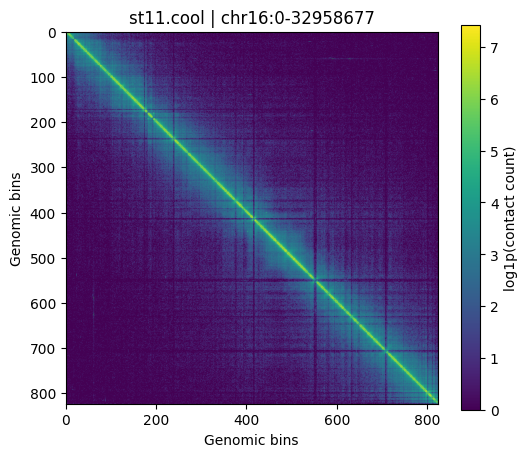

Saved image: /content/drive/MyDrive/HiC_Dataset_Explore/runimages/5_st11_chr16_0_32958677_7a12429a.png


In [18]:
# Plot the chromosome region as a Hi-C heatmap
plt.figure(figsize=(6, 5))
plt.imshow(np.log1p(matrix_region))
plt.colorbar(label="log1p(contact count)")
plt.title(f"{cool_file} | {region}")
plt.xlabel("Genomic bins")
plt.ylabel("Genomic bins")

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved image:", image_path)

In [ ]:
# Read the full chromosome as a sparse matrix
sparse_chr = c.matrix(balance=False, sparse=True).fetch(chrom)

print(f"Sparse matrix for {chrom}")
print("Shape:", sparse_chr.shape)
print("Non-zero contacts:", sparse_chr.nnz)
print("Data type:", sparse_chr.dtype)

print("\nFirst 20 non-zero contact counts:")
print(sparse_chr.data[:20])

Sparse matrix for chr16
Shape: (824, 824)
Non-zero contacts: 385625
Data type: int32

First 20 non-zero contact counts:
[ 18 428 255  98  58  41  55  40  50  23  21  19  17   8   8  16  12   9
  13  12]


# **BaseLine Inference**

In [ ]:
# Repo path
repo_path = "/content/drive/MyDrive/UGR-HiC/HiCForecast-main"
scripts_path = os.path.join(repo_path, "scripts")
# Model file path
model_path = "/content/drive/MyDrive/UGR-HiC/HiCForecast-main/trained_model/HiCForecast.pkl"
# Root folder for all baseline runs
runs_root = "/content/drive/MyDrive/UGR-HiC/runs"

In [21]:
# ============================================================
# TIMEPOINT MAP
# ============================================================

dataset_timepoints = {
    "1": ["PN5", "early_2cell", "late_2cell", "8cell", "ICM", "mESC_500"],
    "2": ["zygote", "2-cell", "4-cell", "8-cell", "E3.5", "E7.5"],
    "3": ["2-cell", "8-cell", "morula", "blastocyst", "6-week", "hESC"],
    "4": ["B", "Ba", "D2", "D4", "D6", "D8", "PSC"],
    "5": ["st11", "st12", "st13", "st14", "st18", "st27"],
    "6": ["s8", "s9", "s10", "s12", "s15", "s23"],
}

assert dataset_id in dataset_timepoints, f"Unknown dataset_id: {dataset_id}"
timepoints = dataset_timepoints[dataset_id]
dataset_folder = os.path.join(base_path, dataset_id)

print("Dataset folder:", dataset_folder)
print("Timepoints:", timepoints)
print("Chromosome:", chrom)

Dataset folder: /content/drive/MyDrive/HiC_Dataset_Explore/raw_original_datasets/5
Timepoints: ['st11', 'st12', 'st13', 'st14', 'st18', 'st27']
Chromosome: chr16


In [22]:
# Recheck to know all file name matches well
cool_files = sorted([f for f in os.listdir(dataset_folder) if f.endswith(".cool")])
print("Available .cool files:")
for f in cool_files:
    print("-", f)

Available .cool files:
- st11.cool
- st12.cool
- st13.cool
- st14.cool
- st18.cool
- st27.cool


In [ ]:
# ============================================================
# Create unique run folder -> for each chromosomes to distictly identify
# ============================================================

dataset_run_root = os.path.join(runs_root, f"dataset_{dataset_id}", chrom)
os.makedirs(dataset_run_root, exist_ok=True)

run_id = dataset_id  + "_" + cool_file + "_" + chrom + "_" + datetime.now().strftime("%Y")
run_dir = os.path.join(dataset_run_root, f"run_{run_id}")

processed_dir = os.path.join(run_dir, "processed")
pred_dir = os.path.join(run_dir, "predictions")
img_dir = os.path.join(run_dir, "images")
logs_dir = os.path.join(run_dir, "logs")

os.makedirs(run_dir, exist_ok=True)
os.makedirs(processed_dir, exist_ok=True)
os.makedirs(pred_dir, exist_ok=True)
os.makedirs(img_dir, exist_ok=True)
os.makedirs(logs_dir, exist_ok=True)

print("Run folder created:")
print(run_dir)

Run folder created:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026


In [24]:
# Final image path
image_name = f"{dataset_id}_{safe_cool_file}_{safe_region}_{unique_id}.png"
image_path = os.path.join(run_dir, image_name)

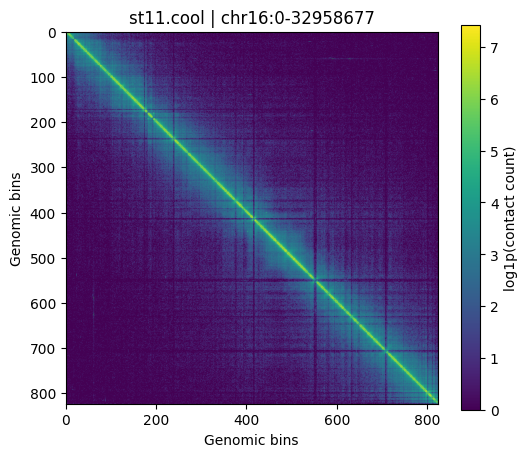

Saved image: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/5_st11_chr16_0_32958677_7a12429a.png


In [25]:
# Plot the chromosome region as a Hi-C heatmap
plt.figure(figsize=(6, 5))
plt.imshow(np.log1p(matrix_region))
plt.colorbar(label="log1p(contact count)")
plt.title(f"{cool_file} | {region}")
plt.xlabel("Genomic bins")
plt.ylabel("Genomic bins")

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved image:", image_path)

In [26]:
# Config save
config = {
    "dataset_id": dataset_id,
    "chrom": chrom,
    "cool_file_for_inspection_only": cool_file,
    "model_path": model_path,
    "dataset_folder": dataset_folder,
    "timepoints": timepoints,
    "run_dir": run_dir,
    "processed_dir": processed_dir,
    "pred_dir": pred_dir,
    "img_dir": img_dir,
}

config_path = os.path.join(run_dir, "run_config.json")
with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

print("Saved config:", config_path)

Saved config: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/run_config.json


In [27]:
# ============================================================
# RUN makedata.py
# ============================================================

makedata_cmd = [
    "python", "makedata.py",
    "--ficool_dir", dataset_folder + "/",
    "--sub_mat_n", "64",
    "--output_folder", processed_dir + "/",
    "--timepoints", *timepoints,
    "--chromosomes", chrom
]

print("Running makedata.py ...")
print(" ".join(makedata_cmd))

result = subprocess.run(
    makedata_cmd,
    cwd=scripts_path,
    capture_output=True,
    text=True
)

# Save logs
with open(os.path.join(logs_dir, "makedata_stdout.txt"), "w") as f:
    f.write(result.stdout)

with open(os.path.join(logs_dir, "makedata_stderr.txt"), "w") as f:
    f.write(result.stderr)

print("makedata return code:", result.returncode)

if result.returncode != 0:
    print("makedata.py failed!")
    print(result.stderr)
    raise RuntimeError("makedata.py failed")
else:
    print("makedata.py completed successfully.")

Running makedata.py ...
python makedata.py --ficool_dir /content/drive/MyDrive/HiC_Dataset_Explore/raw_original_datasets/5/ --sub_mat_n 64 --output_folder /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/ --timepoints st11 st12 st13 st14 st18 st27 --chromosomes chr16
makedata return code: 0
makedata.py completed successfully.


In [28]:
# generated files check
data_path = os.path.join(processed_dir, "input_patches", f"data_{chrom}_64.npy")
index_path = os.path.join(processed_dir, "input_patches", f"data_index_{chrom}_64.npy")
gt_path = os.path.join(processed_dir, f"data_gt_{chrom}_64.npy")

print("Expected generated files:")
print("data_path :", data_path, os.path.exists(data_path))
print("index_path:", index_path, os.path.exists(index_path))
print("gt_path   :", gt_path, os.path.exists(gt_path))

Expected generated files:
data_path : /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_chr16_64.npy True
index_path: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_index_chr16_64.npy True
gt_path   : /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/data_gt_chr16_64.npy True


In [29]:
# shape check
data = np.load(data_path)
index = np.load(index_path)
gt = np.load(gt_path)

print("Input patch data shape:", data.shape)
print("Index shape:", index.shape)
print("Ground truth shape:", gt.shape)

Input patch data shape: (254, 6, 64, 64)
Index shape: (254, 6, 2)
Ground truth shape: (6, 824, 824)


In [30]:
# ============================================================
# RUN inference.py
# ============================================================

output_prefix = os.path.join(pred_dir, f"HiCForecast_dataset{dataset_id}_{chrom}")

inference_cmd = [
    "python", "inference.py",
    "--max_HiC", "300",
    "--patch_size", "64",
    "--cut_off",
    "--model_path", model_path,
    "--data_path", data_path,
    "--output_path", output_prefix,
    "--file_index_path", index_path,
    "--no_batch_max",
    "--gt_path", gt_path
]

print("Running inference.py ...")
print(" ".join(inference_cmd))

result = subprocess.run(
    inference_cmd,
    cwd=scripts_path,
    capture_output=True,
    text=True
)

# Save logs
with open(os.path.join(logs_dir, "inference_stdout.txt"), "w") as f:
    f.write(result.stdout)

with open(os.path.join(logs_dir, "inference_stderr.txt"), "w") as f:
    f.write(result.stderr)

print("inference return code:", result.returncode)

if result.returncode != 0:
    print("inference.py failed!")
    print(result.stderr)
    raise RuntimeError("inference.py failed")
else:
    print("inference.py completed successfully.")

Running inference.py ...
python inference.py --max_HiC 300 --patch_size 64 --cut_off --model_path /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/trained_model/HiCForecast.pkl --data_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_chr16_64.npy --output_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/predictions/HiCForecast_dataset5_chr16 --file_index_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_index_chr16_64.npy --no_batch_max --gt_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/data_gt_chr16_64.npy
inference return code: 0
inference.py completed successfully.


In [31]:
print("Using existing run_dir:", run_dir)
print("Using existing img_dir:", img_dir)

metrics_dir = os.path.join(run_dir, "metrics")
os.makedirs(metrics_dir, exist_ok=True)
os.makedirs(img_dir, exist_ok=True)

Using existing run_dir: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026
Using existing img_dir: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/images


In [32]:
# prediction load
pred_path = output_prefix + ".npy"

print("Prediction file:", pred_path)
print("Exists:", os.path.exists(pred_path))

pred = np.load(pred_path)
print("Prediction shape:", pred.shape)

Prediction file: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/predictions/HiCForecast_dataset5_chr16.npy
Exists: True
Prediction shape: (3, 824, 824)


In [33]:
# Save copies into run folder for easier later use
np.save(os.path.join(run_dir, "pred_baseline.npy"), pred)
np.save(os.path.join(run_dir, f"gt_{chrom}.npy"), gt)
print("Saved pred copy:", os.path.join(run_dir, "pred_baseline.npy"))
print("Saved gt copy:", os.path.join(run_dir, f"gt_{chrom}.npy"))

Saved pred copy: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/pred_baseline.npy
Saved gt copy: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/gt_chr16.npy


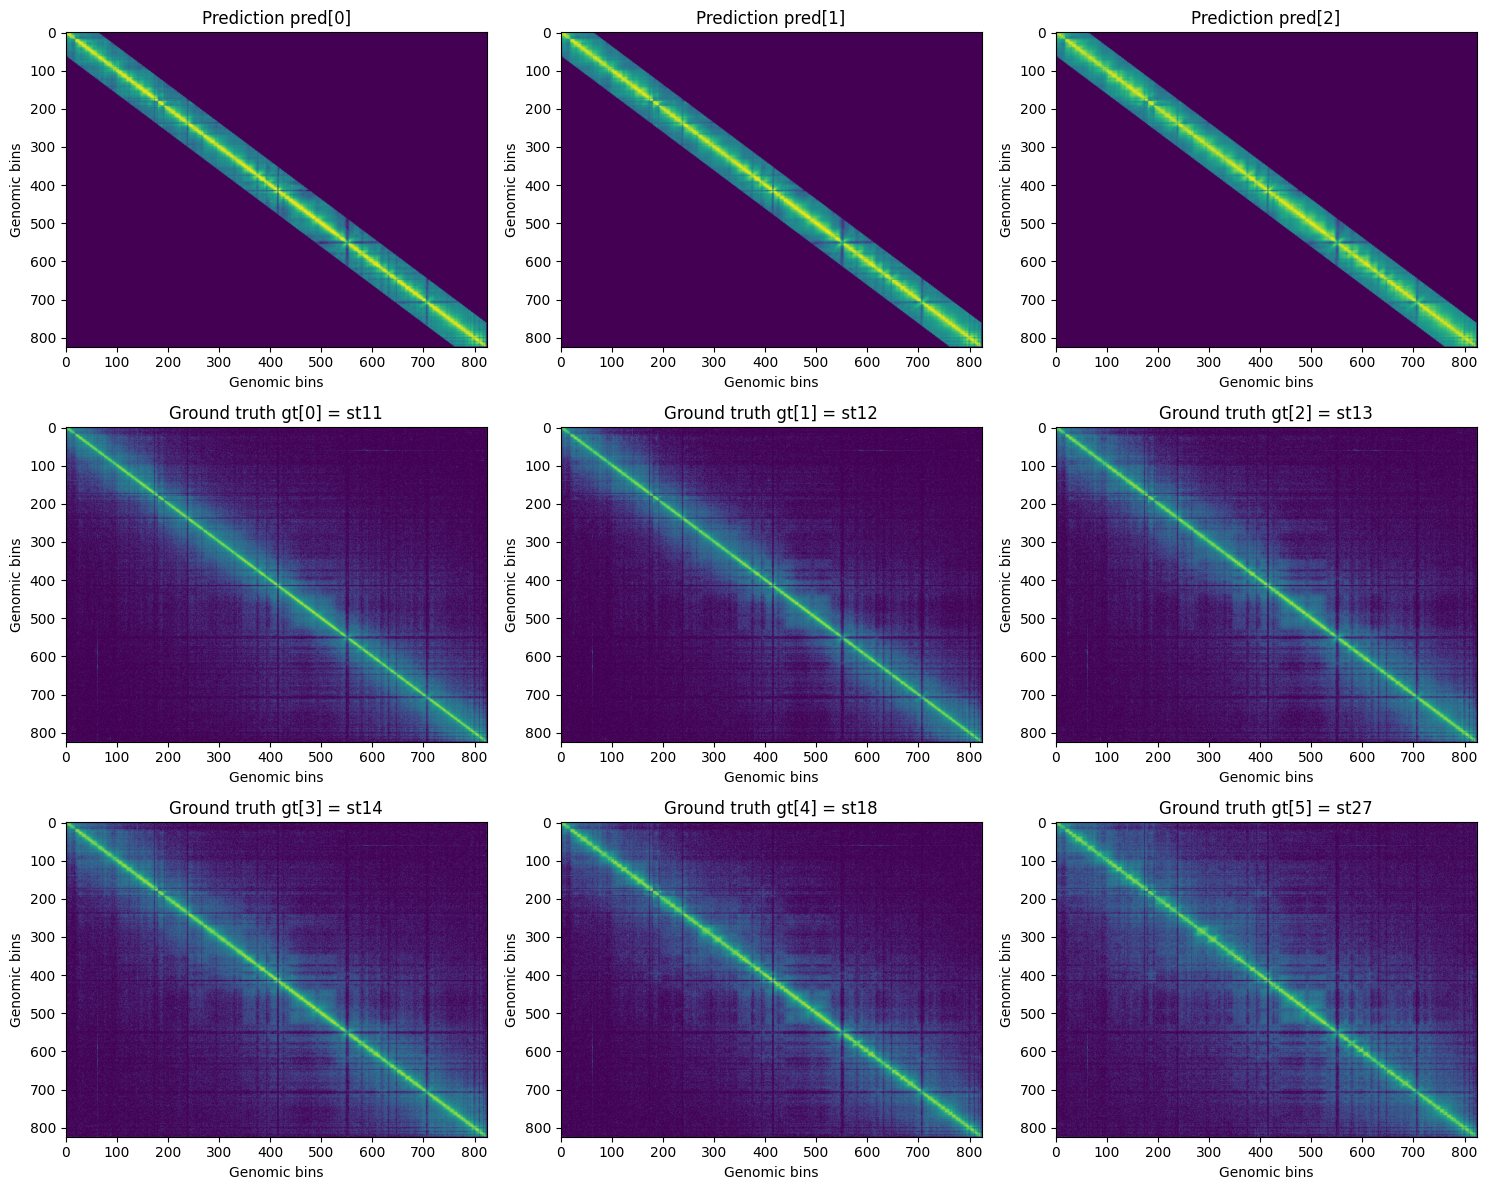

Saved combined prediction/GT figure: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/images/fig_predictions_and_all_gt_chr16.png


In [34]:
# ============================================================
# Visual check: Predictions and GT maps together
# ============================================================

if "timepoints" in globals():
    gt_names = timepoints
else:
    gt_names = [f"gt[{i}]" for i in range(gt.shape[0])]

total_maps = pred.shape[0] + gt.shape[0]

cols = 3
rows = int(np.ceil(total_maps / cols))

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
axes = axes.flatten()

plot_idx = 0

# Plot predictions first
for i in range(pred.shape[0]):
    axes[plot_idx].imshow(np.log1p(pred[i]), aspect="auto")
    axes[plot_idx].set_title(f"Prediction pred[{i}]")
    axes[plot_idx].set_xlabel("Genomic bins")
    axes[plot_idx].set_ylabel("Genomic bins")
    plot_idx += 1

# Plot gt maps after predictions
for i in range(gt.shape[0]):
    name = gt_names[i] if i < len(gt_names) else f"gt[{i}]"
    axes[plot_idx].imshow(np.log1p(gt[i]), aspect="auto")
    axes[plot_idx].set_title(f"Ground truth gt[{i}] = {name}")
    axes[plot_idx].set_xlabel("Genomic bins")
    axes[plot_idx].set_ylabel("Genomic bins")
    plot_idx += 1

for j in range(plot_idx, len(axes)):
    axes[j].axis("off")

plt.tight_layout()

combined_fig_path = os.path.join(img_dir, f"fig_predictions_and_all_gt_{chrom}.png")
plt.savefig(combined_fig_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved combined prediction/GT figure:", combined_fig_path)

In [35]:
# ============================================================
# Metric helper functions
# ============================================================

def pcc(a, b, eps=1e-8):
    a = np.asarray(a).ravel()
    b = np.asarray(b).ravel()

    mask = np.isfinite(a) & np.isfinite(b)
    a = a[mask]
    b = b[mask]

    if len(a) == 0:
        return np.nan

    a = a - a.mean()
    b = b - b.mean()

    denom = np.sqrt(np.sum(a ** 2)) * np.sqrt(np.sum(b ** 2)) + eps
    return float(np.sum(a * b) / denom)


def safe_data_range(x):
    x = np.asarray(x)
    data_range = float(np.nanmax(x) - np.nanmin(x))

    if data_range == 0 or not np.isfinite(data_range):
        data_range = 1.0

    return data_range

In [36]:
# ------------------------------------------------------------
# PCC similarity heatmap: pred[0..2] vs all gt timesteps
# ------------------------------------------------------------

T = gt.shape[0]
sim = np.zeros((pred.shape[0], T))

for i in range(pred.shape[0]):
    for t in range(T):
        sim[i, t] = pcc(pred[i], gt[t])

best = sim.argmax(axis=1)

print("Best GT match for each pred:", best.tolist())

Best GT match for each pred: [4, 4, 5]


In [37]:
# ------------------------------------------------------------
# Best GT mapping
# Uses highest PCC from sim matrix
# ------------------------------------------------------------

best_gt_indices = best   # best came from: sim.argmax(axis=1)

best_stage_names = [timepoints[i] for i in best_gt_indices]

print("\nBest GT mapping based on highest PCC:")
for i, gt_idx in enumerate(best_gt_indices):
    print(
        f"pred[{i}] -> gt[{gt_idx}] = {best_stage_names[i]} "
        f"| PCC = {sim[i, gt_idx]:.4f}"
    )


Best GT mapping based on highest PCC:
pred[0] -> gt[4] = st18 | PCC = 0.9237
pred[1] -> gt[4] = st18 | PCC = 0.9058
pred[2] -> gt[5] = st27 | PCC = 0.8750


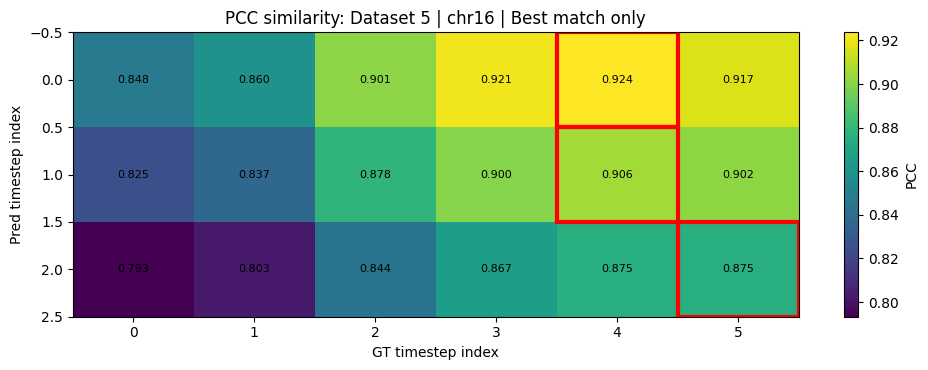

Saved heatmap: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/images/fig_similarity_heatmap_best_only.png


In [38]:
# printing best gt
plt.figure(figsize=(10, 3.8))
im = plt.imshow(sim, aspect="auto")
plt.colorbar(im, label="PCC")

plt.xlabel("GT timestep index")
plt.ylabel("Pred timestep index")
plt.title(f"PCC similarity: Dataset {dataset_id} | {chrom} | Best match only")

for i in range(sim.shape[0]):
    for j in range(sim.shape[1]):
        plt.text(
            j, i, f"{sim[i, j]:.3f}",
            ha="center",
            va="center",
            fontsize=8,
            color="black"
        )

ax = plt.gca()

for i, j in enumerate(best_gt_indices):
    ax.add_patch(
        Rectangle(
            (j - 0.5, i - 0.5),
            1,
            1,
            fill=False,
            edgecolor="red",
            linewidth=3
        )
    )

plt.tight_layout()

heatmap_path = os.path.join(img_dir, "fig_similarity_heatmap_best_only.png")
plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved heatmap:", heatmap_path)

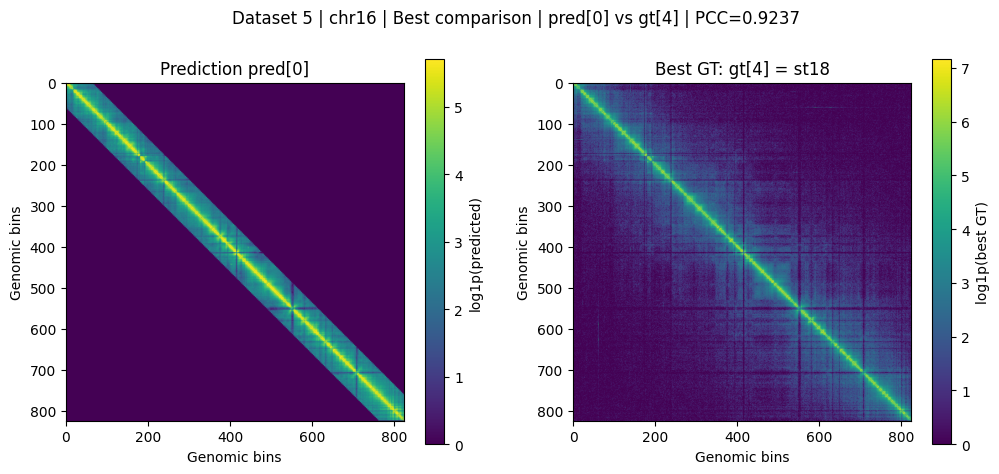

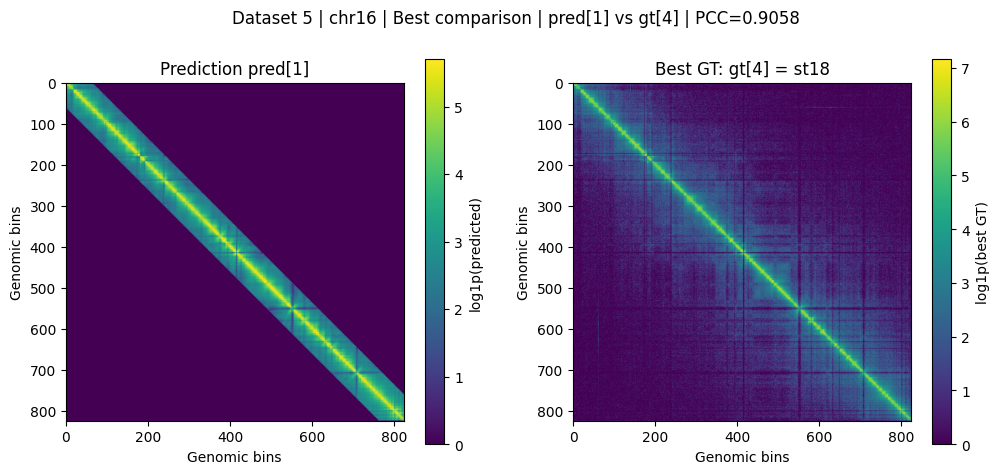

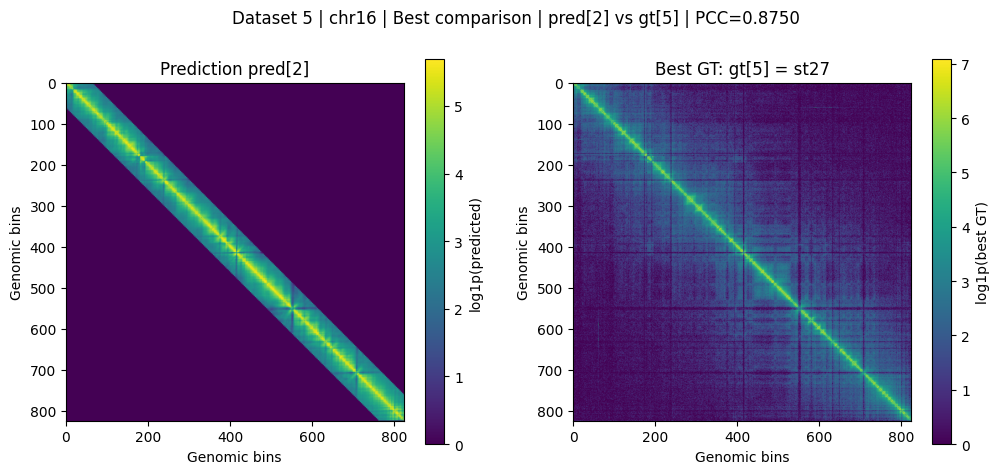

In [39]:
# ------------------------------------------------------------
# Best side-by-side comparison images
# ------------------------------------------------------------

for i, t in enumerate(best_gt_indices):
    t = int(t)
    matched_stage = timepoints[t]

    image_path = os.path.join(
        img_dir,
        f"best_compare_pred{i}_gt{t}_{matched_stage}.png"
    )

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(np.log1p(pred[i]))
    plt.colorbar(label="log1p(predicted)")
    plt.title(f"Prediction pred[{i}]")
    plt.xlabel("Genomic bins")
    plt.ylabel("Genomic bins")

    plt.subplot(1, 2, 2)
    plt.imshow(np.log1p(gt[t]))
    plt.colorbar(label="log1p(best GT)")
    plt.title(f"Best GT: gt[{t}] = {matched_stage}")
    plt.xlabel("Genomic bins")
    plt.ylabel("Genomic bins")

    plt.suptitle(
        f"Dataset {dataset_id} | {chrom} | Best comparison | "
        f"pred[{i}] vs gt[{t}] | PCC={sim[i, t]:.4f}"
    )

    plt.savefig(image_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

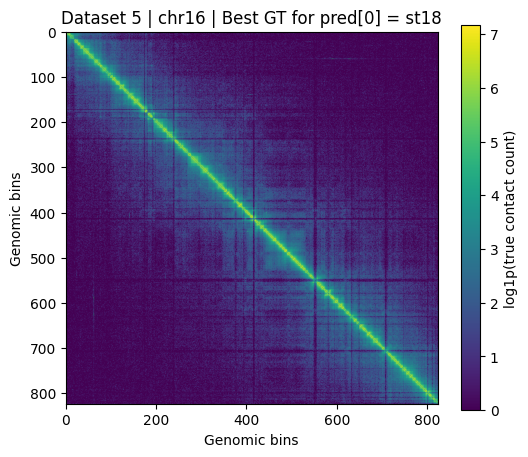

Saved: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/images/best_gt_pred0_gt4_st18.png


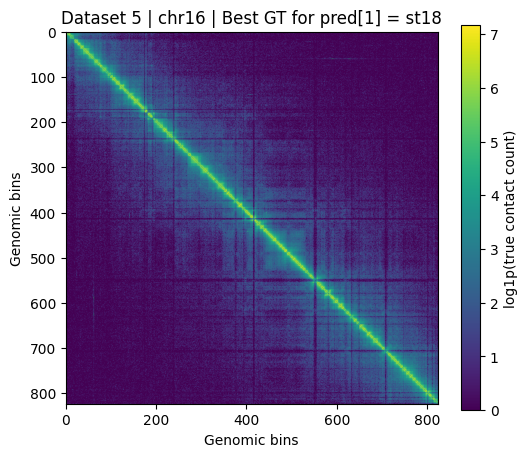

Saved: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/images/best_gt_pred1_gt4_st18.png


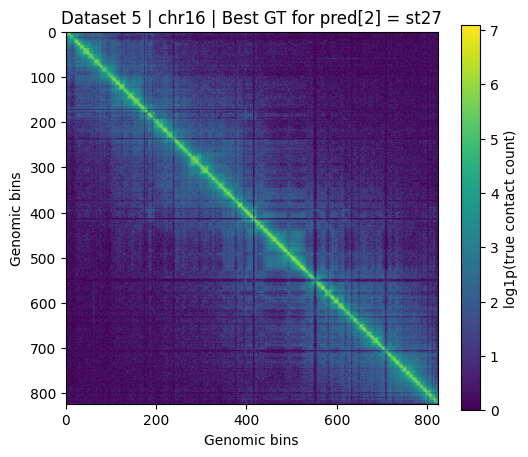

Saved: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/images/best_gt_pred2_gt5_st27.png


In [40]:
# ------------------------------------------------------------
# Best-matched ground truth images
# ------------------------------------------------------------

for i, gt_idx in enumerate(best_gt_indices):
    gt_idx = int(gt_idx)
    matched_stage = timepoints[gt_idx]

    image_path = os.path.join(
        img_dir,
        f"best_gt_pred{i}_gt{gt_idx}_{matched_stage}.png"
    )

    plt.figure(figsize=(6, 5))
    plt.imshow(np.log1p(gt[gt_idx]))
    plt.colorbar(label="log1p(true contact count)")
    plt.title(
        f"Dataset {dataset_id} | {chrom} | Best GT for pred[{i}] = {matched_stage}"
    )
    plt.xlabel("Genomic bins")
    plt.ylabel("Genomic bins")

    plt.savefig(image_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved:", image_path)

In [ ]:
# Best GT match from baseline matching
gt_match = [int(x) for x in best.tolist()]

# ------------------------------------------------------------
# Compute baseline metrics
# ------------------------------------------------------------

baseline_metric_rows = []

for h, gt_idx in enumerate(gt_match):
    pred_h = pred[h]
    gt_h = gt[gt_idx]

    data_range = safe_data_range(gt_h)

    baseline_metric_rows.append({
        "Horizon": f"Pred{h}",
        "Matched GT": f"GT{gt_idx}",
        "Matched GT Index": gt_idx,
        "Matched Stage": timepoints[gt_idx],

        "PCC": pcc(pred_h, gt_h),
        "SSIM": ssim_metric(pred_h, gt_h, data_range=data_range),
        "PSNR": psnr_metric(gt_h, pred_h, data_range=data_range),
        "MAE": mean_absolute_error(gt_h.ravel(), pred_h.ravel()),
        "MSE": mean_squared_error(gt_h.ravel(), pred_h.ravel()),
    })

baseline_metrics_df = pd.DataFrame(baseline_metric_rows)

display(baseline_metrics_df.round(4))

,Horizon,Matched GT,Matched GT Index,Matched Stage,PCC,SSIM,PSNR,MAE,MSE
0,Pred0,GT4,4,st18,0.9237,0.9653,36.2321,3.4700,396.8667
1,Pred1,GT4,4,st18,0.9058,0.9609,35.6533,3.8550,453.4434
2,Pred2,GT5,5,st27,0.8750,0.9324,36.7208,4.5668,303.3411


In [42]:
# ------------------------------------------------------------
# Save baseline metrics CSV for later comparison
# ------------------------------------------------------------

baseline_metrics_path = os.path.join(
    metrics_dir,
    f"baseline_metrics_dataset{dataset_id}_{chrom}.csv"
)

baseline_metrics_df.to_csv(baseline_metrics_path, index=False)

print("Saved baseline metrics to:")
print(baseline_metrics_path)

Saved baseline metrics to:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/metrics/baseline_metrics_dataset5_chr16.csv


# **Experiment 1A: Repeated Deterministic Inference**

In [43]:
# ============================================================
# EXPERIMENT 1A: Repeated Deterministic Inference
# ============================================================
K_REPEAT = 10

exp1a_dir = os.path.join(run_dir, "exp1A_repeated_deterministic")
exp1a_pred_dir = os.path.join(exp1a_dir, "repeat_predictions")
exp1a_logs_dir = os.path.join(exp1a_dir, "logs")
exp1a_results_dir = os.path.join(exp1a_dir, "results")

os.makedirs(exp1a_dir, exist_ok=True)
os.makedirs(exp1a_pred_dir, exist_ok=True)
os.makedirs(exp1a_logs_dir, exist_ok=True)
os.makedirs(exp1a_results_dir, exist_ok=True)

print("Experiment 1A folder:")
print(exp1a_dir)
print("K_REPEAT:", K_REPEAT)
print("Dataset:", dataset_id)
print("Chromosome:", chrom)

Experiment 1A folder:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1A_repeated_deterministic
K_REPEAT: 10
Dataset: 5
Chromosome: chr16


In [ ]:
# ============================================================
# Run repeated deterministic inference, Run same checkpoint K times
# ============================================================
repeat_pred_paths = []

for r in range(K_REPEAT):
    repeat_id = f"repeat_{r+1:02d}"
    repeat_output_prefix = os.path.join(exp1a_pred_dir, f"pred_{repeat_id}_dataset{dataset_id}_{chrom}")

    repeat_cmd = [
        "python", "inference.py",
        "--max_HiC", "300",
        "--patch_size", "64",
        "--cut_off",
        "--model_path", model_path,
        "--data_path", data_path,
        "--output_path", repeat_output_prefix,
        "--file_index_path", index_path,
        "--no_batch_max",
        "--gt_path", gt_path
    ]

    print(f"\nRunning {repeat_id} ...")
    print(" ".join(repeat_cmd))

    result = subprocess.run(
        repeat_cmd,
        cwd=scripts_path,
        capture_output=True,
        text=True
    )

    # Save logs for each repeat
    with open(os.path.join(exp1a_logs_dir, f"{repeat_id}_stdout.txt"), "w") as f:
        f.write(result.stdout)

    with open(os.path.join(exp1a_logs_dir, f"{repeat_id}_stderr.txt"), "w") as f:
        f.write(result.stderr)

    print("Return code:", result.returncode)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"Experiment 1A failed at {repeat_id}")

    pred_path = repeat_output_prefix + ".npy"
    if not os.path.exists(pred_path):
        raise FileNotFoundError(f"Prediction file not found: {pred_path}")

    repeat_pred_paths.append(pred_path)

print("\nAll repeated inference runs completed.")
print("Saved repeated predictions:")
for p in repeat_pred_paths:
    print(p)


Running repeat_01 ...
python inference.py --max_HiC 300 --patch_size 64 --cut_off --model_path /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/trained_model/HiCForecast.pkl --data_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_chr16_64.npy --output_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1A_repeated_deterministic/repeat_predictions/pred_repeat_01_dataset5_chr16 --file_index_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_index_chr16_64.npy --no_batch_max --gt_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/data_gt_chr16_64.npy
Return code: 0

Running repeat_02 ...
python inference.py --max_HiC 300 --patch_size 64 --cut_off --model_path /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/trained_mod

In [ ]:
# ============================================================
# Stack repeated predictions and compute mean/std
# Shape: repeated_preds = (K, 3, N, N)
# ============================================================

repeat_preds = [np.load(p) for p in repeat_pred_paths]
repeat_preds = np.stack(repeat_preds, axis=0)

print("Repeated predictions shape:", repeat_preds.shape)

repeat_mean = repeat_preds.mean(axis=0)
repeat_std = repeat_preds.std(axis=0)

print("Repeat mean shape:", repeat_mean.shape)
print("Repeat std shape:", repeat_std.shape)

mean_path = os.path.join(exp1a_results_dir, f"exp1A_repeat_mean_dataset{dataset_id}_{chrom}.npy")
std_path = os.path.join(exp1a_results_dir, f"exp1A_repeat_std_dataset{dataset_id}_{chrom}.npy")

np.save(mean_path, repeat_mean)
np.save(std_path, repeat_std)

print("Saved repeat mean:", mean_path)
print("Saved repeat std:", std_path)

Repeated predictions shape: (10, 3, 824, 824)
Repeat mean shape: (3, 824, 824)
Repeat std shape: (3, 824, 824)
Saved repeat mean: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1A_repeated_deterministic/results/exp1A_repeat_mean_dataset5_chr16.npy
Saved repeat std: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1A_repeated_deterministic/results/exp1A_repeat_std_dataset5_chr16.npy


In [ ]:
# ============================================================
# Compare repeated mean with baseline prediction
# ============================================================

if "pred" in globals():
    baseline_pred = pred
    print("Using baseline prediction from variable: pred")
else:
    baseline_path = output_prefix + ".npy"
    baseline_pred = np.load(baseline_path)
    print("Loaded baseline prediction:", baseline_path)

print("Baseline prediction shape:", baseline_pred.shape)

diff = np.abs(repeat_mean - baseline_pred)

print("Mean absolute difference between repeat mean and baseline:", diff.mean())
print("Max absolute difference between repeat mean and baseline:", diff.max())
print("95th percentile difference:", np.percentile(diff, 95))

Using baseline prediction from variable: pred
Baseline prediction shape: (3, 824, 824)
Mean absolute difference between repeat mean and baseline: 1.6673747755912267e-06
Max absolute difference between repeat mean and baseline: 0.004477500915525567
95th percentile difference: 1.0466575622203322e-05


In [ ]:
# ============================================================
# Experiment 1A summary table -> it can support paper claim: repeated deterministic inference gives near-zero uncertainty.
# ============================================================

rows = []

for h in range(repeat_std.shape[0]):
    sigma_h = repeat_std[h]
    diff_h = np.abs(repeat_mean[h] - baseline_pred[h])

    rows.append({
        "Dataset": dataset_id,
        "Chromosome": chrom,
        "Horizon": f"Pred{h}",
        "Mean sigma": float(np.mean(sigma_h)),
        "Median sigma": float(np.median(sigma_h)),
        "95th sigma": float(np.percentile(sigma_h, 95)),
        "Max sigma": float(np.max(sigma_h)),
        "MAE repeat_mean vs baseline": float(np.mean(diff_h)),
        "Max diff repeat_mean vs baseline": float(np.max(diff_h)),
    })

exp1a_df = pd.DataFrame(rows)

display(exp1a_df)

csv_path = os.path.join(exp1a_results_dir, f"exp1A_deterministic_repeat_summary_dataset{dataset_id}_{chrom}.csv")
exp1a_df.to_csv(csv_path, index=False)

print("Saved Experiment 1A summary:")
print(csv_path)

,Dataset,Chromosome,Horizon,Mean sigma,Median sigma,95th sigma,Max sigma,MAE repeat_mean vs baseline,Max diff repeat_mean vs baseline
0,5,chr16,Pred0,0.000001,0.0,0.000007,0.000342,9.345734e-07,0.000312
1,5,chr16,Pred1,0.000002,0.0,0.000015,0.001058,2.013365e-06,0.004478
2,5,chr16,Pred2,0.000002,0.0,0.000016,0.001372,2.054186e-06,0.002191


Saved Experiment 1A summary:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1A_repeated_deterministic/results/exp1A_deterministic_repeat_summary_dataset5_chr16.csv


In [48]:
# ============================================================
# Save Experiment 1A run metadata
# ============================================================

exp1a_info = {
    "experiment": "1A_repeated_deterministic_inference",
    "dataset_id": dataset_id,
    "chromosome": chrom,
    "K_REPEAT": K_REPEAT,
    "model_path": model_path,
    "data_path": data_path,
    "index_path": index_path,
    "gt_path": gt_path,
    "run_dir": run_dir,
    "exp1a_dir": exp1a_dir,
    "created_at": datetime.now().isoformat(),
    "repeat_prediction_files": repeat_pred_paths,
    "repeat_mean_path": mean_path,
    "repeat_std_path": std_path,
    "summary_csv": csv_path,
}

json_path = os.path.join(exp1a_results_dir, f"exp1A_run_info_dataset{dataset_id}_{chrom}.json")

with open(json_path, "w") as f:
    json.dump(exp1a_info, f, indent=2)

print("Saved Experiment 1A metadata:")
print(json_path)

Saved Experiment 1A metadata:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1A_repeated_deterministic/results/exp1A_run_info_dataset5_chr16.json


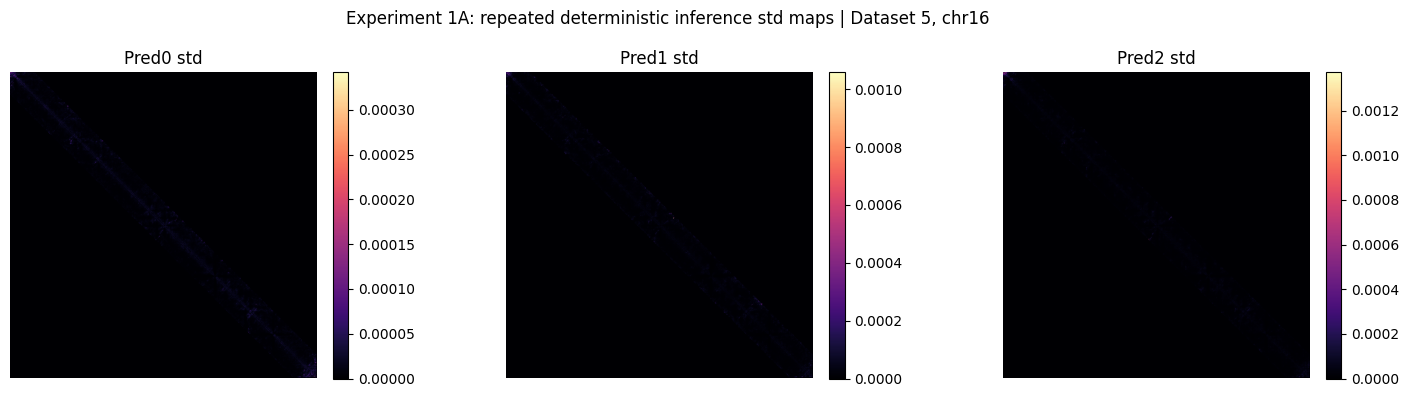

Saved figure:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1A_repeated_deterministic/results/exp1A_std_maps_dataset5_chr16.png


In [ ]:
# ============================================================
# visualization: repeated-inference std maps
# ============================================================

fig, axes = plt.subplots(1, repeat_std.shape[0], figsize=(15, 4))

for h in range(repeat_std.shape[0]):
    im = axes[h].imshow(repeat_std[h], cmap="magma")
    axes[h].set_title(f"Pred{h} std")
    axes[h].axis("off")
    plt.colorbar(im, ax=axes[h], fraction=0.046, pad=0.04)

plt.suptitle(f"Experiment 1A: repeated deterministic inference std maps | Dataset {dataset_id}, {chrom}")
plt.tight_layout()

fig_path = os.path.join(exp1a_results_dir, f"exp1A_std_maps_dataset{dataset_id}_{chrom}.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved figure:")
print(fig_path)

# **Experiment 1B: Seeded Checkpoint Ensemble**

In [50]:
# ============================================================
# EXPERIMENT 1B: Seeded Checkpoint Ensemble
# ============================================================

SEEDS = [11, 22, 33]
M_ENSEMBLE = len(SEEDS)

exp1b_dir = os.path.join(run_dir, "exp1B_seeded_checkpoint_ensemble")
exp1b_ckpt_dir = os.path.join(exp1b_dir, "checkpoints")
exp1b_pred_dir = os.path.join(exp1b_dir, "member_predictions")
exp1b_results_dir = os.path.join(exp1b_dir, "results")
exp1b_logs_dir = os.path.join(exp1b_dir, "logs")
exp1b_img_dir = os.path.join(exp1b_dir, "images")
exp1b_train_patch_dir = os.path.join(exp1b_dir, "train_patches")

for d in [
    exp1b_dir,
    exp1b_ckpt_dir,
    exp1b_pred_dir,
    exp1b_results_dir,
    exp1b_logs_dir,
    exp1b_img_dir,
    exp1b_train_patch_dir,
]:
    os.makedirs(d, exist_ok=True)

print("Experiment 1B folders created:")
print("1B root:", exp1b_dir)
print("checkpoints:", exp1b_ckpt_dir)
print("train_patches:", exp1b_train_patch_dir)
print("member_predictions:", exp1b_pred_dir)
print("results:", exp1b_results_dir)
print("logs:", exp1b_logs_dir)
print("images:", exp1b_img_dir)

Experiment 1B folders created:
1B root: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble
checkpoints: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/checkpoints
train_patches: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/train_patches
member_predictions: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/member_predictions
results: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/results
logs: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/logs
images: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2

In [51]:
# ============================================================
# Copy current chromosome patch file into 1B train_patches
# ============================================================

PATCH_SIZE = 64

DATA_VAL = data_path
VAL_GT = gt_path
VAL_INDEX = index_path
PRETRAINED = model_path

train_patch_dst = os.path.join(
    exp1b_train_patch_dir,
    f"data_{chrom}_{PATCH_SIZE}.npy"
)

shutil.copy2(DATA_VAL, train_patch_dst)

print("Copied training patch file:")
print("From:", DATA_VAL)
print("To  :", train_patch_dst)
print("Exists:", os.path.exists(train_patch_dst))

Copied training patch file:
From: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_chr16_64.npy
To  : /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/train_patches/data_chr16_64.npy
Exists: True


In [52]:
# ============================================================
# Patch train.py into train_seeded.py
# ============================================================

train_path = Path(os.path.join(scripts_path, "train.py"))
seeded_path = Path(os.path.join(scripts_path, "train_seeded.py"))

print("Original train.py:", train_path)
print("Seeded train script:", seeded_path)
print("train.py exists:", train_path.exists())

text = train_path.read_text()

if "parser.add_argument('--seed'" not in text:
    old = (
        "parser.add_argument('--batch_max', action='store_true')\n"
        "parser.add_argument('--no_batch_max', dest='batch_max', action='store_false')"
    )
    new = (
        "parser.add_argument('--batch_max', action='store_true')\n"
        "parser.add_argument('--no_batch_max', dest='batch_max', action='store_false')\n"
        "parser.add_argument('--seed', default=1234, type=int)\n"
        "parser.add_argument('--output_tag', default='', type=str)"
    )
    if old not in text:
        raise RuntimeError("Could not find parser batch_max block in train.py.")
    text = text.replace(old, new)

old_seed_block = (
    "seed = 1234\n"
    "random.seed(seed)\n"
    "np.random.seed(seed)\n"
    "torch.manual_seed(seed)\n"
    "torch.cuda.manual_seed_all(seed)\n"
    "torch.backends.cudnn.benchmark = True"
)

new_seed_block = (
    "seed = args.seed\n"
    "random.seed(seed)\n"
    "np.random.seed(seed)\n"
    "torch.manual_seed(seed)\n"
    "torch.cuda.manual_seed_all(seed)\n"
    "torch.backends.cudnn.benchmark = False\n"
    "torch.backends.cudnn.deterministic = True"
)

if old_seed_block in text:
    text = text.replace(old_seed_block, new_seed_block)
else:
    print("Warning: original fixed seed block not found.")

old_time_block = "current_time = get_timestamp()\ncode_test = args.code_test"
new_time_block = (
    "current_time = get_timestamp()\n"
    "tag_suffix = ('_' + args.output_tag) if args.output_tag else ''\n"
    "code_test = args.code_test"
)

if old_time_block in text:
    text = text.replace(old_time_block, new_time_block)
else:
    print("Warning: current_time/code_test block not found.")

text = text.replace(
    "output_folder = 'HiCForecast_train_{}_test'.format(current_time)",
    "output_folder = 'HiCForecast_train_{}{}_test'.format(current_time, tag_suffix)"
)

text = text.replace(
    "output_folder = 'HiCForecast_train_{}'.format(current_time)",
    "output_folder = 'HiCForecast_train_{}{}'.format(current_time, tag_suffix)"
)

seeded_path.write_text(text)

print("Wrote train_seeded.py successfully.")

Original train.py: /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/scripts/train.py
Seeded train script: /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/scripts/train_seeded.py
train.py exists: True
Wrote train_seeded.py successfully.


In [53]:
# ============================================================
# Verify train_seeded.py patch
# ============================================================

seeded_text = seeded_path.read_text()

required_strings = [
    "parser.add_argument('--seed'",
    "parser.add_argument('--output_tag'",
    "seed = args.seed",
    "tag_suffix = ('_' + args.output_tag) if args.output_tag else ''",
    "torch.backends.cudnn.deterministic = True"
]

print("Patch verification:")
for s in required_strings:
    print(f"{s}:", s in seeded_text)

missing = [s for s in required_strings if s not in seeded_text]
if missing:
    raise RuntimeError(f"Patch incomplete. Missing: {missing}")
else:
    print("train_seeded.py patch looks correct.")

Patch verification:
parser.add_argument('--seed': True
parser.add_argument('--output_tag': True
seed = args.seed: True
tag_suffix = ('_' + args.output_tag) if args.output_tag else '': True
torch.backends.cudnn.deterministic = True: True
train_seeded.py patch looks correct.


In [54]:
# ============================================================
# Train seeded ensemble members
# ============================================================

FT_EPOCHS = 5
BATCH_SIZE = 8
MAX_HIC = 300
DEVICE_ID = 0
LOSS_NAME = "single_channel_L1_no_vgg"
PATCH_SIZE = 64

DATA_TRAIN_DIR = exp1b_train_patch_dir + "/"

seeded_checkpoint_paths = {}

for i, seed in enumerate(SEEDS):
    tag = f"dataset{dataset_id}_{chrom}_seed{seed}"
    port = 29501 + i

    standard_ckpt = os.path.join(
        exp1b_ckpt_dir,
        f"HiCForecast_dataset{dataset_id}_{chrom}_seed{seed}.pkl"
    )

    if os.path.exists(standard_ckpt):
        print(f"Checkpoint already exists for seed {seed}. Skipping training.")
        seeded_checkpoint_paths[seed] = standard_ckpt
        continue

    print("\n" + "=" * 80)
    print(f"Training ensemble member with seed {seed}")
    print("=" * 80)

    train_cmd = [
        "torchrun",
        "--nproc_per_node=1",
        f"--master_port={port}",
        "train_seeded.py",
        "--epoch", str(1 + FT_EPOCHS),
        "--max_HiC", str(MAX_HIC),
        "--patch_size", str(PATCH_SIZE),
        "--num_gpu", "1",
        "--device_id", str(DEVICE_ID),
        "--num_workers", "1",
        "--batch_size", str(BATCH_SIZE),
        "--lr_scale", "1.0",
        "--block_num", "9",
        "--data_val_path", DATA_VAL,
        "--data_train_path", DATA_TRAIN_DIR,
        "--resume_path", PRETRAINED,
        "--resume_epoch", "1",
        "--early_stoppage_epochs", "5",
        "--early_stoppage_start", "400",
        "--loss", LOSS_NAME,
        "--val_gt_path", VAL_GT,
        "--val_file_index_path", VAL_INDEX,
        "--no_cut_off",
        "--dynamics",
        "--no_max_cut_off",
        "--no_batch_max",
        "--seed", str(seed),
        "--output_tag", tag,
        "--no_code_test",
    ]

    print("Running command:")
    print(" ".join(train_cmd))

    result = subprocess.run(
        train_cmd,
        cwd=scripts_path,
        capture_output=True,
        text=True
    )

    os.makedirs(exp1b_logs_dir, exist_ok=True)

    stdout_path = os.path.join(exp1b_logs_dir, f"train_seed{seed}_stdout.txt")
    stderr_path = os.path.join(exp1b_logs_dir, f"train_seed{seed}_stderr.txt")

    with open(stdout_path, "w", encoding="utf-8") as f:
        f.write(result.stdout)

    with open(stderr_path, "w", encoding="utf-8") as f:
        f.write(result.stderr)

    print("Return code:", result.returncode)
    print("Saved stdout:", stdout_path)
    print("Saved stderr:", stderr_path)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"Training failed for seed {seed}")

print("Seeded training step completed.")


Training ensemble member with seed 11
Running command:
torchrun --nproc_per_node=1 --master_port=29501 train_seeded.py --epoch 6 --max_HiC 300 --patch_size 64 --num_gpu 1 --device_id 0 --num_workers 1 --batch_size 8 --lr_scale 1.0 --block_num 9 --data_val_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_chr16_64.npy --data_train_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/train_patches/ --resume_path /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/trained_model/HiCForecast.pkl --resume_epoch 1 --early_stoppage_epochs 5 --early_stoppage_start 400 --loss single_channel_L1_no_vgg --val_gt_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/data_gt_chr16_64.npy --val_file_index_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr1

In [55]:
# ============================================================
# Find latest checkpoint for each seed
# ============================================================

def latest_run_for_tag(tag):
    pattern = os.path.join(scripts_path, f"HiCForecast_train_*_{tag}")
    runs = sorted(glob.glob(pattern))
    if not runs:
        raise FileNotFoundError(f"No training run found for tag: {tag}")
    return runs[-1]

def latest_cache_checkpoint(run_dir):
    ckpts = glob.glob(os.path.join(run_dir, "cache", "HiCForecast_*.pkl"))
    if not ckpts:
        raise FileNotFoundError(f"No cache checkpoints found in: {run_dir}")

    def epoch_num(path):
        m = re.search(r"HiCForecast_(\d+)\.pkl$", path)
        return int(m.group(1)) if m else -1

    return sorted(ckpts, key=epoch_num)[-1]

seeded_checkpoint_paths = {}

for seed in SEEDS:
    standard_ckpt = os.path.join(
        exp1b_ckpt_dir,
        f"HiCForecast_dataset{dataset_id}_{chrom}_seed{seed}.pkl"
    )

    if os.path.exists(standard_ckpt):
        seeded_checkpoint_paths[seed] = standard_ckpt
        print(f"Using existing checkpoint for seed {seed}: {standard_ckpt}")
        continue

    tag = f"dataset{dataset_id}_{chrom}_seed{seed}"
    run_found = latest_run_for_tag(tag)
    ckpt_found = latest_cache_checkpoint(run_found)

    shutil.copy2(ckpt_found, standard_ckpt)
    seeded_checkpoint_paths[seed] = standard_ckpt

    print("\nSeed:", seed)
    print("Training run:", run_found)
    print("Original checkpoint:", ckpt_found)
    print("Copied checkpoint:", standard_ckpt)

print("\nFinal seeded checkpoint paths:")
for seed, path in seeded_checkpoint_paths.items():
    print(seed, path)


Seed: 11
Training run: /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/scripts/HiCForecast_train_20260524_030102_dataset5_chr16_seed11
Original checkpoint: /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/scripts/HiCForecast_train_20260524_030102_dataset5_chr16_seed11/cache/HiCForecast_1.pkl
Copied checkpoint: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/checkpoints/HiCForecast_dataset5_chr16_seed11.pkl

Seed: 22
Training run: /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/scripts/HiCForecast_train_20260524_030133_dataset5_chr16_seed22
Original checkpoint: /content/drive/MyDrive/HiC_Dataset_Explore/HiCForecast-main/scripts/HiCForecast_train_20260524_030133_dataset5_chr16_seed22/cache/HiCForecast_1.pkl
Copied checkpoint: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/checkpoints/HiCForecast_datase

In [56]:
# ============================================================
# Run inference for each seeded checkpoint
# ============================================================

member_pred_paths = []

for seed in SEEDS:
    ckpt_path = seeded_checkpoint_paths[seed]

    member_output_prefix = os.path.join(
        exp1b_pred_dir,
        f"member_seed{seed}_dataset{dataset_id}_{chrom}"
    )

    pred_path = member_output_prefix + ".npy"

    if os.path.exists(pred_path):
        print(f"Prediction already exists for seed {seed}. Skipping inference.")
        member_pred_paths.append(pred_path)
        continue

    inference_cmd = [
        "python", "inference.py",
        "--max_HiC", str(MAX_HIC),
        "--patch_size", str(PATCH_SIZE),
        "--cut_off",
        "--model_path", ckpt_path,
        "--data_path", DATA_VAL,
        "--output_path", member_output_prefix,
        "--file_index_path", VAL_INDEX,
        "--no_batch_max",
        "--gt_path", VAL_GT,
    ]

    print("\n" + "=" * 80)
    print(f"Running inference for seed {seed}")
    print("=" * 80)
    print(" ".join(inference_cmd))

    result = subprocess.run(
        inference_cmd,
        cwd=scripts_path,
        capture_output=True,
        text=True
    )

    stdout_path = os.path.join(exp1b_logs_dir, f"inference_seed{seed}_stdout.txt")
    stderr_path = os.path.join(exp1b_logs_dir, f"inference_seed{seed}_stderr.txt")

    with open(stdout_path, "w", encoding="utf-8") as f:
        f.write(result.stdout)

    with open(stderr_path, "w", encoding="utf-8") as f:
        f.write(result.stderr)

    print("Return code:", result.returncode)

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"Inference failed for seed {seed}")

    member_pred_paths.append(pred_path)

print("\nMember prediction files:")
for p in member_pred_paths:
    print(p)


Running inference for seed 11
python inference.py --max_HiC 300 --patch_size 64 --cut_off --model_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/checkpoints/HiCForecast_dataset5_chr16_seed11.pkl --data_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_chr16_64.npy --output_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/member_predictions/member_seed11_dataset5_chr16 --file_index_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/input_patches/data_index_chr16_64.npy --no_batch_max --gt_path /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/processed/data_gt_chr16_64.npy
Return code: 0

Running inference for seed 22
python inference.py --max_HiC 300 --patch

In [57]:
# ============================================================
# Build ensemble mean and uncertainty
# ============================================================

member_preds = [np.load(p) for p in member_pred_paths]
member_preds = np.stack(member_preds, axis=0)   # (3, 3, N, N)

ensemble_mean = member_preds.mean(axis=0)
ensemble_std = member_preds.std(axis=0)

member_stack_path = os.path.join(
    exp1b_results_dir,
    f"exp1B_member_predictions_dataset{dataset_id}_{chrom}.npy"
)

ensemble_mean_path = os.path.join(
    exp1b_results_dir,
    f"exp1B_ensemble_mean_dataset{dataset_id}_{chrom}.npy"
)

ensemble_std_path = os.path.join(
    exp1b_results_dir,
    f"exp1B_ensemble_std_dataset{dataset_id}_{chrom}.npy"
)

np.save(member_stack_path, member_preds)
np.save(ensemble_mean_path, ensemble_mean)
np.save(ensemble_std_path, ensemble_std)

print("Member predictions shape:", member_preds.shape)
print("Ensemble mean shape:", ensemble_mean.shape)
print("Ensemble std shape:", ensemble_std.shape)

print("Saved member stack:", member_stack_path)
print("Saved ensemble mean:", ensemble_mean_path)
print("Saved ensemble std:", ensemble_std_path)

Member predictions shape: (3, 3, 824, 824)
Ensemble mean shape: (3, 824, 824)
Ensemble std shape: (3, 824, 824)
Saved member stack: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/results/exp1B_member_predictions_dataset5_chr16.npy
Saved ensemble mean: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/results/exp1B_ensemble_mean_dataset5_chr16.npy
Saved ensemble std: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/results/exp1B_ensemble_std_dataset5_chr16.npy


In [ ]:
# ============================================================
# EXPERIMENT 1B: Load ensemble outputs and GT
# ============================================================

# if not already in memory
if "ensemble_mean" not in globals():
    ensemble_mean = np.load(ensemble_mean_path)

if "ensemble_std" not in globals():
    ensemble_std = np.load(ensemble_std_path)

# Load GT
if "gt" not in globals():
    if "VAL_GT" in globals():
        gt = np.load(VAL_GT)
    else:
        gt = np.load(gt_path)

print("ensemble_mean shape:", ensemble_mean.shape)
print("ensemble_std shape:", ensemble_std.shape)
print("gt shape:", gt.shape)

# Fixed GT matching used
gt_match = best.tolist()
print("GT matching:", gt_match)

ensemble_mean shape: (3, 824, 824)
ensemble_std shape: (3, 824, 824)
gt shape: (6, 824, 824)
GT matching: [4, 4, 5]


In [59]:
# ============================================================
# Experiment 1B: Correlation between sigma and absolute error
# ============================================================

corr_rows = []

for h, gt_idx in enumerate(gt_match):
    error_h = np.abs(ensemble_mean[h] - gt[gt_idx])
    unc_h = ensemble_std[h]
    corr = pcc(unc_h, error_h)

    corr_rows.append({
        "Horizon": f"Pred{h}",
        "Matched GT": f"GT{gt_idx}",
        "Corr(sigma,error)": corr,
    })

corr_df = pd.DataFrame(corr_rows)
display(corr_df)

corr_csv_path = os.path.join(
    exp1b_results_dir,
    f"exp1B_corr_sigma_error_dataset{dataset_id}_{chrom}.csv"
)
corr_df.to_csv(corr_csv_path, index=False)

print("Saved:", corr_csv_path)

,Horizon,Matched GT,"Corr(sigma,error)"
0,Pred0,GT4,0.379961
1,Pred1,GT4,0.417824
2,Pred2,GT5,0.475119


Saved: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/results/exp1B_corr_sigma_error_dataset5_chr16.csv


In [60]:
# ============================================================
# EXPERIMENT 1B: Top 5% vs lower 95% uncertainty analysis (Xtra)
# ============================================================

quality_rows = []

for h, gt_idx in enumerate(gt_match):
    mu_h = ensemble_mean[h]
    sigma_h = ensemble_std[h]
    target_h = gt[gt_idx]

    error_h = np.abs(mu_h - target_h)

    q95 = np.quantile(sigma_h, 0.95)
    top_mask = sigma_h >= q95
    low_mask = sigma_h < q95

    corr = pcc(sigma_h, error_h)

    # Calculate means, handling empty slices
    lower_95_unc_arr = sigma_h[low_mask]
    lower_95_unc = float(np.mean(lower_95_unc_arr)) if lower_95_unc_arr.size > 0 else 0.0

    top_5_unc_arr = sigma_h[top_mask]
    top_5_unc = float(np.mean(top_5_unc_arr)) if top_5_unc_arr.size > 0 else 0.0

    lower_95_mae_arr = error_h[low_mask]
    lower_95_mae = float(np.mean(lower_95_mae_arr)) if lower_95_mae_arr.size > 0 else 0.0

    top_5_mae_arr = error_h[top_mask]
    top_5_mae = float(np.mean(top_5_mae_arr)) if top_5_mae_arr.size > 0 else 0.0

    # Handle division by zero for ratio
    ratio = top_5_mae / (lower_95_mae + 1e-8) if lower_95_mae != 0 else 0.0

    quality_rows.append({
        "Dataset": dataset_id,
        "Chromosome": chrom,
        "Horizon": f"Pred{h}",
        "Matched GT": f"GT{gt_idx}",
        "Corr(sigma,error)": corr,
        "Lower 95% uncertainty": lower_95_unc,
        "Top 5% uncertainty": top_5_unc,
        "Lower 95% MAE": lower_95_mae,
        "Top 5% MAE": top_5_mae,
        "High/low error ratio": ratio,
    })

exp1b_quality_df = pd.DataFrame(quality_rows)
display(exp1b_quality_df.round(4))

# quality_csv_path = os.path.join(
#     exp1b_results_dir,
#     f"exp1B_uncertainty_quality_dataset{dataset_id}_{chrom}.csv"
# )
# exp1b_quality_df.to_csv(quality_csv_path, index=False)

# print("Saved:", quality_csv_path)

,Dataset,Chromosome,Horizon,Matched GT,"Corr(sigma,error)",Lower 95% uncertainty,Top 5% uncertainty,Lower 95% MAE,Top 5% MAE,High/low error ratio
0,5,chr16,Pred0,GT4,0.3800,0.0206,0.7995,2.1189,28.9490,13.6624
1,5,chr16,Pred1,GT4,0.4178,0.0319,1.1502,2.2048,35.0973,15.9182
2,5,chr16,Pred2,GT5,0.4751,0.0438,1.5072,3.0204,33.7141,11.1621


In [62]:
# ============================================================
# EXPERIMENT 1B: Paper-ready compact table
# ============================================================

paper_table_df = exp1b_quality_df[[
    "Horizon",
    "Matched GT",
    "Corr(sigma,error)",
    "High/low error ratio"
]].copy()

display(paper_table_df.round(4))

paper_table_csv_path = os.path.join(
    exp1b_results_dir,
    f"exp1B_paper_table_dataset{dataset_id}_{chrom}.csv"
)
paper_table_df.to_csv(paper_table_csv_path, index=False)

print("Saved:", paper_table_csv_path)

,Horizon,Matched GT,"Corr(sigma,error)",High/low error ratio
0,Pred0,GT4,0.3800,13.6624
1,Pred1,GT4,0.4178,15.9182
2,Pred2,GT5,0.4751,11.1621


Saved: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/results/exp1B_paper_table_dataset5_chr16.csv


In [63]:
# ============================================================
# EXPERIMENT 1B: Evaluate ensemble mean with baseline-style metrics
# ============================================================

metric_rows = []

for h, gt_idx in enumerate(gt_match):
    pred_h = ensemble_mean[h]
    gt_h = gt[gt_idx]

    data_range = float(gt_h.max() - gt_h.min())
    if data_range == 0:
        data_range = 1.0

    metric_rows.append({
        "Horizon": f"Pred{h}",
        "Matched GT": f"GT{gt_idx}",
        "PCC": pcc(pred_h, gt_h),
        "SSIM": ssim_metric(pred_h, gt_h, data_range=data_range),
        "PSNR": psnr_metric(gt_h, pred_h, data_range=data_range),
        "MAE": mean_absolute_error(gt_h.ravel(), pred_h.ravel()),
        "MSE": mean_squared_error(gt_h.ravel(), pred_h.ravel()),
    })

ensemble_metrics_df = pd.DataFrame(metric_rows)

display(ensemble_metrics_df.round(4))

ensemble_metrics_csv_path = os.path.join(
    exp1b_results_dir,
    f"exp1B_ensemble_mean_metrics_dataset{dataset_id}_{chrom}.csv"
)

ensemble_metrics_df.to_csv(ensemble_metrics_csv_path, index=False)

print("Saved:", ensemble_metrics_csv_path)

,Horizon,Matched GT,PCC,SSIM,PSNR,MAE,MSE
0,Pred0,GT4,0.9240,0.9654,36.2573,3.4604,394.5713
1,Pred1,GT4,0.9061,0.9610,35.6674,3.8495,451.9771
2,Pred2,GT5,0.8758,0.9325,36.7470,4.5551,301.5156


Saved: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/results/exp1B_ensemble_mean_metrics_dataset5_chr16.csv


In [ ]:
# ============================================================
# EXPERIMENT 1B: Compare ensemble mean vs baseline
# ============================================================


# check Experiment 1B results folder exists
os.makedirs(exp1b_results_dir, exist_ok=True)

baseline_metrics_filename = f"baseline_metrics_dataset{dataset_id}_{chrom}.csv"

# Main expected path
baseline_metrics_path = os.path.join(
    run_dir,
    "metrics",
    baseline_metrics_filename
)

# ------------------------------------------------------------
# If baseline metrics file is not found
# ------------------------------------------------------------

if not os.path.exists(baseline_metrics_path):
    print("Baseline metrics CSV not found at expected path:")
    print(baseline_metrics_path)
    print("\nSearching inside current run folder...")

    candidate_paths = glob.glob(
        os.path.join(run_dir, "**", baseline_metrics_filename),
        recursive=True
    )

    if len(candidate_paths) > 0:
        baseline_metrics_path = max(candidate_paths, key=os.path.getmtime)
        print("\nFound baseline metrics file:")
        print(baseline_metrics_path)
    else:
        baseline_metrics_path = None


# ------------------------------------------------------------
# Compare ensemble mean with baseline
# ------------------------------------------------------------

if baseline_metrics_path is not None and os.path.exists(baseline_metrics_path):

    baseline_df = pd.read_csv(baseline_metrics_path)

    required_cols = ["Horizon", "PCC", "SSIM", "PSNR", "MAE", "MSE"]

    missing_baseline_cols = [c for c in required_cols if c not in baseline_df.columns]
    missing_ensemble_cols = [c for c in required_cols if c not in ensemble_metrics_df.columns]

    if len(missing_baseline_cols) > 0:
        raise ValueError(f"Missing columns in baseline metrics CSV: {missing_baseline_cols}")

    if len(missing_ensemble_cols) > 0:
        raise ValueError(f"Missing columns in ensemble_metrics_df: {missing_ensemble_cols}")

    baseline_compare = baseline_df[required_cols].copy()
    ensemble_compare = ensemble_metrics_df[required_cols].copy()

    baseline_compare = baseline_compare.rename(columns={
        "PCC": "Baseline PCC",
        "SSIM": "Baseline SSIM",
        "PSNR": "Baseline PSNR",
        "MAE": "Baseline MAE",
        "MSE": "Baseline MSE",
    })

    ensemble_compare = ensemble_compare.rename(columns={
        "PCC": "Ensemble PCC",
        "SSIM": "Ensemble SSIM",
        "PSNR": "Ensemble PSNR",
        "MAE": "Ensemble MAE",
        "MSE": "Ensemble MSE",
    })

    # Merge by Horizon so rows are correctly matched
    compare_df = pd.merge(
        baseline_compare,
        ensemble_compare,
        on="Horizon",
        how="inner"
    )

    # Higher is better for PCC, SSIM, PSNR
    compare_df["Delta PCC"] = compare_df["Ensemble PCC"] - compare_df["Baseline PCC"]
    compare_df["Delta SSIM"] = compare_df["Ensemble SSIM"] - compare_df["Baseline SSIM"]
    compare_df["Delta PSNR"] = compare_df["Ensemble PSNR"] - compare_df["Baseline PSNR"]

    # Lower is better for MAE and MSE
    # Positive improvement means ensemble error is smaller than baseline error
    compare_df["MAE Improvement"] = compare_df["Baseline MAE"] - compare_df["Ensemble MAE"]
    compare_df["MSE Improvement"] = compare_df["Baseline MSE"] - compare_df["Ensemble MSE"]

    display(compare_df.round(4))

    compare_csv_path = os.path.join(
        exp1b_results_dir,
        f"exp1B_ensemble_vs_baseline_dataset{dataset_id}_{chrom}.csv"
    )

    compare_df.to_csv(compare_csv_path, index=False)

    print("Saved comparison table to:")
    print(compare_csv_path)

else:
    print("Baseline metrics CSV was not found.")
    print("Please run the Exp 00 baseline metrics save cell first.")
    print("Expected file name:")
    print(baseline_metrics_filename)

,Horizon,Baseline PCC,Baseline SSIM,Baseline PSNR,Baseline MAE,Baseline MSE,Ensemble PCC,Ensemble SSIM,Ensemble PSNR,Ensemble MAE,Ensemble MSE,Delta PCC,Delta SSIM,Delta PSNR,MAE Improvement,MSE Improvement
0,Pred0,0.9237,0.9653,36.2321,3.4700,396.8667,0.9240,0.9654,36.2573,3.4604,394.5713,0.0003,0.0001,0.0252,0.0096,2.2954
1,Pred1,0.9058,0.9609,35.6533,3.8550,453.4434,0.9061,0.9610,35.6674,3.8495,451.9771,0.0003,0.0001,0.0141,0.0055,1.4663
2,Pred2,0.8750,0.9324,36.7208,4.5668,303.3411,0.8758,0.9325,36.7470,4.5551,301.5156,0.0008,0.0002,0.0262,0.0117,1.8256


Saved comparison table to:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp1B_seeded_checkpoint_ensemble/results/exp1B_ensemble_vs_baseline_dataset5_chr16.csv


# **Experiment 2A: Sparse Graph Diffusion**

In [ ]:
# ============================================================
# EXPERIMENT 2A: Sparse Graph Diffusion on 1B Ensemble Mean
# ============================================================
exp2a_dir = os.path.join(run_dir, "exp2A_sparse_graph_diffusion")
exp2a_pred_dir = os.path.join(exp2a_dir, "predictions")
exp2a_results_dir = os.path.join(exp2a_dir, "results")
exp2a_img_dir = os.path.join(exp2a_dir, "images")
exp2a_logs_dir = os.path.join(exp2a_dir, "logs")

for d in [
    exp2a_dir,
    exp2a_pred_dir,
    exp2a_results_dir,
    exp2a_img_dir,
    exp2a_logs_dir,
]:
    os.makedirs(d, exist_ok=True)

print("Experiment 2A folders created:")
print("2A root:", exp2a_dir)
print("predictions:", exp2a_pred_dir)
print("results:", exp2a_results_dir)
print("images:", exp2a_img_dir)

Experiment 2A folders created:
2A root: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion
predictions: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/predictions
results: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results
images: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/images


In [67]:
# ============================================================
# Load 1B ensemble mean if not already in memory
# ============================================================

ensemble_mean_filename = f"exp1B_ensemble_mean_dataset{dataset_id}_{chrom}.npy"

if "ensemble_mean" not in globals():
    if "exp1b_results_dir" in globals():
        ensemble_mean_path = os.path.join(exp1b_results_dir, ensemble_mean_filename)
    else:
        candidate_paths = glob.glob(
            os.path.join(run_dir, "**", ensemble_mean_filename),
            recursive=True
        )
        if len(candidate_paths) == 0:
            raise FileNotFoundError(
                "Could not find 1B ensemble mean. Run Experiment 1B first."
            )
        ensemble_mean_path = max(candidate_paths, key=os.path.getmtime)

    ensemble_mean = np.load(ensemble_mean_path)

print("Loaded ensemble_mean shape:", ensemble_mean.shape)

Loaded ensemble_mean shape: (3, 824, 824)


In [68]:
# ============================================================
# Load GT if not already in memory
# ============================================================

if "gt" not in globals():
    gt_run_path = os.path.join(run_dir, f"gt_{chrom}.npy")

    if os.path.exists(gt_run_path):
        gt = np.load(gt_run_path)
    elif "gt_path" in globals() and os.path.exists(gt_path):
        gt = np.load(gt_path)
    elif "VAL_GT" in globals() and os.path.exists(VAL_GT):
        gt = np.load(VAL_GT)
    else:
        raise FileNotFoundError("Could not find GT file.")

print("Loaded gt shape:", gt.shape)

Loaded gt shape: (6, 824, 824)


In [71]:
gt_match

[4, 4, 5]

In [73]:
# ============================================================
#  Get GT matching used in baseline and 1B
# ============================================================

baseline_metrics_path = os.path.join(
    run_dir,
    "metrics",
    f"baseline_metrics_dataset{dataset_id}_{chrom}.csv"
)

if "gt_match" in globals():
    gt_match = [int(x) for x in gt_match]
elif os.path.exists(baseline_metrics_path):
    baseline_tmp_df = pd.read_csv(baseline_metrics_path)
    gt_match = baseline_tmp_df["Matched GT Index"].astype(int).tolist()
elif "best" in globals():
    gt_match = [int(x) for x in best.tolist()]
else:
    raise RuntimeError(
        "Could not find GT matching. Run Exp 00 baseline metrics first."
    )

print("GT matching used for Exp 2A:", gt_match)

GT matching used for Exp 2A: [4, 4, 5]


In [74]:
# ------------------------------------------------------------
# Reduced but meaningful hyperparameter grid for Experiment 2A
# Target: 600–800 graph diffusion configurations
# ------------------------------------------------------------

K_GRID = [
    4, 8, 12, 16,
    24, 32, 40, 48,
    64, 80, 96, 128
]

ALPHA_GRID = [
    0.10, 0.20, 0.35, 0.50,
    0.65, 0.80, 0.90, 0.95
]

STEP_GRID = [
    1, 2, 3, 4, 5, 6, 8, 10
]

total_configs = len(K_GRID) * len(ALPHA_GRID) * len(STEP_GRID)

print("K values:", K_GRID)
print("Alpha values:", ALPHA_GRID)
print("Step values:", STEP_GRID)
print("Total graph diffusion settings to test:", total_configs)

K values: [4, 8, 12, 16, 24, 32, 40, 48, 64, 80, 96, 128]
Alpha values: [0.1, 0.2, 0.35, 0.5, 0.65, 0.8, 0.9, 0.95]
Step values: [1, 2, 3, 4, 5, 6, 8, 10]
Total graph diffusion settings to test: 768


In [ ]:
# ============================================================
# Apply graph diffusion with optimal hyperparameter search
# ============================================================
# This cell finds the best k, alpha, and diffusion steps.
# It creates:
#   GRAPH_K
#   GRAPH_ALPHA
#   GRAPH_STEPS
#   graphdiff_preds
#   graphdiff_metrics_df
#   sweep_summary_df
# ============================================================
# ------------------------------------------------------------
# 1. checks
# ------------------------------------------------------------

if "ensemble_mean" not in globals():
    raise RuntimeError("ensemble_mean not found. Run Experiment 1B first.")

if "gt" not in globals():
    raise RuntimeError("gt not found. Load GT first.")

if "gt_match" not in globals():
    raise RuntimeError("gt_match not found. Run GT matching first.")

if "K_GRID" not in globals():
    raise RuntimeError("K_GRID not found. Run hyperparameter grid cell first.")

if "ALPHA_GRID" not in globals():
    raise RuntimeError("ALPHA_GRID not found. Run hyperparameter grid cell first.")

if "STEP_GRID" not in globals():
    raise RuntimeError("STEP_GRID not found. Run hyperparameter grid cell first.")

gt_match = [int(x) for x in gt_match]

os.makedirs(exp2a_results_dir, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)
print("Input ensemble_mean shape:", ensemble_mean.shape)
print("GT shape:", gt.shape)
print("GT matching:", gt_match)

total_configs = len(K_GRID) * len(ALPHA_GRID) * len(STEP_GRID)
print("Total graph diffusion settings to test:", total_configs)

Using device: cuda
Input ensemble_mean shape: (3, 824, 824)
GT shape: (6, 824, 824)
GT matching: [4, 4, 5]
Total graph diffusion settings to test: 768


In [76]:
# ------------------------------------------------------------
# 2. Evaluation helper
# ------------------------------------------------------------

def evaluate_prediction_stack(pred_stack, gt, gt_match):
    rows = []

    for h, gt_idx in enumerate(gt_match):
        pred_h = pred_stack[h]
        gt_h = gt[gt_idx]

        data_range = safe_data_range(gt_h)

        rows.append({
            "Horizon": f"Pred{h}",
            "Matched GT": f"GT{gt_idx}",
            "Matched GT Index": gt_idx,

            "PCC": pcc(pred_h, gt_h),
            "SSIM": ssim_metric(pred_h, gt_h, data_range=data_range),
            "PSNR": psnr_metric(gt_h, pred_h, data_range=data_range),
            "MAE": mean_absolute_error(gt_h.ravel(), pred_h.ravel()),
            "MSE": mean_squared_error(gt_h.ravel(), pred_h.ravel()),
        })

    return pd.DataFrame(rows)

In [77]:
# ------------------------------------------------------------
# 3. Sparse graph construction
# ------------------------------------------------------------

def build_topk_transition(A, k=32, eps=1e-8):
    """
    Build sparse row-normalized top-k transition matrix.

    A: torch tensor, shape N x N
    k: number of strongest contacts per row
    """
    N = A.shape[0]
    k = min(k, N)

    vals, idx = torch.topk(A, k=k, dim=1)

    row_idx = torch.arange(N, device=A.device).unsqueeze(1).expand_as(idx).reshape(-1)
    col_idx = idx.reshape(-1)
    weights = vals.reshape(-1)

    row_sum = torch.zeros(N, device=A.device).scatter_add_(0, row_idx, weights)
    weights = weights / (row_sum[row_idx] + eps)

    indices = torch.stack([row_idx, col_idx], dim=0)

    P = torch.sparse_coo_tensor(
        indices,
        weights,
        size=(N, N),
        device=A.device
    ).coalesce()

    return P

In [ ]:
# ------------------------------------------------------------
# 4. Hyperparameter search
# ------------------------------------------------------------
# For each k:
#   - build sparse graph once
# For each alpha:
#   - diffuse from step 1 to max step
#   - evaluate only selected steps
# ------------------------------------------------------------

input_stack = ensemble_mean.astype(np.float32)

max_steps = max(STEP_GRID)
step_set = set(STEP_GRID)

sweep_rows = []
config_counter = 0

sweep_csv_path = os.path.join(
    exp2a_results_dir,
    f"exp2A_hyperparameter_sweep_dataset{dataset_id}_{chrom}.csv"
)

print("\nStarting Experiment 2A hyperparameter search...")

for k in K_GRID:
    print("\n" + "=" * 80)
    print(f"Testing k = {k}")
    print("=" * 80)

    A_tensors = []
    P_tensors = []

    # Build graph once per prediction horizon for this k
    for h in range(input_stack.shape[0]):
        A = torch.from_numpy(input_stack[h]).float().to(device)

        # Hi-C contacts are non-negative
        A = torch.relu(A)

        P = build_topk_transition(A, k=k)

        A_tensors.append(A)
        P_tensors.append(P)

    for alpha in ALPHA_GRID:
        X_tensors = [A.clone() for A in A_tensors]

        for step in range(1, max_steps + 1):
            for h in range(len(X_tensors)):
                X_tensors[h] = (
                    alpha * A_tensors[h]
                    + (1.0 - alpha) * torch.sparse.mm(P_tensors[h], X_tensors[h])
                )

                # Hi-C matrix symmetric
                X_tensors[h] = 0.5 * (X_tensors[h] + X_tensors[h].T)

            if step not in step_set:
                continue

            config_counter += 1

            candidate_preds = np.stack(
                [X.detach().cpu().numpy() for X in X_tensors],
                axis=0
            )

            candidate_metrics_df = evaluate_prediction_stack(
                candidate_preds,
                gt,
                gt_match
            )

            mean_pcc = candidate_metrics_df["PCC"].mean()
            mean_ssim = candidate_metrics_df["SSIM"].mean()
            mean_psnr = candidate_metrics_df["PSNR"].mean()
            mean_mae = candidate_metrics_df["MAE"].mean()
            mean_mse = candidate_metrics_df["MSE"].mean()

            mean_change_mae = float(np.mean(np.abs(candidate_preds - input_stack)))
            mean_change_mse = float(np.mean((candidate_preds - input_stack) ** 2))

            sweep_rows.append({
                "k": k,
                "alpha": alpha,
                "steps": step,

                "Mean PCC": mean_pcc,
                "Mean SSIM": mean_ssim,
                "Mean PSNR": mean_psnr,
                "Mean MAE": mean_mae,
                "Mean MSE": mean_mse,

                "Mean Change MAE": mean_change_mae,
                "Mean Change MSE": mean_change_mse,
            })

            if config_counter % 25 == 0:
                print(
                    f"[{config_counter}/{total_configs}] "
                    f"k={k}, alpha={alpha}, steps={step}, "
                    f"PCC={mean_pcc:.5f}, SSIM={mean_ssim:.5f}, "
                    f"PSNR={mean_psnr:.5f}, MAE={mean_mae:.5f}, MSE={mean_mse:.5f}"
                )

            # Temporary save every 100 configurations
            if config_counter % 100 == 0:
                pd.DataFrame(sweep_rows).to_csv(sweep_csv_path, index=False)
                print("Temporary sweep saved:", sweep_csv_path)

    del A_tensors
    del P_tensors

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


Starting Experiment 2A hyperparameter search...

Testing k = 4
[25/768] k=4, alpha=0.5, steps=1, PCC=0.87865, SSIM=0.95105, PSNR=35.70314, MAE=4.13926, MSE=431.90323
[50/768] k=4, alpha=0.9, steps=2, PCC=0.89871, SSIM=0.95275, PSNR=36.13450, MAE=3.98083, MSE=390.73845

Testing k = 8
[75/768] k=8, alpha=0.2, steps=3, PCC=0.83850, SSIM=0.94696, PSNR=34.91199, MAE=4.51993, MSE=518.48551
[100/768] k=8, alpha=0.65, steps=4, PCC=0.88398, SSIM=0.95140, PSNR=35.76466, MAE=4.11909, MSE=425.64670
Temporary sweep saved: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results/exp2A_hyperparameter_sweep_dataset5_chr16.csv
[125/768] k=8, alpha=0.95, steps=5, PCC=0.90050, SSIM=0.95291, PSNR=36.17467, MAE=3.96553, MSE=387.11000

Testing k = 12
[150/768] k=12, alpha=0.35, steps=6, PCC=0.84239, SSIM=0.94737, PSNR=34.88962, MAE=4.51354, MSE=520.71018
[175/768] k=12, alpha=0.8, steps=8, PCC=0.89119, SSIM=0.95211, PSNR=35.91469, MAE=4

In [79]:
# ------------------------------------------------------------
# 5. Create and rank sweep dataframe
# ------------------------------------------------------------

sweep_summary_df = pd.DataFrame(sweep_rows)

print("\nFinished hyperparameter search.")
print("Total tested configurations:", len(sweep_summary_df))

# Higher is better
sweep_summary_df["Rank PCC"] = sweep_summary_df["Mean PCC"].rank(
    ascending=False,
    method="min"
)

sweep_summary_df["Rank SSIM"] = sweep_summary_df["Mean SSIM"].rank(
    ascending=False,
    method="min"
)

sweep_summary_df["Rank PSNR"] = sweep_summary_df["Mean PSNR"].rank(
    ascending=False,
    method="min"
)

# Lower is better
sweep_summary_df["Rank MAE"] = sweep_summary_df["Mean MAE"].rank(
    ascending=True,
    method="min"
)

sweep_summary_df["Rank MSE"] = sweep_summary_df["Mean MSE"].rank(
    ascending=True,
    method="min"
)


Finished hyperparameter search.
Total tested configurations: 768


In [80]:
# Composite rank
# Lower composite rank means better overall result
sweep_summary_df["Composite Rank"] = sweep_summary_df[
    ["Rank PCC", "Rank SSIM", "Rank PSNR", "Rank MAE", "Rank MSE"]
].mean(axis=1)

sweep_summary_df = sweep_summary_df.sort_values(
    by=[
        "Composite Rank",
        "Mean MAE",
        "Mean MSE",
        "Mean PCC",
        "Mean SSIM",
        "Mean PSNR",
    ],
    ascending=[
        True,
        True,
        True,
        False,
        False,
        False,
    ]
).reset_index(drop=True)

display(sweep_summary_df.head(20).round(6))

sweep_summary_df.to_csv(sweep_csv_path, index=False)

print("Saved full hyperparameter sweep table:")
print(sweep_csv_path)

,k,alpha,steps,Mean PCC,Mean SSIM,Mean PSNR,Mean MAE,Mean MSE,Mean Change MAE,Mean Change MSE,Rank PCC,Rank SSIM,Rank PSNR,Rank MAE,Rank MSE,Composite Rank
0,4,0.95,2,0.900690,0.952925,36.184229,3.963190,386.260976,0.201647,0.853300,1.0,2.0,1.0,2.0,1.0,1.4
1,4,0.95,3,0.900689,0.952925,36.184208,3.963201,386.262868,0.201653,0.853343,2.0,3.0,2.0,3.0,2.0,2.4
2,4,0.95,4,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853343,3.0,4.0,3.0,4.0,3.0,3.4
3,4,0.95,5,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853344,4.0,5.0,4.0,4.0,3.0,4.0
4,4,0.95,6,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853344,5.0,8.0,5.0,4.0,3.0,5.0
5,4,0.95,8,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853344,6.0,6.0,6.0,4.0,3.0,5.0
6,4,0.95,10,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853344,6.0,6.0,6.0,4.0,3.0,5.0
7,4,0.95,1,0.900684,0.952925,36.184063,3.963128,386.275940,0.201643,0.854097,8.0,1.0,8.0,1.0,8.0,5.2
8,8,0.95,1,0.900526,0.952913,36.175449,3.965266,387.040649,0.201751,0.852827,9.0,9.0,9.0,9.0,9.0,9.0
9,8,0.95,2,0.900501,0.952911,36.174708,3.965516,387.106852,0.201865,0.853324,10.0,10.0,10.0,10.0,10.0,10.0


Saved full hyperparameter sweep table:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results/exp2A_hyperparameter_sweep_dataset5_chr16.csv


In [81]:
# ------------------------------------------------------------
# 6. Select best parameters
# ------------------------------------------------------------

best_row = sweep_summary_df.iloc[0]

GRAPH_K = int(best_row["k"])
GRAPH_ALPHA = float(best_row["alpha"])
GRAPH_STEPS = int(best_row["steps"])

print("\n" + "=" * 80)
print("BEST EXPERIMENT 2A PARAMETERS")
print("=" * 80)
print("Best k:", GRAPH_K)
print("Best alpha:", GRAPH_ALPHA)
print("Best steps:", GRAPH_STEPS)
print("Composite Rank:", best_row["Composite Rank"])
print("Mean PCC:", best_row["Mean PCC"])
print("Mean SSIM:", best_row["Mean SSIM"])
print("Mean PSNR:", best_row["Mean PSNR"])
print("Mean MAE:", best_row["Mean MAE"])
print("Mean MSE:", best_row["Mean MSE"])


BEST EXPERIMENT 2A PARAMETERS
Best k: 4
Best alpha: 0.95
Best steps: 2
Composite Rank: 1.4
Mean PCC: 0.9006896357330106
Mean SSIM: 0.9529247413478283
Mean PSNR: 36.18422890301503
Mean MAE: 3.9631899197896323
Mean MSE: 386.26097615559894


In [82]:
# ------------------------------------------------------------
# 7. Run final graph diffusion using best parameters
# ------------------------------------------------------------

print("\nRunning final graph diffusion using best parameters...")

graphdiff_preds = []

for h in range(input_stack.shape[0]):
    print(f"Applying best GraphDiff to Pred{h}...")

    A = torch.from_numpy(input_stack[h]).float().to(device)
    A = torch.relu(A)

    P = build_topk_transition(A, k=GRAPH_K)

    X = A.clone()

    for _ in range(GRAPH_STEPS):
        X = GRAPH_ALPHA * A + (1.0 - GRAPH_ALPHA) * torch.sparse.mm(P, X)
        X = 0.5 * (X + X.T)

    graphdiff_preds.append(X.detach().cpu().numpy())

graphdiff_preds = np.stack(graphdiff_preds, axis=0)

print("Final GraphDiff prediction shape:", graphdiff_preds.shape)


Running final graph diffusion using best parameters...
Applying best GraphDiff to Pred0...
Applying best GraphDiff to Pred1...
Applying best GraphDiff to Pred2...
Final GraphDiff prediction shape: (3, 824, 824)


In [83]:
# ------------------------------------------------------------
# 8. Evaluate final best GraphDiff result
# ------------------------------------------------------------

graphdiff_metrics_df = evaluate_prediction_stack(
    graphdiff_preds,
    gt,
    gt_match
)

display(graphdiff_metrics_df.round(4))

print("\nCell 7 complete.")
print("Best parameters:")
print("GRAPH_K =", GRAPH_K)
print("GRAPH_ALPHA =", GRAPH_ALPHA)
print("GRAPH_STEPS =", GRAPH_STEPS)
print("Best prediction variable: graphdiff_preds")
print("Best metrics variable: graphdiff_metrics_df")

,Horizon,Matched GT,Matched GT Index,PCC,SSIM,PSNR,MAE,MSE
0,Pred0,GT4,4,0.9227,0.9653,36.2069,3.4704,399.1723
1,Pred1,GT4,4,0.9046,0.9609,35.6289,3.8583,455.9944
2,Pred2,GT5,5,0.8747,0.9325,36.7168,4.5608,303.6163



Cell 7 complete.
Best parameters:
GRAPH_K = 4
GRAPH_ALPHA = 0.95
GRAPH_STEPS = 2
Best prediction variable: graphdiff_preds
Best metrics variable: graphdiff_metrics_df


In [84]:
# ============================================================
# Save best GraphDiff predictions
# ============================================================

graphdiff_pred_path = os.path.join(
    exp2a_pred_dir,
    f"exp2A_best_graphdiff_pred_dataset{dataset_id}_{chrom}.npy"
)

np.save(graphdiff_pred_path, graphdiff_preds)

print("Saved best GraphDiff predictions:")
print(graphdiff_pred_path)

Saved best GraphDiff predictions:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/predictions/exp2A_best_graphdiff_pred_dataset5_chr16.npy


In [85]:
# ============================================================
# Save best GraphDiff metrics
# ============================================================

graphdiff_metrics_csv_path = os.path.join(
    exp2a_results_dir,
    f"exp2A_best_graphdiff_metrics_dataset{dataset_id}_{chrom}.csv"
)

graphdiff_metrics_df.to_csv(graphdiff_metrics_csv_path, index=False)

display(graphdiff_metrics_df.round(4))

print("Saved best GraphDiff metrics:")
print(graphdiff_metrics_csv_path)

,Horizon,Matched GT,Matched GT Index,PCC,SSIM,PSNR,MAE,MSE
0,Pred0,GT4,4,0.9227,0.9653,36.2069,3.4704,399.1723
1,Pred1,GT4,4,0.9046,0.9609,35.6289,3.8583,455.9944
2,Pred2,GT5,5,0.8747,0.9325,36.7168,4.5608,303.6163


Saved best GraphDiff metrics:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results/exp2A_best_graphdiff_metrics_dataset5_chr16.csv


In [86]:
# ============================================================
# EXPERIMENT 2A: Compare best GraphDiff vs 1B Ensemble and Baseline
# ============================================================

required_cols = ["Horizon", "PCC", "SSIM", "PSNR", "MAE", "MSE"]

# ------------------------------------------------------------
# Helper function for comparison
# ------------------------------------------------------------

def make_metric_comparison(left_df, right_df, left_name, right_name):
    left_compare = left_df[required_cols].copy()
    right_compare = right_df[required_cols].copy()

    left_compare = left_compare.rename(columns={
        "PCC": f"{left_name} PCC",
        "SSIM": f"{left_name} SSIM",
        "PSNR": f"{left_name} PSNR",
        "MAE": f"{left_name} MAE",
        "MSE": f"{left_name} MSE",
    })

    right_compare = right_compare.rename(columns={
        "PCC": f"{right_name} PCC",
        "SSIM": f"{right_name} SSIM",
        "PSNR": f"{right_name} PSNR",
        "MAE": f"{right_name} MAE",
        "MSE": f"{right_name} MSE",
    })

    compare_df = pd.merge(
        left_compare,
        right_compare,
        on="Horizon",
        how="inner"
    )

    # Higher is better
    compare_df["Delta PCC"] = compare_df[f"{right_name} PCC"] - compare_df[f"{left_name} PCC"]
    compare_df["Delta SSIM"] = compare_df[f"{right_name} SSIM"] - compare_df[f"{left_name} SSIM"]
    compare_df["Delta PSNR"] = compare_df[f"{right_name} PSNR"] - compare_df[f"{left_name} PSNR"]

    # Lower is better, so positive means improvement
    compare_df["MAE Improvement"] = compare_df[f"{left_name} MAE"] - compare_df[f"{right_name} MAE"]
    compare_df["MSE Improvement"] = compare_df[f"{left_name} MSE"] - compare_df[f"{right_name} MSE"]

    def decision(row):
        improved = 0

        if row["Delta PCC"] > 0:
            improved += 1
        if row["Delta SSIM"] > 0:
            improved += 1
        if row["Delta PSNR"] > 0:
            improved += 1
        if row["MAE Improvement"] > 0:
            improved += 1
        if row["MSE Improvement"] > 0:
            improved += 1

        if improved >= 4:
            return f"{right_name} better"
        elif improved == 3:
            return f"Mixed, {right_name} slightly better"
        elif improved == 2:
            return "Mixed"
        else:
            return f"{left_name} better"

    compare_df["Decision"] = compare_df.apply(decision, axis=1)

    return compare_df


# ------------------------------------------------------------
# Load / prepare 1B ensemble metrics
# ------------------------------------------------------------

if "ensemble_metrics_df" not in globals():
    ensemble_metrics_path = os.path.join(
        exp1b_results_dir,
        f"exp1B_ensemble_mean_metrics_dataset{dataset_id}_{chrom}.csv"
    )

    if os.path.exists(ensemble_metrics_path):
        ensemble_metrics_df = pd.read_csv(ensemble_metrics_path)
    else:
        raise FileNotFoundError(
            "Could not find ensemble_metrics_df or saved 1B metrics:\n"
            + ensemble_metrics_path
        )


# ------------------------------------------------------------
# Load baseline metrics
# ------------------------------------------------------------

baseline_metrics_path = os.path.join(
    run_dir,
    "metrics",
    f"baseline_metrics_dataset{dataset_id}_{chrom}.csv"
)

if os.path.exists(baseline_metrics_path):
    baseline_df = pd.read_csv(baseline_metrics_path)
else:
    raise FileNotFoundError(
        "Could not find baseline metrics file:\n"
        + baseline_metrics_path
    )


# ------------------------------------------------------------
# Compare GraphDiff vs Ensemble
# ------------------------------------------------------------

graphdiff_vs_ensemble_df = make_metric_comparison(
    ensemble_metrics_df,
    graphdiff_metrics_df,
    left_name="Ensemble",
    right_name="GraphDiff"
)

display(graphdiff_vs_ensemble_df.round(4))

graphdiff_vs_ensemble_csv_path = os.path.join(
    exp2a_results_dir,
    f"exp2A_best_graphdiff_vs_ensemble_dataset{dataset_id}_{chrom}.csv"
)

graphdiff_vs_ensemble_df.to_csv(graphdiff_vs_ensemble_csv_path, index=False)

print("Saved GraphDiff vs Ensemble comparison:")
print(graphdiff_vs_ensemble_csv_path)


# ------------------------------------------------------------
# Compare GraphDiff vs Baseline
# ------------------------------------------------------------

graphdiff_vs_baseline_df = make_metric_comparison(
    baseline_df,
    graphdiff_metrics_df,
    left_name="Baseline",
    right_name="GraphDiff"
)

display(graphdiff_vs_baseline_df.round(4))

graphdiff_vs_baseline_csv_path = os.path.join(
    exp2a_results_dir,
    f"exp2A_best_graphdiff_vs_baseline_dataset{dataset_id}_{chrom}.csv"
)

graphdiff_vs_baseline_df.to_csv(graphdiff_vs_baseline_csv_path, index=False)

print("Saved GraphDiff vs Baseline comparison:")
print(graphdiff_vs_baseline_csv_path)


# ------------------------------------------------------------
# Overall summary print
# ------------------------------------------------------------

print("\nOverall GraphDiff vs Ensemble:")
print("Mean Delta PCC:", round(graphdiff_vs_ensemble_df["Delta PCC"].mean(), 6))
print("Mean Delta SSIM:", round(graphdiff_vs_ensemble_df["Delta SSIM"].mean(), 6))
print("Mean Delta PSNR:", round(graphdiff_vs_ensemble_df["Delta PSNR"].mean(), 6))
print("Mean MAE Improvement:", round(graphdiff_vs_ensemble_df["MAE Improvement"].mean(), 6))
print("Mean MSE Improvement:", round(graphdiff_vs_ensemble_df["MSE Improvement"].mean(), 6))

print("\nOverall GraphDiff vs Baseline:")
print("Mean Delta PCC:", round(graphdiff_vs_baseline_df["Delta PCC"].mean(), 6))
print("Mean Delta SSIM:", round(graphdiff_vs_baseline_df["Delta SSIM"].mean(), 6))
print("Mean Delta PSNR:", round(graphdiff_vs_baseline_df["Delta PSNR"].mean(), 6))
print("Mean MAE Improvement:", round(graphdiff_vs_baseline_df["MAE Improvement"].mean(), 6))
print("Mean MSE Improvement:", round(graphdiff_vs_baseline_df["MSE Improvement"].mean(), 6))

,Horizon,Ensemble PCC,Ensemble SSIM,Ensemble PSNR,Ensemble MAE,Ensemble MSE,GraphDiff PCC,GraphDiff SSIM,GraphDiff PSNR,GraphDiff MAE,GraphDiff MSE,Delta PCC,Delta SSIM,Delta PSNR,MAE Improvement,MSE Improvement,Decision
0,Pred0,0.9240,0.9654,36.2573,3.4604,394.5713,0.9227,0.9653,36.2069,3.4704,399.1723,-0.0013,-0.0001,-0.0503,-0.0100,-4.6010,Ensemble better
1,Pred1,0.9061,0.9610,35.6674,3.8495,451.9771,0.9046,0.9609,35.6289,3.8583,455.9944,-0.0014,-0.0000,-0.0384,-0.0089,-4.0172,Ensemble better
2,Pred2,0.8758,0.9325,36.7470,4.5551,301.5156,0.8747,0.9325,36.7168,4.5608,303.6163,-0.0011,-0.0000,-0.0302,-0.0057,-2.1007,Ensemble better


Saved GraphDiff vs Ensemble comparison:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results/exp2A_best_graphdiff_vs_ensemble_dataset5_chr16.csv


,Horizon,Baseline PCC,Baseline SSIM,Baseline PSNR,Baseline MAE,Baseline MSE,GraphDiff PCC,GraphDiff SSIM,GraphDiff PSNR,GraphDiff MAE,GraphDiff MSE,Delta PCC,Delta SSIM,Delta PSNR,MAE Improvement,MSE Improvement,Decision
0,Pred0,0.9237,0.9653,36.2321,3.4700,396.8667,0.9227,0.9653,36.2069,3.4704,399.1723,-0.0010,0.0000,-0.0252,-0.0004,-2.3056,Baseline better
1,Pred1,0.9058,0.9609,35.6533,3.8550,453.4434,0.9046,0.9609,35.6289,3.8583,455.9944,-0.0011,0.0000,-0.0244,-0.0033,-2.5509,Baseline better
2,Pred2,0.8750,0.9324,36.7208,4.5668,303.3411,0.8747,0.9325,36.7168,4.5608,303.6163,-0.0003,0.0002,-0.0039,0.0059,-0.2751,Mixed


Saved GraphDiff vs Baseline comparison:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results/exp2A_best_graphdiff_vs_baseline_dataset5_chr16.csv

Overall GraphDiff vs Ensemble:
Mean Delta PCC: -0.001271
Mean Delta SSIM: -4.3e-05
Mean Delta PSNR: -0.039644
Mean MAE Improvement: -0.008195
Mean MSE Improvement: -3.57296

Overall GraphDiff vs Baseline:
Mean Delta PCC: -0.000816
Mean Delta SSIM: 6.9e-05
Mean Delta PSNR: -0.01782
Mean MAE Improvement: 0.000724
Mean MSE Improvement: -1.710558


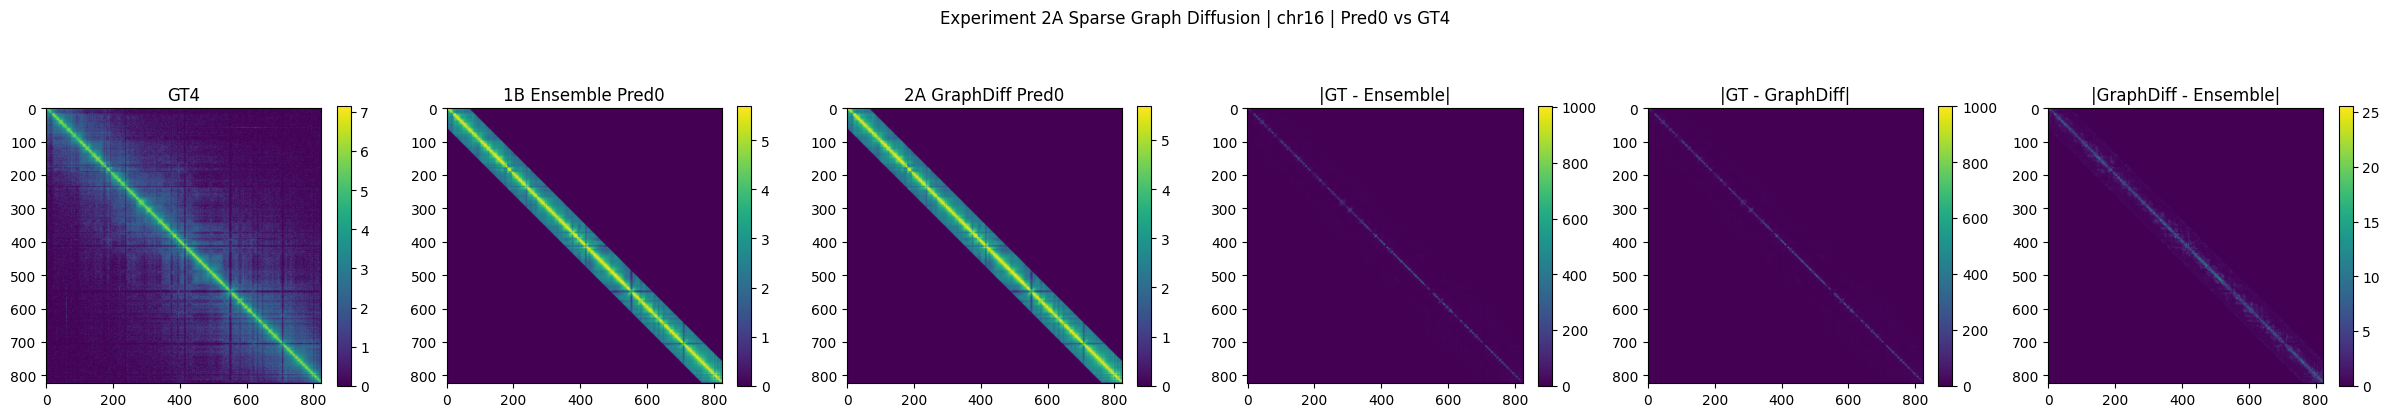

Saved image: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/images/exp2A_visual_pred0_gt4_dataset5_chr16.png


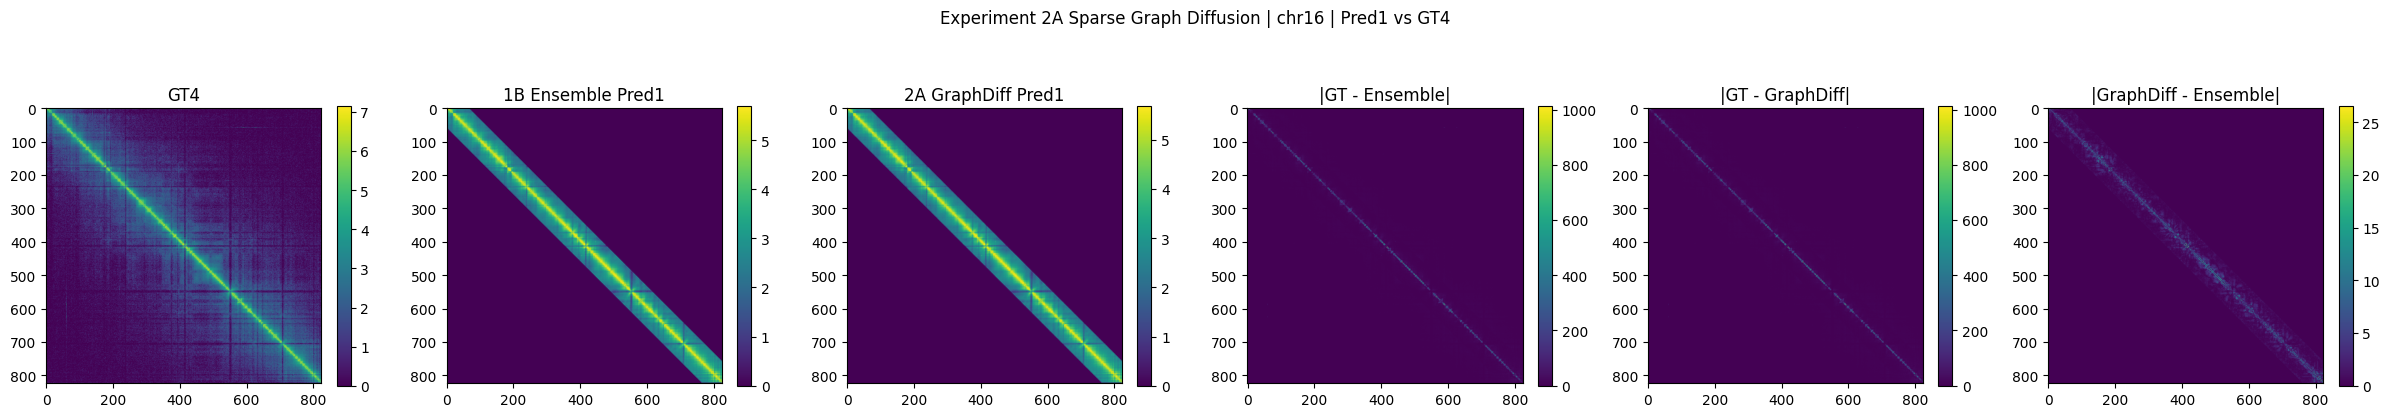

Saved image: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/images/exp2A_visual_pred1_gt4_dataset5_chr16.png


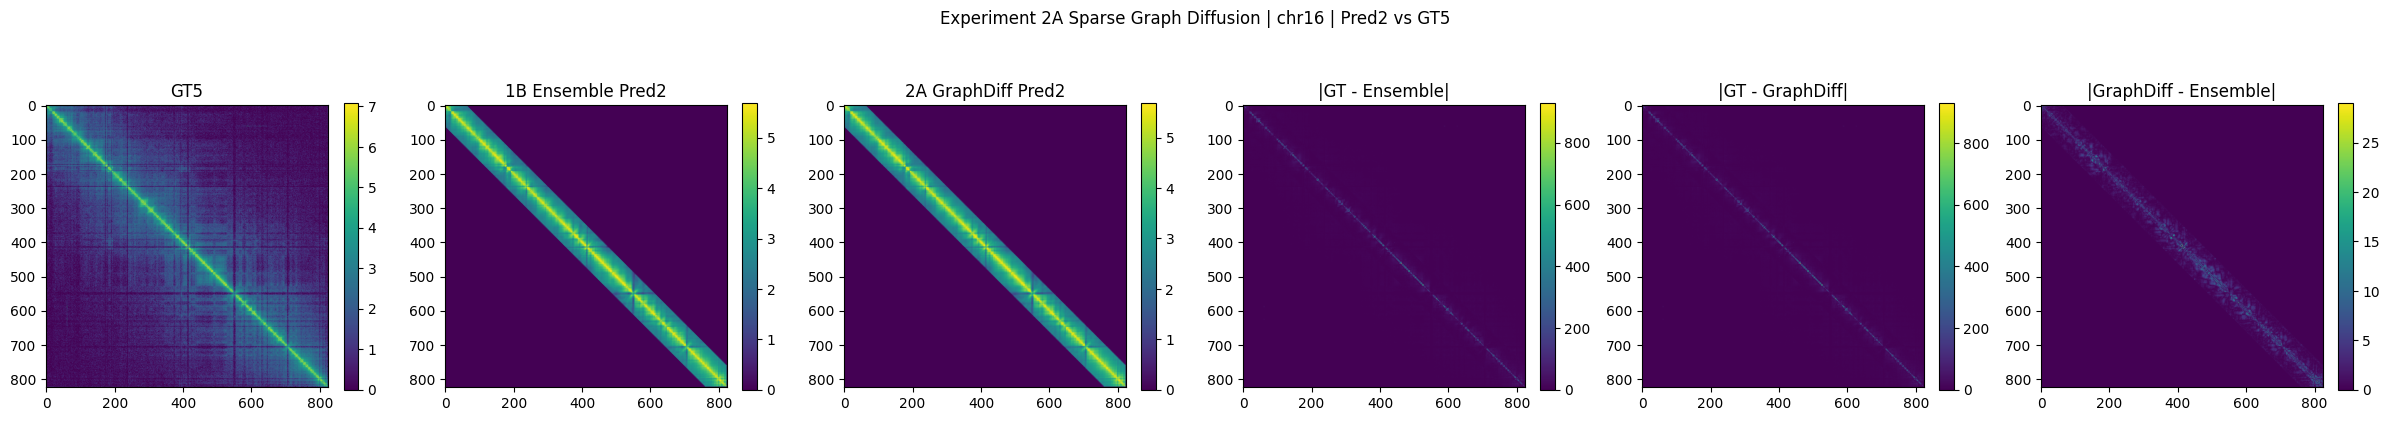

Saved image: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/images/exp2A_visual_pred2_gt5_dataset5_chr16.png


In [ ]:
# ============================================================
# EXPERIMENT 2A: Save GT vs Ensemble vs GraphDiff images
# ============================================================

def plot_hic(x):
    return np.log1p(np.maximum(x, 0))


for h, gt_idx in enumerate(gt_match):
    gt_h = gt[gt_idx]
    ensemble_h = ensemble_mean[h]
    graph_h = graphdiff_preds[h]

    ensemble_error = np.abs(gt_h - ensemble_h)
    graph_error = np.abs(gt_h - graph_h)
    graph_change = np.abs(graph_h - ensemble_h)

    plt.figure(figsize=(24, 4))

    plt.subplot(1, 6, 1)
    plt.imshow(plot_hic(gt_h))
    plt.title(f"GT{gt_idx}")
    plt.colorbar(fraction=0.046)

    plt.subplot(1, 6, 2)
    plt.imshow(plot_hic(ensemble_h))
    plt.title(f"1B Ensemble Pred{h}")
    plt.colorbar(fraction=0.046)

    plt.subplot(1, 6, 3)
    plt.imshow(plot_hic(graph_h))
    plt.title(f"2A GraphDiff Pred{h}")
    plt.colorbar(fraction=0.046)

    plt.subplot(1, 6, 4)
    plt.imshow(ensemble_error)
    plt.title("|GT - Ensemble|")
    plt.colorbar(fraction=0.046)

    plt.subplot(1, 6, 5)
    plt.imshow(graph_error)
    plt.title("|GT - GraphDiff|")
    plt.colorbar(fraction=0.046)

    plt.subplot(1, 6, 6)
    plt.imshow(graph_change)
    plt.title("|GraphDiff - Ensemble|")
    plt.colorbar(fraction=0.046)

    plt.suptitle(
        f"Experiment 2A Sparse Graph Diffusion | {chrom} | Pred{h} vs GT{gt_idx}",
        y=1.05
    )

    plt.tight_layout()

    fig_path = os.path.join(
        exp2a_img_dir,
        f"exp2A_visual_pred{h}_gt{gt_idx}_dataset{dataset_id}_{chrom}.png"
    )

    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved image:", fig_path)

,k,alpha,steps,Mean PCC,Mean SSIM,Mean PSNR,Mean MAE,Mean MSE,Mean Change MAE,Mean Change MSE,Rank PCC,Rank SSIM,Rank PSNR,Rank MAE,Rank MSE,Composite Rank
0,4,0.95,2,0.900690,0.952925,36.184229,3.963190,386.260976,0.201647,0.853300,1.0,2.0,1.0,2.0,1.0,1.4
1,4,0.95,3,0.900689,0.952925,36.184208,3.963201,386.262868,0.201653,0.853343,2.0,3.0,2.0,3.0,2.0,2.4
2,4,0.95,4,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853343,3.0,4.0,3.0,4.0,3.0,3.4
3,4,0.95,5,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853344,4.0,5.0,4.0,4.0,3.0,4.0
4,4,0.95,6,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853344,5.0,8.0,5.0,4.0,3.0,5.0
5,4,0.95,8,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853344,6.0,6.0,6.0,4.0,3.0,5.0
6,4,0.95,10,0.900689,0.952925,36.184207,3.963202,386.262899,0.201653,0.853344,6.0,6.0,6.0,4.0,3.0,5.0
7,4,0.95,1,0.900684,0.952925,36.184063,3.963128,386.275940,0.201643,0.854097,8.0,1.0,8.0,1.0,8.0,5.2
8,8,0.95,1,0.900526,0.952913,36.175449,3.965266,387.040649,0.201751,0.852827,9.0,9.0,9.0,9.0,9.0,9.0
9,8,0.95,2,0.900501,0.952911,36.174708,3.965516,387.106852,0.201865,0.853324,10.0,10.0,10.0,10.0,10.0,10.0


Saved top 20 hyperparameter settings:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results/exp2A_top20_hyperparameters_dataset5_chr16.csv


,alpha,Composite Rank,Mean PCC,Mean SSIM,Mean PSNR,Mean MAE,Mean MSE
0,0.10,389.2,0.853969,0.948872,35.265047,4.322704,477.964040
1,0.20,366.2,0.860966,0.949453,35.380793,4.274980,465.326436
2,0.35,317.0,0.870649,0.950280,35.550310,4.205674,447.407562
3,0.50,267.8,0.879426,0.951048,35.715455,4.139263,430.605723
4,0.65,214.4,0.887352,0.951748,35.876452,4.076204,414.828735
5,0.80,135.8,0.894445,0.952375,36.033015,4.017235,400.040375
6,0.90,39.8,0.898705,0.952750,36.134504,3.980546,390.738454
7,0.95,1.4,0.900690,0.952925,36.184229,3.963128,386.260976


,k,Composite Rank,Mean PCC,Mean SSIM,Mean PSNR,Mean MAE,Mean MSE
0,4,1.4,0.900690,0.952925,36.184229,3.963128,386.260976
1,8,9.0,0.900526,0.952913,36.175449,3.965266,387.040649
2,12,17.0,0.900100,0.952883,36.159664,3.969189,388.436737
3,16,25.0,0.899677,0.952847,36.143436,3.974321,389.883260
4,24,37.8,0.899103,0.952774,36.118573,3.984348,392.113281
5,32,53.8,0.898805,0.952714,36.102194,3.992121,393.590942
6,40,68.0,0.898655,0.952664,36.090879,3.997862,394.616740
7,48,80.0,0.898584,0.952622,36.082694,4.002146,395.363363
8,64,95.6,0.898556,0.952564,36.071693,4.007560,396.376038
9,80,100.4,0.898593,0.952548,36.064565,4.010152,397.040700


,steps,Composite Rank,Mean PCC,Mean SSIM,Mean PSNR,Mean MAE,Mean MSE
0,1,5.2,0.900684,0.952925,36.184063,3.963128,386.275940
1,2,1.4,0.900690,0.952925,36.184229,3.963190,386.260976
2,3,2.4,0.900689,0.952925,36.184208,3.963201,386.262868
3,4,3.4,0.900689,0.952925,36.184207,3.963202,386.262899
4,5,4.0,0.900689,0.952925,36.184207,3.963202,386.262899
5,6,5.0,0.900689,0.952925,36.184207,3.963202,386.262899
6,8,5.0,0.900689,0.952925,36.184207,3.963202,386.262899
7,10,5.0,0.900689,0.952925,36.184207,3.963202,386.262899


Saved alpha sensitivity: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results/exp2A_alpha_sensitivity_dataset5_chr16.csv
Saved k sensitivity: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results/exp2A_k_sensitivity_dataset5_chr16.csv
Saved step sensitivity: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/results/exp2A_step_sensitivity_dataset5_chr16.csv


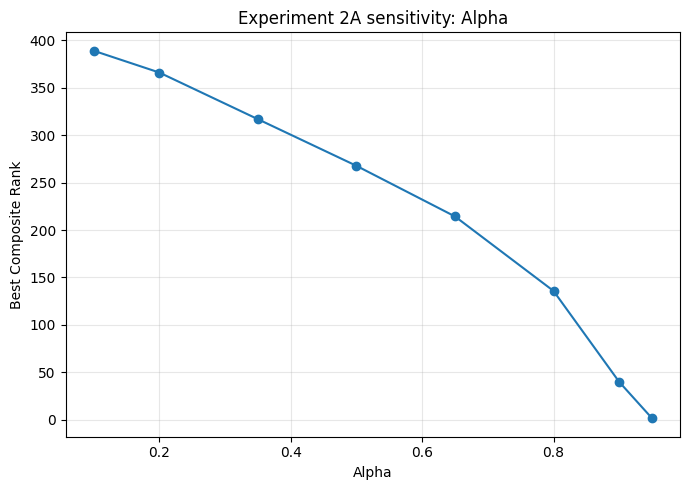

Saved sensitivity figure: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/images/exp2A_sensitivity_alpha_dataset5_chr16.png


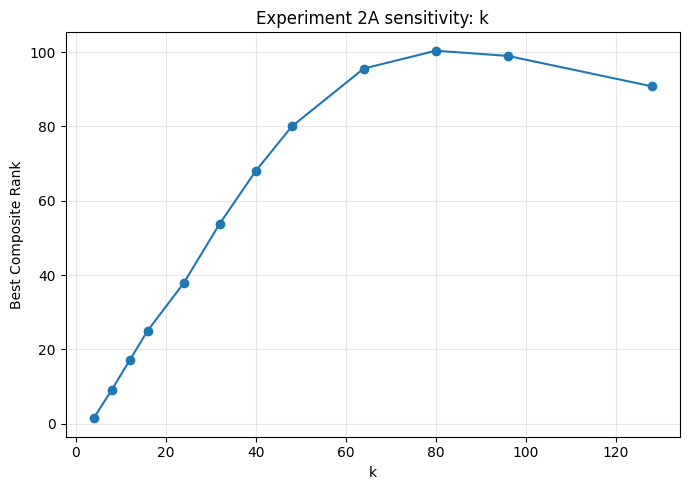

Saved sensitivity figure: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/images/exp2A_sensitivity_k_dataset5_chr16.png


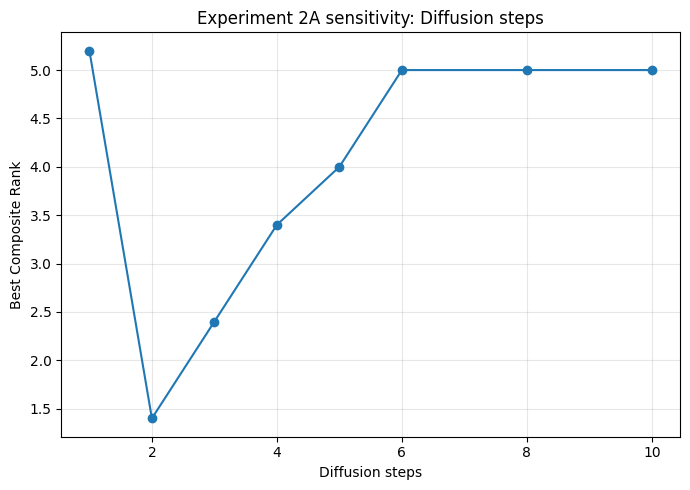

Saved sensitivity figure: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2A_sparse_graph_diffusion/images/exp2A_sensitivity_steps_dataset5_chr16.png


In [88]:
# ============================================================
# Save hyperparameter sensitivity tables and plots
# ============================================================

if "sweep_summary_df" not in globals():
    sweep_csv_path = os.path.join(
        exp2a_results_dir,
        f"exp2A_hyperparameter_sweep_dataset{dataset_id}_{chrom}.csv"
    )

    if os.path.exists(sweep_csv_path):
        sweep_summary_df = pd.read_csv(sweep_csv_path)
    else:
        raise FileNotFoundError(
            "sweep_summary_df not found and sweep CSV not found:\n"
            + sweep_csv_path
        )


# ------------------------------------------------------------
# Save top 20 hyperparameter settings
# ------------------------------------------------------------

top20_df = sweep_summary_df.head(20).copy()

top20_csv_path = os.path.join(
    exp2a_results_dir,
    f"exp2A_top20_hyperparameters_dataset{dataset_id}_{chrom}.csv"
)

top20_df.to_csv(top20_csv_path, index=False)

display(top20_df.round(6))

print("Saved top 20 hyperparameter settings:")
print(top20_csv_path)


# ------------------------------------------------------------
# Sensitivity summaries
# ------------------------------------------------------------

alpha_sensitivity_df = (
    sweep_summary_df
    .groupby("alpha", as_index=False)
    .agg({
        "Composite Rank": "min",
        "Mean PCC": "max",
        "Mean SSIM": "max",
        "Mean PSNR": "max",
        "Mean MAE": "min",
        "Mean MSE": "min",
    })
    .sort_values("alpha")
)

k_sensitivity_df = (
    sweep_summary_df
    .groupby("k", as_index=False)
    .agg({
        "Composite Rank": "min",
        "Mean PCC": "max",
        "Mean SSIM": "max",
        "Mean PSNR": "max",
        "Mean MAE": "min",
        "Mean MSE": "min",
    })
    .sort_values("k")
)

step_sensitivity_df = (
    sweep_summary_df
    .groupby("steps", as_index=False)
    .agg({
        "Composite Rank": "min",
        "Mean PCC": "max",
        "Mean SSIM": "max",
        "Mean PSNR": "max",
        "Mean MAE": "min",
        "Mean MSE": "min",
    })
    .sort_values("steps")
)


# ------------------------------------------------------------
# Save sensitivity CSV files
# ------------------------------------------------------------

alpha_sensitivity_csv_path = os.path.join(
    exp2a_results_dir,
    f"exp2A_alpha_sensitivity_dataset{dataset_id}_{chrom}.csv"
)

k_sensitivity_csv_path = os.path.join(
    exp2a_results_dir,
    f"exp2A_k_sensitivity_dataset{dataset_id}_{chrom}.csv"
)

step_sensitivity_csv_path = os.path.join(
    exp2a_results_dir,
    f"exp2A_step_sensitivity_dataset{dataset_id}_{chrom}.csv"
)

alpha_sensitivity_df.to_csv(alpha_sensitivity_csv_path, index=False)
k_sensitivity_df.to_csv(k_sensitivity_csv_path, index=False)
step_sensitivity_df.to_csv(step_sensitivity_csv_path, index=False)

display(alpha_sensitivity_df.round(6))
display(k_sensitivity_df.round(6))
display(step_sensitivity_df.round(6))

print("Saved alpha sensitivity:", alpha_sensitivity_csv_path)
print("Saved k sensitivity:", k_sensitivity_csv_path)
print("Saved step sensitivity:", step_sensitivity_csv_path)


# ------------------------------------------------------------
# Sensitivity plots
# ------------------------------------------------------------

sensitivity_items = [
    ("alpha", alpha_sensitivity_df, "Alpha", alpha_sensitivity_csv_path),
    ("k", k_sensitivity_df, "k", k_sensitivity_csv_path),
    ("steps", step_sensitivity_df, "Diffusion steps", step_sensitivity_csv_path),
]

for col, df, label, _ in sensitivity_items:
    plt.figure(figsize=(7, 5))

    plt.plot(
        df[col],
        df["Composite Rank"],
        marker="o"
    )

    plt.xlabel(label)
    plt.ylabel("Best Composite Rank")
    plt.title(f"Experiment 2A sensitivity: {label}")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    fig_path = os.path.join(
        exp2a_img_dir,
        f"exp2A_sensitivity_{col}_dataset{dataset_id}_{chrom}.png"
    )

    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Saved sensitivity figure:", fig_path)

# **Experiment 2B: Uncertainty-Guided Residual Refiner**

In [92]:
if "ensemble_mean" not in globals():
    raise RuntimeError("ensemble_mean not found. Run Experiment 1B first.")

if "ensemble_std" not in globals():
    raise RuntimeError("ensemble_std not found. Run Experiment 1B first.")

if "gt" not in globals():
    raise RuntimeError("gt not found. Load ground truth first.")

In [93]:
# -----------------------------
# Folder setup
# -----------------------------
exp2b_dir = os.path.join(run_dir, "exp2B_uncertainty_guided_refiner")
exp2b_patch_dir = os.path.join(exp2b_dir, "patches")
exp2b_model_dir = os.path.join(exp2b_dir, "models")
exp2b_results_dir = os.path.join(exp2b_dir, "results")
exp2b_logs_dir = os.path.join(exp2b_dir, "logs")
exp2b_img_dir = os.path.join(exp2b_dir, "images")

for d in [
    exp2b_dir,
    exp2b_patch_dir,
    exp2b_model_dir,
    exp2b_results_dir,
    exp2b_logs_dir,
    exp2b_img_dir,
]:
    os.makedirs(d, exist_ok=True)

Check with different parameters :
learning_rate: {1e-4, 3e-4, 1e-3}
channels: {16, 32}
blocks: {2, 4}
stride: {32, 64}

In [ ]:
# -----------------------------
# Refiner hyperparameters
# -----------------------------
PATCH = 64
STRIDE = 32 
MAX_BAND_OFFSET = 2 

REFINER_EPOCHS = 90   # checked with 15, 30, 45, 60, 75, 90 -> evaluate result then
REFINER_BATCH_SIZE = 32
REFINER_LR = 1e-3
REFINER_CHANNELS = 32
REFINER_BLOCKS = 4

TRAIN_FRAC = 0.80
RANDOM_SEED = 42

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Experiment 2B folder:", exp2b_dir)
print("Device:", device)
print("ensemble_mean shape:", ensemble_mean.shape)
print("ensemble_std shape:", ensemble_std.shape)
print("gt shape:", gt.shape)
print("gt_match:", gt_match)

Experiment 2B folder: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner
Device: cuda
ensemble_mean shape: (3, 824, 824)
ensemble_std shape: (3, 824, 824)
gt shape: (6, 824, 824)
gt_match: [4, 4, 5]


In [145]:
# ============================================================
# EXPERIMENT 2B: Extract overlapping near-diagonal patches
# ============================================================

def extract_refiner_patches(mean_stack, std_stack, gt_stack, gt_match,
                            patch=64, stride=32, max_band_offset=2):
    X_list = []
    y_list = []
    meta = []

    num_h, H, W = mean_stack.shape
    starts = list(range(0, min(H, W) - patch + 1, stride))

    for h in range(num_h):
        gt_idx = gt_match[h]

        for r in starts:
            for offset in range(-max_band_offset, max_band_offset + 1):
                c = r + offset * stride

                if c < 0 or c + patch > W:
                    continue

                mean_patch = mean_stack[h, r:r+patch, c:c+patch]
                std_patch = std_stack[h, r:r+patch, c:c+patch]
                gt_patch = gt_stack[gt_idx, r:r+patch, c:c+patch]

                if np.sum(np.abs(mean_patch)) == 0 and np.sum(np.abs(gt_patch)) == 0:
                    continue

                X = np.stack([mean_patch, std_patch], axis=0).astype(np.float32)
                y = gt_patch[None, :, :].astype(np.float32)

                X_list.append(X)
                y_list.append(y)
                meta.append((h, r, c))

    X_all = np.stack(X_list, axis=0)
    y_all = np.stack(y_list, axis=0)

    return X_all, y_all, meta


X_all, y_all, meta_all = extract_refiner_patches(
    ensemble_mean,
    ensemble_std,
    gt,
    gt_match,
    patch=PATCH,
    stride=STRIDE,
    max_band_offset=MAX_BAND_OFFSET
)

print("X_all shape:", X_all.shape)  # (N, 2, 64, 64)
print("y_all shape:", y_all.shape)  # (N, 1, 64, 64)
print("meta entries:", len(meta_all))

X_patch_path = os.path.join(exp2b_patch_dir, f"exp2B_X_patches_dataset{dataset_id}_{chrom}.npy")
y_patch_path = os.path.join(exp2b_patch_dir, f"exp2B_y_patches_dataset{dataset_id}_{chrom}.npy")
meta_path = os.path.join(exp2b_patch_dir, f"exp2B_patch_meta_dataset{dataset_id}_{chrom}.json")

np.save(X_patch_path, X_all)
np.save(y_patch_path, y_all)

with open(meta_path, "w") as f:
    json.dump([list(m) for m in meta_all], f)

print("Saved X patches:", X_patch_path)
print("Saved y patches:", y_patch_path)
print("Saved meta:", meta_path)

X_all shape: (342, 2, 64, 64)
y_all shape: (342, 1, 64, 64)
meta entries: 342
Saved X patches: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/patches/exp2B_X_patches_dataset5_chr16.npy
Saved y patches: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/patches/exp2B_y_patches_dataset5_chr16.npy
Saved meta: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/patches/exp2B_patch_meta_dataset5_chr16.json


In [146]:
# ============================================================
# EXPERIMENT 2B: Dataset and DataLoader
# ============================================================

class RefinerPatchDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).float()

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


rng = np.random.default_rng(RANDOM_SEED)
indices = np.arange(X_all.shape[0])
rng.shuffle(indices)

n_train = int(TRAIN_FRAC * len(indices))
train_idx = indices[:n_train]
val_idx = indices[n_train:]

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]

train_ds = RefinerPatchDataset(X_train, y_train)
val_ds = RefinerPatchDataset(X_val, y_val)

train_loader = DataLoader(
    train_ds,
    batch_size=REFINER_BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_ds,
    batch_size=REFINER_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train patches:", len(train_ds))
print("Validation patches:", len(val_ds))

Train patches: 273
Validation patches: 69


In [147]:
# ============================================================
# EXPERIMENT 2B: Residual CNN refiner
# ============================================================

class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
        )

        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        return self.act(x + self.net(x))


class UncertaintyGuidedResidualRefiner(nn.Module):
    """
    Input:  [mu, sigma], shape (B, 2, H, W)
    Output: refined map = mu + residual
    """
    def __init__(self, channels=32, num_blocks=4):
        super().__init__()

        self.input_conv = nn.Sequential(
            nn.Conv2d(2, channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

        self.blocks = nn.Sequential(
            *[ResidualBlock(channels) for _ in range(num_blocks)]
        )

        self.output_conv = nn.Conv2d(channels, 1, kernel_size=3, padding=1)

    def forward(self, x):
        mu = x[:, 0:1, :, :]
        feat = self.input_conv(x)
        feat = self.blocks(feat)
        residual = self.output_conv(feat)
        refined = mu + residual
        return refined


refiner = UncertaintyGuidedResidualRefiner(
    channels=REFINER_CHANNELS,
    num_blocks=REFINER_BLOCKS
).to(device)

num_params = sum(p.numel() for p in refiner.parameters() if p.requires_grad)

print(refiner)
print("Trainable parameters:", num_params)

UncertaintyGuidedResidualRefiner(
  (input_conv): Sequential(
    (0): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
  )
  (blocks): Sequential(
    (0): ResidualBlock(
      (net): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (act): ReLU(inplace=True)
    )
    (1): ResidualBlock(
      (net): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      )
      (act): ReLU(inplace=True)
    )
    (2): ResidualBlock(
      (net): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): ReLU(inplace=True)
        (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))

In [148]:
# ============================================================
# EXPERIMENT 2B: Train refiner
# ============================================================

criterion = nn.L1Loss()
optimizer = torch.optim.Adam(refiner.parameters(), lr=REFINER_LR)

best_val_loss = float("inf")
best_model_path = os.path.join(
    exp2b_model_dir,
    f"exp2B_best_refiner_dataset{dataset_id}_{chrom}.pt"
)

history = []

for epoch in range(1, REFINER_EPOCHS + 1):
    refiner.train()
    train_losses = []

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()
        pred = refiner(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    refiner.eval()
    val_losses = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            pred = refiner(xb)
            loss = criterion(pred, yb)
            val_losses.append(loss.item())

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))

    history.append({
        "epoch": epoch,
        "train_l1": train_loss,
        "val_l1": val_loss,
    })

    print(
        f"Epoch {epoch:02d}/{REFINER_EPOCHS} | "
        f"train L1={train_loss:.6f} | val L1={val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": refiner.state_dict(),
            "best_val_loss": best_val_loss,
            "epoch": epoch,
            "config": {
                "patch": PATCH,
                "stride": STRIDE,
                "max_band_offset": MAX_BAND_OFFSET,
                "channels": REFINER_CHANNELS,
                "blocks": REFINER_BLOCKS,
                "lr": REFINER_LR,
                "batch_size": REFINER_BATCH_SIZE,
                "epochs": REFINER_EPOCHS,
            }
        }, best_model_path)

        print("Saved new best model:", best_model_path)

history_df = pd.DataFrame(history)

history_csv_path = os.path.join(
    exp2b_results_dir,
    f"exp2B_training_history_dataset{dataset_id}_{chrom}_epoch_{REFINER_EPOCHS}.csv"
)

history_df.to_csv(history_csv_path, index=False)

print("Best validation L1:", best_val_loss)
print("Saved training history:", history_csv_path)

Epoch 01/90 | train L1=14.527528 | val L1=12.023307
Saved new best model: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/models/exp2B_best_refiner_dataset5_chr16.pt
Epoch 02/90 | train L1=13.411623 | val L1=11.255503
Saved new best model: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/models/exp2B_best_refiner_dataset5_chr16.pt
Epoch 03/90 | train L1=12.607481 | val L1=10.455662
Saved new best model: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/models/exp2B_best_refiner_dataset5_chr16.pt
Epoch 04/90 | train L1=11.909757 | val L1=9.793201
Saved new best model: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/models/exp2B_best_refiner_dataset5_chr16.pt
Epoch 05/90 | train L1=11.048319 

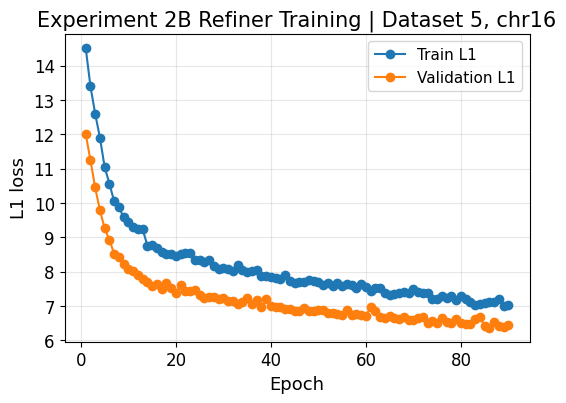

Saved training curve: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/images/exp2B_training_curve_dataset5_chr16_epoch_90.png


In [149]:
# ============================================================
# EXPERIMENT 2B: Training curve
# ============================================================

plt.figure(figsize=(6, 4))
plt.plot(history_df["epoch"], history_df["train_l1"], marker="o", label="Train L1")
plt.plot(history_df["epoch"], history_df["val_l1"], marker="o", label="Validation L1")
plt.xlabel("Epoch")
plt.ylabel("L1 loss")
plt.title(f"Experiment 2B Refiner Training | Dataset {dataset_id}, {chrom}")
plt.legend()
plt.grid(True, alpha=0.3)

loss_fig_path = os.path.join(
    exp2b_img_dir,
    f"exp2B_training_curve_dataset{dataset_id}_{chrom}_epoch_{REFINER_EPOCHS}.png"
)

plt.savefig(loss_fig_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Saved training curve:", loss_fig_path)

In [150]:
# ============================================================
# EXPERIMENT 2B: Predict refined patches
# ============================================================

checkpoint = torch.load(best_model_path, map_location=device)
refiner.load_state_dict(checkpoint["model_state_dict"])
refiner.eval()

all_ds = RefinerPatchDataset(X_all, y_all)
all_loader = DataLoader(
    all_ds,
    batch_size=REFINER_BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

refined_patches = []

with torch.no_grad():
    for xb, _ in all_loader:
        xb = xb.to(device)
        pred = refiner(xb)
        pred = torch.relu(pred)
        refined_patches.append(pred.cpu().numpy())

refined_patches = np.concatenate(refined_patches, axis=0)

print("refined_patches shape:", refined_patches.shape)

refined_patches_path = os.path.join(
    exp2b_results_dir,
    f"exp2B_refined_patches_dataset{dataset_id}_{chrom}_epoch_{REFINER_EPOCHS}.npy"
)

np.save(refined_patches_path, refined_patches)

print("Saved refined patches:", refined_patches_path)

refined_patches shape: (342, 1, 64, 64)
Saved refined patches: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/results/exp2B_refined_patches_dataset5_chr16_epoch_90.npy


In [151]:
# ============================================================
# EXPERIMENT 2B: Reconstruct full refined maps
# ============================================================

def reconstruct_refined_maps(refined_patches, meta, base_maps, patch=64):
    """
    Average overlapping refined patches.
    Regions not covered by extracted patches remain as ensemble_mean.
    """
    out = base_maps.copy().astype(np.float32)
    canvas = np.zeros_like(base_maps, dtype=np.float32)
    weight = np.zeros_like(base_maps, dtype=np.float32)

    for i, (h, r, c) in enumerate(meta):
        patch_pred = refined_patches[i, 0].astype(np.float32)

        canvas[h, r:r+patch, c:c+patch] += patch_pred
        weight[h, r:r+patch, c:c+patch] += 1.0

    mask = weight > 0
    out[mask] = canvas[mask] / weight[mask]

    # Symmetrize final maps
    for h in range(out.shape[0]):
        out[h] = 0.5 * (out[h] + out[h].T)

    out = np.maximum(out, 0.0)

    return out


refined_full = reconstruct_refined_maps(
    refined_patches,
    meta_all,
    base_maps=ensemble_mean,
    patch=PATCH
)

print("refined_full shape:", refined_full.shape)

refined_full_path = os.path.join(
    exp2b_results_dir,
    f"exp2B_refined_full_dataset{dataset_id}_{chrom}_epoch_{REFINER_EPOCHS}.npy"
)

np.save(refined_full_path, refined_full)

print("Saved refined full maps:", refined_full_path)

refined_full shape: (3, 824, 824)
Saved refined full maps: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/results/exp2B_refined_full_dataset5_chr16_epoch_90.npy


In [152]:
# ============================================================
# EXPERIMENT 2B: Evaluate refined full maps
# ============================================================

def evaluate_prediction_stack_2b(pred_stack, gt_stack, gt_match):
    rows = []

    for h, gt_idx in enumerate(gt_match):
        pred_h = pred_stack[h]
        gt_h = gt_stack[gt_idx]

        data_range = safe_data_range(gt_h)

        rows.append({
            "Horizon": f"Pred{h}",
            "Matched GT": f"GT{gt_idx}",
            "Matched GT Index": gt_idx,
            "PCC": pcc(pred_h, gt_h),
            "SSIM": ssim_metric(pred_h, gt_h, data_range=data_range),
            "PSNR": psnr_metric(gt_h, pred_h, data_range=data_range),
            "MAE": mean_absolute_error(gt_h.ravel(), pred_h.ravel()),
            "MSE": mean_squared_error(gt_h.ravel(), pred_h.ravel()),
        })

    return pd.DataFrame(rows)


refined_metrics_df = evaluate_prediction_stack_2b(
    refined_full,
    gt,
    gt_match
)

display(refined_metrics_df.round(4))

refined_metrics_path = os.path.join(
    exp2b_results_dir,
    f"exp2B_refined_metrics_dataset{dataset_id}_{chrom}_epoch_{REFINER_EPOCHS}.csv"
)

refined_metrics_df.to_csv(refined_metrics_path, index=False)

print("Saved refined metrics:", refined_metrics_path)

,Horizon,Matched GT,Matched GT Index,PCC,SSIM,PSNR,MAE,MSE
0,Pred0,GT4,4,0.9801,0.9852,44.1183,2.1566,64.5689
1,Pred1,GT4,4,0.9792,0.9846,43.6147,2.2072,72.5069
2,Pred2,GT5,5,0.9673,0.9654,42.8285,2.9056,74.3292


Saved refined metrics: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/results/exp2B_refined_metrics_dataset5_chr16_epoch_90.csv


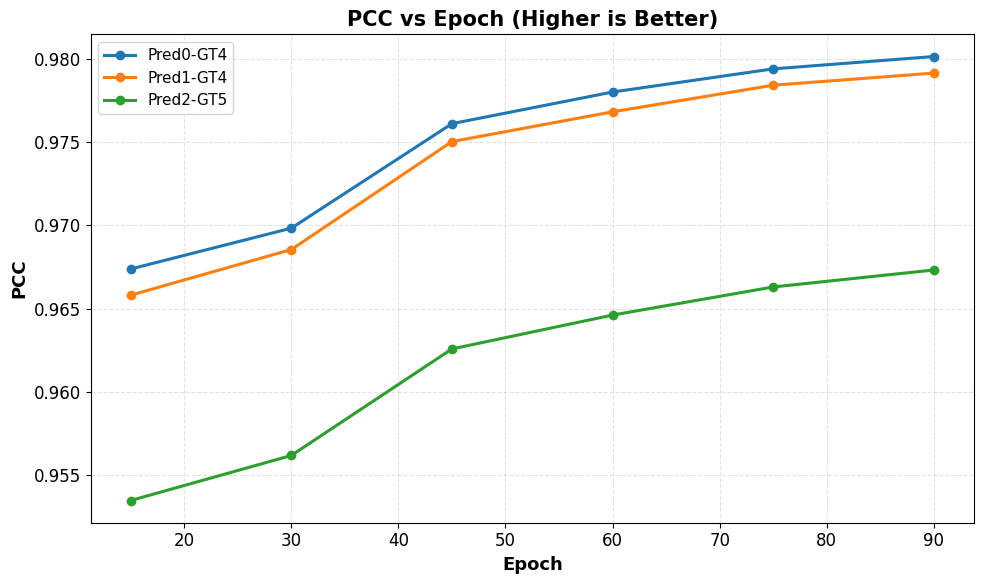

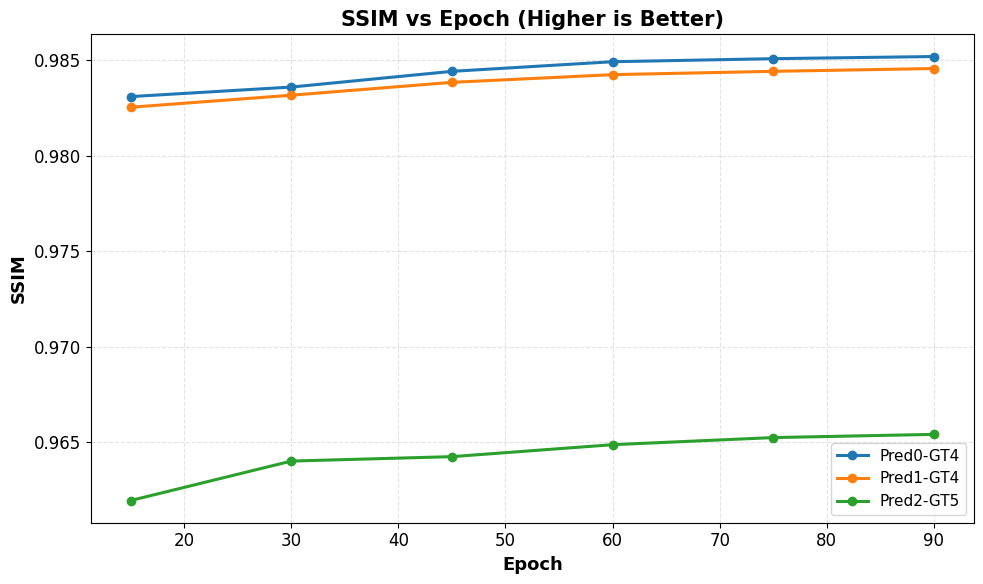

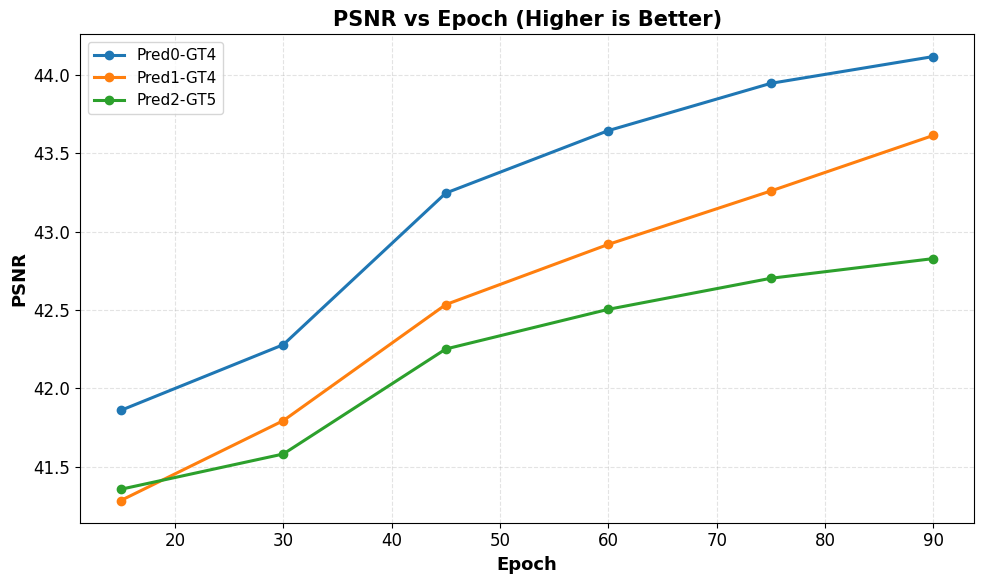

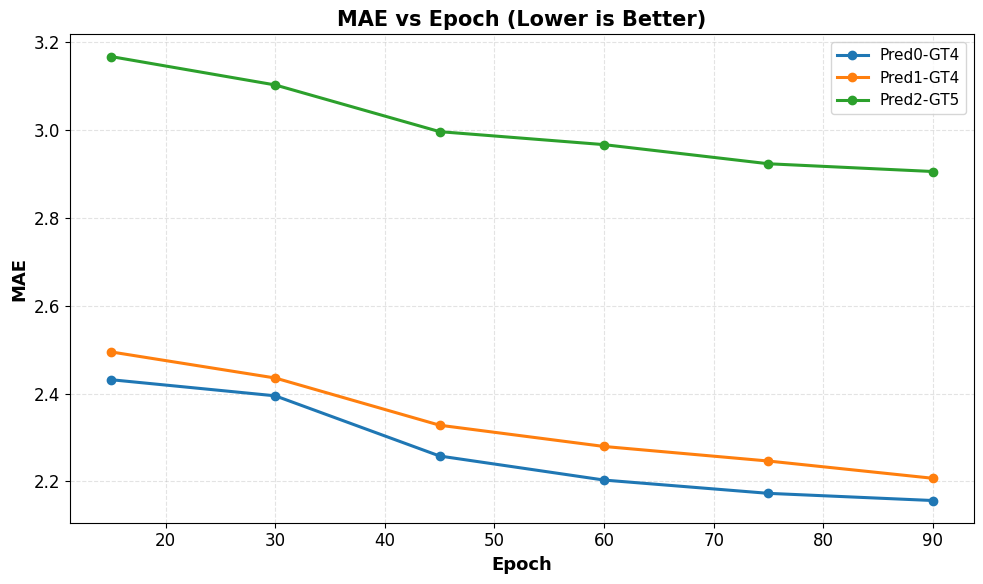

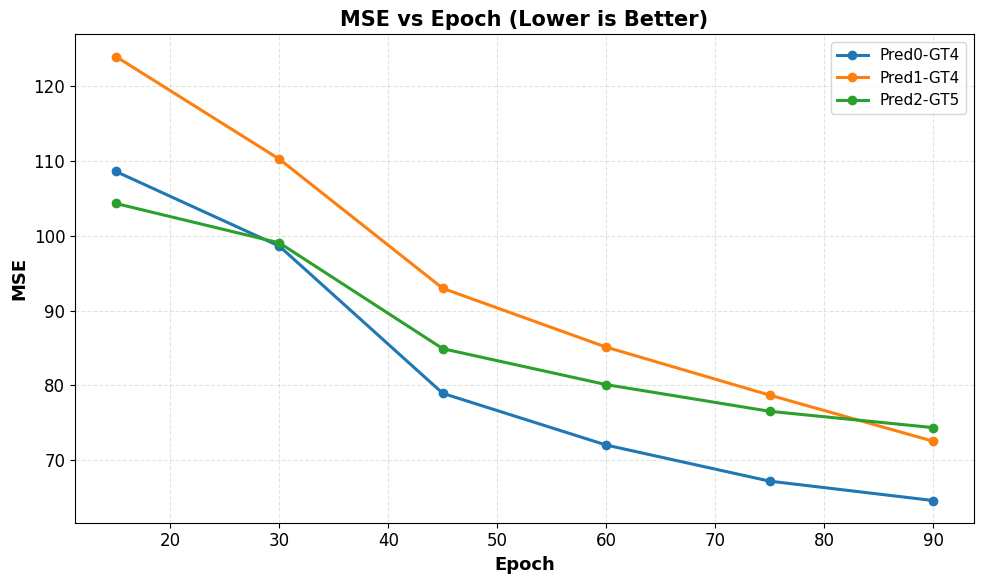

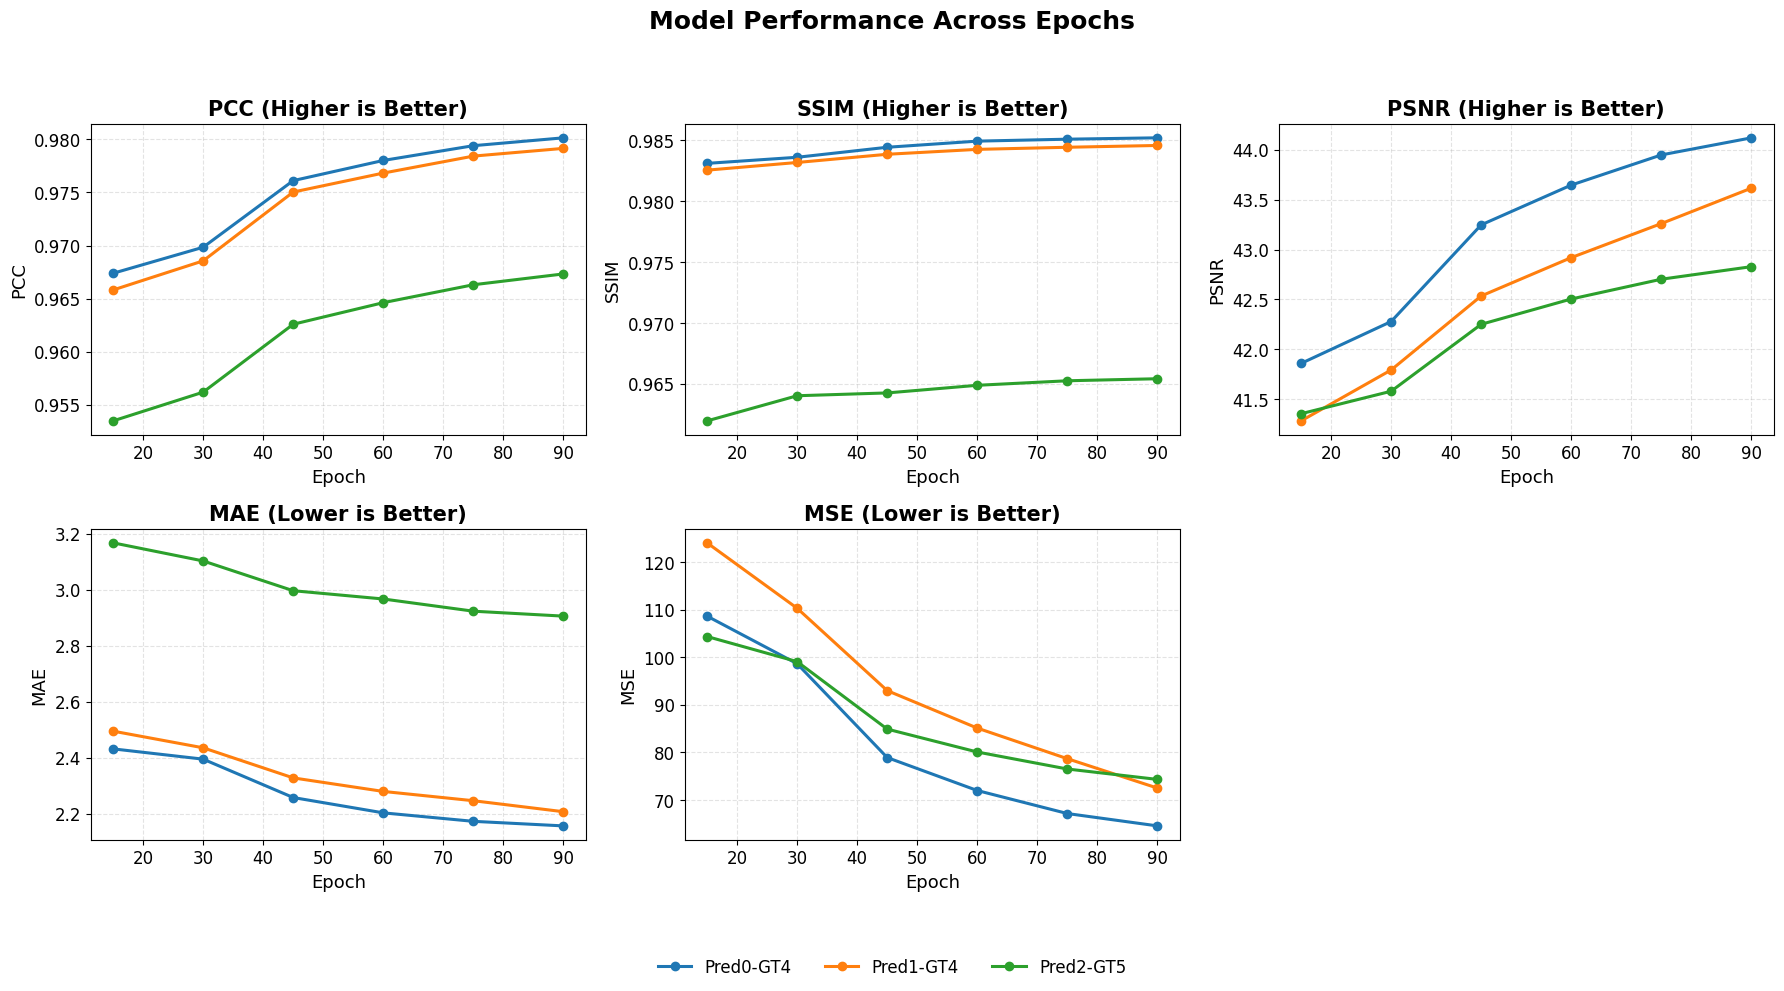

Done!
Separate metric graphs saved in: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/results/separate_metric_graphs
Dashboard saved as: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/results/epoch_vs_metrics_dashboard.png


In [153]:
# -----------------------------
# Epoch-wise Performance Metrics Visualization
# -----------------------------
prefix = f"exp2B_refined_metrics_dataset{dataset_id}_{chrom}_epoch_"
csv_files = [
    f for f in os.listdir(exp2b_results_dir)
    if f.startswith(prefix) and f.endswith('.csv')
]

all_data = []

for file in csv_files:
    file_path = os.path.join(exp2b_results_dir, file)
    epoch = int(re.search(r'epoch_(\d+)', file).group(1))

    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()
    df['Epoch'] = epoch
    df['Pair'] = (
        df['Horizon'].astype(str).str.strip()
        + '-'
        + df['Matched GT'].astype(str).str.strip()
    )

    all_data.append(df)

data = pd.concat(all_data, ignore_index=True)
data = data.sort_values(by='Epoch')

metrics = ['PCC', 'SSIM', 'PSNR', 'MAE', 'MSE']
pair_list = sorted(data['Pair'].unique())

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 13,
    'legend.fontsize': 11,
    'figure.titlesize': 18
})

# Create folder for saving graphs
save_dir = os.path.join(exp2b_results_dir, "separate_metric_graphs")
os.makedirs(save_dir, exist_ok=True)

# -----------------------------
# Save each metric separately
# -----------------------------
for metric in metrics:
    plt.figure(figsize=(10, 6))

    for pair in pair_list:
        subset = data[data['Pair'] == pair].sort_values('Epoch')

        plt.plot(
            subset['Epoch'],
            subset[metric],
            marker='o',
            linewidth=2.2,
            markersize=6,
            label=pair
        )

    if metric in ['MAE', 'MSE']:
        plt.title(f'{metric} vs Epoch (Lower is Better)', fontweight='bold')
    else:
        plt.title(f'{metric} vs Epoch (Higher is Better)', fontweight='bold')

    plt.xlabel('Epoch', fontweight='bold')
    plt.ylabel(metric, fontweight='bold')
    plt.grid(True, linestyle='--', alpha=0.35)
    plt.legend(loc='best', frameon=True)

    plt.tight_layout()

    save_path = os.path.join(save_dir, f'{metric}_vs_epoch.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

# -----------------------------
# Save one full dashboard image
# -----------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    ax = axes[i]

    for pair in pair_list:
        subset = data[data['Pair'] == pair].sort_values('Epoch')

        ax.plot(
            subset['Epoch'],
            subset[metric],
            marker='o',
            linewidth=2.2,
            markersize=6,
            label=pair
        )

    if metric in ['MAE', 'MSE']:
        ax.set_title(f'{metric} (Lower is Better)', fontweight='bold')
    else:
        ax.set_title(f'{metric} (Higher is Better)', fontweight='bold')

    ax.set_xlabel('Epoch')
    ax.set_ylabel(metric)
    ax.grid(True, linestyle='--', alpha=0.35)

# Last subplot empty
axes[-1].axis('off')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc='lower center',
    ncol=len(pair_list),
    frameon=False,
    fontsize=12
)

fig.suptitle(
    'Model Performance Across Epochs',
    fontweight='bold',
    y=0.98
)

plt.tight_layout(rect=[0, 0.08, 1, 0.95])

dashboard_path = os.path.join(exp2b_results_dir, 'epoch_vs_metrics_dashboard.png')
plt.savefig(dashboard_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("Done!")
print("Separate metric graphs saved in:", save_dir)
print("Dashboard saved as:", dashboard_path)

In [154]:
# ============================================================
# EXPERIMENT 2B: Compare methods
# ============================================================

method_rows = []

# Baseline
baseline_pred_path = os.path.join(run_dir, "pred_baseline.npy")
if os.path.exists(baseline_pred_path):
    baseline_pred = np.load(baseline_pred_path)
    baseline_metrics_df_2b = evaluate_prediction_stack_2b(baseline_pred, gt, gt_match)
    baseline_avg = baseline_metrics_df_2b[["PCC", "SSIM", "PSNR", "MAE", "MSE"]].mean()
    method_rows.append({"Method": "Baseline", **baseline_avg.to_dict()})
else:
    print("Baseline prediction not found:", baseline_pred_path)

# Ensemble mean
ensemble_metrics_df_2b = evaluate_prediction_stack_2b(ensemble_mean, gt, gt_match)
ensemble_avg = ensemble_metrics_df_2b[["PCC", "SSIM", "PSNR", "MAE", "MSE"]].mean()
method_rows.append({"Method": "Seeded ensemble mean", **ensemble_avg.to_dict()})

# GraphDiff from Experiment 2A
if "graphdiff_preds" in globals():
    graphdiff_metrics_df_2b = evaluate_prediction_stack_2b(graphdiff_preds, gt, gt_match)
    graphdiff_avg = graphdiff_metrics_df_2b[["PCC", "SSIM", "PSNR", "MAE", "MSE"]].mean()
    method_rows.append({"Method": "Graph diffusion", **graphdiff_avg.to_dict()})
else:
    print("graphdiff_preds not found. GraphDiff comparison skipped.")

# Refiner
refined_avg = refined_metrics_df[["PCC", "SSIM", "PSNR", "MAE", "MSE"]].mean()
method_rows.append({"Method": "Uncertainty-guided refiner", **refined_avg.to_dict()})

exp2b_compare_df = pd.DataFrame(method_rows)

display(exp2b_compare_df.round(4))

compare_path = os.path.join(
    exp2b_results_dir,
    f"exp2B_method_comparison_dataset{dataset_id}_{chrom}_epoch_{REFINER_EPOCHS}.csv"
)

exp2b_compare_df.to_csv(compare_path, index=False)

print("Saved 2B method comparison:", compare_path)

,Method,PCC,SSIM,PSNR,MAE,MSE
0,Baseline,0.9015,0.9529,36.2020,3.9639,384.5504
1,Seeded ensemble mean,0.9020,0.9530,36.2239,3.9550,382.6880
2,Graph diffusion,0.9007,0.9529,36.1842,3.9632,386.2610
3,Uncertainty-guided refiner,0.9755,0.9784,43.5205,2.4231,70.4683


Saved 2B method comparison: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp2B_uncertainty_guided_refiner/results/exp2B_method_comparison_dataset5_chr16_epoch_90.csv


In [ ]:
# ============================================================
# EXPERIMENT 3: Structure-Aware Final Evaluation
# 3A: TAD insulation proxy
# 3B: Peak-weighted L1
# 3C: GenomeDisco
# ============================================================

# **3A TAD insulation proxy loss**
# **3B Peak-weighted L1**

In [155]:
exp3_dir = os.path.join(run_dir, "exp3_structure_aware_final_evaluation")
exp3_results_dir = os.path.join(exp3_dir, "results")
exp3_img_dir = os.path.join(exp3_dir, "images")

os.makedirs(exp3_dir, exist_ok=True)
os.makedirs(exp3_results_dir, exist_ok=True)
os.makedirs(exp3_img_dir, exist_ok=True)

print("Experiment 3 folder:", exp3_dir)
print("Results:", exp3_results_dir)
print("Images:", exp3_img_dir)

Experiment 3 folder: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3_structure_aware_final_evaluation
Results: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3_structure_aware_final_evaluation/results
Images: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3_structure_aware_final_evaluation/images


In [156]:
# ============================================================
# EXPERIMENT 3: Load method outputs
# ============================================================

method_outputs = {}

# Baseline
baseline_pred_path = os.path.join(run_dir, "pred_baseline.npy")

method_outputs["Baseline"] = np.load(baseline_pred_path)

# Experiment 1B ensemble mean
method_outputs["Seeded ensemble mean"] = ensemble_mean

# Experiment 2A graph diffusion
method_outputs["Graph diffusion"] = graphdiff_preds


# Experiment 2B refiner
method_outputs["Uncertainty-guided refiner"] = refined_full

# GT
if "gt" not in globals():
    gt = np.load(gt_path)

print("Loaded methods:")
for name, arr in method_outputs.items():
    print(name, arr.shape)

print("GT shape:", gt.shape)
print("GT matching:", gt_match)

Loaded methods:
Baseline (3, 824, 824)
Seeded ensemble mean (3, 824, 824)
Graph diffusion (3, 824, 824)
Uncertainty-guided refiner (3, 824, 824)
GT shape: (6, 824, 824)
GT matching: [4, 4, 5]


In [157]:
# ============================================================
# EXPERIMENT 3A and 3B: Structure-aware metric functions
# ============================================================

def insulation_vector(mat, window=10):
    """
    TAD-insulation-style proxy.
    For each diagonal position i, compute mean contact intensity
    in a local square around the diagonal.
    """
    mat = np.asarray(mat, dtype=np.float32)
    n = mat.shape[0]
    values = []

    for i in range(n):
        lo = max(0, i - window)
        hi = min(n, i + window + 1)

        block = mat[lo:hi, lo:hi]

        if block.size == 0:
            values.append(0.0)
        else:
            values.append(float(np.mean(block)))

    return np.asarray(values, dtype=np.float32)


def tad_insulation_proxy_loss(pred, target, window=10):
    """
    L1 distance between insulation profiles.
    Lower is better.
    """
    pred_ins = insulation_vector(pred, window=window)
    target_ins = insulation_vector(target, window=window)

    return float(np.mean(np.abs(pred_ins - target_ins)))


def peak_weighted_l1(pred, target, percentile=95, peak_weight=5.0):
    """
    Peak-weighted L1.
    Errors on high-contact regions in GT receive higher weight.
    Lower is better.
    """
    pred = np.asarray(pred, dtype=np.float32)
    target = np.asarray(target, dtype=np.float32)

    threshold = np.percentile(target, percentile)

    weights = np.ones_like(target, dtype=np.float32)
    weights[target >= threshold] = peak_weight

    error = np.abs(pred - target)

    return float(np.sum(weights * error) / (np.sum(weights) + 1e-8))

In [158]:
# ============================================================
# EXPERIMENT 3: Run structure-aware evaluation
# ============================================================

# Reference from paper
INSULATION_WINDOW = 10
PEAK_PERCENTILE = 95
PEAK_WEIGHT = 5.0

exp3_rows = []

for method_name, pred_stack in method_outputs.items():
    for h, gt_idx in enumerate(gt_match):
        pred_h = pred_stack[h]
        gt_h = gt[gt_idx]

        tad_loss = tad_insulation_proxy_loss(
            pred_h,
            gt_h,
            window=INSULATION_WINDOW
        )

        peak_l1 = peak_weighted_l1(
            pred_h,
            gt_h,
            percentile=PEAK_PERCENTILE,
            peak_weight=PEAK_WEIGHT
        )

        exp3_rows.append({
            "Dataset": dataset_id,
            "Chromosome": chrom,
            "Method": method_name,
            "Horizon": f"Pred{h}",
            "Matched GT": f"GT{gt_idx}",
            "TAD insulation proxy loss": tad_loss,
            "Peak-weighted L1": peak_l1,
            "Insulation window": INSULATION_WINDOW,
            "Peak percentile": PEAK_PERCENTILE,
            "Peak weight": PEAK_WEIGHT,
        })

exp3_df = pd.DataFrame(exp3_rows)

display(exp3_df.round(6))

exp3_csv_path = os.path.join(
    exp3_results_dir,
    f"exp3_structure_aware_metrics_dataset{dataset_id}_{chrom}.csv"
)

exp3_df.to_csv(exp3_csv_path, index=False)

print("Saved Experiment 3 structure-aware metrics:")
print(exp3_csv_path)

,Dataset,Chromosome,Method,Horizon,Matched GT,TAD insulation proxy loss,Peak-weighted L1,Insulation window,Peak percentile,Peak weight
0,5,chr16,Baseline,Pred0,GT4,46.132545,8.831662,10,95,5.0
1,5,chr16,Baseline,Pred1,GT4,47.742050,10.006833,10,95,5.0
2,5,chr16,Baseline,Pred2,GT5,24.176744,10.067263,10,95,5.0
3,5,chr16,Seeded ensemble mean,Pred0,GT4,45.866096,8.797653,10,95,5.0
4,5,chr16,Seeded ensemble mean,Pred1,GT4,47.590775,9.990043,10,95,5.0
5,5,chr16,Seeded ensemble mean,Pred2,GT5,23.948357,10.036539,10,95,5.0
6,5,chr16,Graph diffusion,Pred0,GT4,45.737556,8.841707,10,95,5.0
7,5,chr16,Graph diffusion,Pred1,GT4,47.468002,10.029675,10,95,5.0
8,5,chr16,Graph diffusion,Pred2,GT5,23.840452,10.062655,10,95,5.0
9,5,chr16,Uncertainty-guided refiner,Pred0,GT4,6.072293,4.727798,10,95,5.0


Saved Experiment 3 structure-aware metrics:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3_structure_aware_final_evaluation/results/exp3_structure_aware_metrics_dataset5_chr16.csv


In [159]:
# ============================================================
# EXPERIMENT 3: Average structure-aware metrics by method
# ============================================================

exp3_summary_df = (
    exp3_df
    .groupby("Method")[["TAD insulation proxy loss", "Peak-weighted L1"]]
    .mean()
    .reset_index()
)

# Lower is better for both metrics
exp3_summary_df["Rank TAD"] = exp3_summary_df["TAD insulation proxy loss"].rank(
    ascending=True,
    method="min"
)

exp3_summary_df["Rank Peak"] = exp3_summary_df["Peak-weighted L1"].rank(
    ascending=True,
    method="min"
)

exp3_summary_df["Structure-aware average rank"] = exp3_summary_df[
    ["Rank TAD", "Rank Peak"]
].mean(axis=1)

exp3_summary_df = exp3_summary_df.sort_values(
    by="Structure-aware average rank"
).reset_index(drop=True)

display(exp3_summary_df.round(6))

exp3_summary_path = os.path.join(
    exp3_results_dir,
    f"exp3_structure_aware_summary_dataset{dataset_id}_{chrom}.csv"
)

exp3_summary_df.to_csv(exp3_summary_path, index=False)

print("Saved Experiment 3 summary:")
print(exp3_summary_path)

,Method,TAD insulation proxy loss,Peak-weighted L1,Rank TAD,Rank Peak,Structure-aware average rank
0,Uncertainty-guided refiner,7.827376,5.084238,1.0,1.0,1.0
1,Seeded ensemble mean,39.135076,9.608078,3.0,2.0,2.5
2,Graph diffusion,39.015337,9.644679,2.0,4.0,3.0
3,Baseline,39.350447,9.635253,4.0,3.0,3.5


Saved Experiment 3 summary:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3_structure_aware_final_evaluation/results/exp3_structure_aware_summary_dataset5_chr16.csv


In [161]:
# ============================================================
# FINAL EVALUATION: Combine standard and structure-aware metrics
# ============================================================

if "exp2b_compare_df" not in globals():
    raise RuntimeError("exp2b_compare_df not found. Run Experiment 2B method comparison first.")

final_eval_df = exp2b_compare_df.merge(
    exp3_summary_df[
        ["Method", "TAD insulation proxy loss", "Peak-weighted L1"]
    ],
    on="Method",
    how="left"
)

display(final_eval_df.round(6))

final_eval_path = os.path.join(
    exp3_results_dir,
    f"final_evaluation_standard_plus_structure_dataset{dataset_id}_{chrom}.csv"
)

final_eval_df.to_csv(final_eval_path, index=False)

print("Saved final evaluation table:")
print(final_eval_path)

,Method,PCC,SSIM,PSNR,MAE,MSE,TAD insulation proxy loss,Peak-weighted L1
0,Baseline,0.901505,0.952856,36.202048,3.963914,384.550418,39.350447,9.635253
1,Seeded ensemble mean,0.901961,0.952967,36.223873,3.954995,382.688017,39.135076,9.608078
2,Graph diffusion,0.900690,0.952925,36.184229,3.963190,386.260976,39.015337,9.644679
3,Uncertainty-guided refiner,0.975541,0.978394,43.520504,2.423107,70.468335,7.827376,5.084238


Saved final evaluation table:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3_structure_aware_final_evaluation/results/final_evaluation_standard_plus_structure_dataset5_chr16.csv


# **Experiment 3C: GenomeDISCO Evaluation**

In [162]:
# ============================================================
# EXPERIMENT 3C: GenomeDISCO Evaluation
# ============================================================

exp3c_dir = os.path.join(run_dir, "exp3C_genomedisco")
exp3c_input_dir = os.path.join(exp3c_dir, "inputs")
exp3c_output_dir = os.path.join(exp3c_dir, "outputs")
exp3c_results_dir = os.path.join(exp3c_dir, "results")
exp3c_logs_dir = os.path.join(exp3c_dir, "logs")
exp3c_contacts_dir = os.path.join(exp3c_input_dir, "batch_contacts")

for d in [exp3c_dir, exp3c_input_dir, exp3c_output_dir, exp3c_results_dir, exp3c_logs_dir, exp3c_contacts_dir]:
    os.makedirs(d, exist_ok=True)

print("Experiment 3C folder:", exp3c_dir)
print("Inputs:", exp3c_input_dir)
print("Outputs:", exp3c_output_dir)
print("Results:", exp3c_results_dir)
print("Logs:", exp3c_logs_dir)

Experiment 3C folder: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco
Inputs: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs
Outputs: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/outputs
Results: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/results
Logs: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/logs


In [163]:
!wget -q https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh -O /tmp/miniconda.sh
!bash /tmp/miniconda.sh -b -p /usr/local/miniconda
!echo "export PATH=/content/miniconda/bin/:$PATH" >> ~/.bashrc
!source ~/.bashrc

PREFIX=/usr/local/miniconda
Unpacking bootstrapper...
Unpacking payload...

Installing base environment...

Preparing transaction: ...working... done
Executing transaction: ...working... done
installation finished.
    You currently have a PYTHONPATH environment variable set. This may cause
    unexpected behavior when running the Python interpreter in Miniconda3.
    For best results, please verify that your PYTHONPATH only points to
    directories of packages that are compatible with the Python interpreter
    in Miniconda3: /usr/local/miniconda


In [164]:
%%bash
set -e

/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main
/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r

echo "Conda Terms of Service accepted."

accepted Terms of Service for https://repo.anaconda.com/pkgs/main
accepted Terms of Service for https://repo.anaconda.com/pkgs/r
Conda Terms of Service accepted.


In [165]:
%%bash
set -e

/usr/local/miniconda/bin/conda create -y -n gd_py2 python=2.7 pip numpy scipy pandas matplotlib scikit-learn

/usr/local/miniconda/bin/conda run -n gd_py2 python --version

Jupyter detected...
2 channel Terms of Service accepted
Retrieving notices: - \ | / - \ | / - \ | done
Channels:
 - defaults
Platform: linux-64
Solving environment: \ | done

## Package Plan ##

  environment location: /usr/local/miniconda/envs/gd_py2

  added / updated specs:
    - matplotlib
    - numpy
    - pandas
    - pip
    - python=2.7
    - scikit-learn
    - scipy


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _openmp_mutex-5.1          |           52_gnu           7 KB
    backports-1.1              |     pyhd3eb1b0_1           6 KB
    backports.functools_lru_cache-1.6.4|     pyhd3eb1b0_0           9 KB
    backports_abc-0.5          |             py_1          10 KB
    blas-1.0                   |              mkl           6 KB
    ca-certificates-2026.5.14  |       h06a4308_0         107 KB
    certifi-2020.6.20          |     pyhd3eb1b0_3   



==> WARNING: A newer version of conda exists. <==
    current version: 26.3.2
    latest version: 26.5.0

Please update conda by running

    $ conda update -n base -c defaults conda


Python 2.7.18 :: Anaconda, Inc.


In [166]:
%%bash
set -e

cd /content

if [ ! -d "/content/genomedisco" ]; then
    git clone https://github.com/kundajelab/genomedisco.git
fi

/usr/local/miniconda/bin/conda run -n gd_py2 pip install -e /content/genomedisco

/usr/local/miniconda/bin/conda run -n gd_py2 genomedisco --help || true

Obtaining file:///content/genomedisco
  Running setup.py develop for genomedisco
usage: genomedisco [-h] {run_all,preprocess,concordance,summary,cleanup} ...

positional arguments:
  {run_all,preprocess,concordance,summary,cleanup}
    run_all             Run all steps in the concordance analysis with this
                        single command
    preprocess          (step 1) split files by chromosome
    concordance         (step 2) compute concordance of replicate pairs
    summary             (step 3) create html report of the results
    cleanup             (step 4) clean up files

optional arguments:
  -h, --help            show this help message and exit


Cloning into 'genomedisco'...


In [167]:
%%bash
set -e

/usr/local/miniconda/bin/conda run -n gd_py2 pip install "psutil==5.9.8"

/usr/local/miniconda/bin/conda run -n gd_py2 python -c "import psutil; print('psutil installed:', psutil.__version__)"

('psutil installed:', '5.9.8')


In [168]:
# ============================================================
# EXPERIMENT 3C: Load method outputs
# ============================================================

method_outputs = {}

# Baseline
baseline_pred_path = os.path.join(run_dir, "pred_baseline.npy")
if os.path.exists(baseline_pred_path):
    method_outputs["Baseline"] = np.load(baseline_pred_path)
    print("Loaded Baseline:", baseline_pred_path)
else:
    print("Missing baseline:", baseline_pred_path)

# Seeded ensemble mean
if "ensemble_mean" not in globals():
    ensemble_mean_path = os.path.join(
        exp1b_results_dir,
        f"exp1B_ensemble_mean_dataset{dataset_id}_{chrom}.npy"
    )
    ensemble_mean = np.load(ensemble_mean_path)
    print("Loaded ensemble_mean:", ensemble_mean_path)

method_outputs["Seeded ensemble mean"] = ensemble_mean

# Graph diffusion
if "graphdiff_preds" in globals():
    method_outputs["Graph diffusion"] = graphdiff_preds
else:
    possible_graphdiff = glob.glob(
        os.path.join(run_dir, "**", "*graphdiff*final*.npy"),
        recursive=True
    )
    if len(possible_graphdiff) > 0:
        graphdiff_preds = np.load(possible_graphdiff[0])
        method_outputs["Graph diffusion"] = graphdiff_preds
        print("Loaded GraphDiff:", possible_graphdiff[0])
    else:
        print("GraphDiff not found. Skipping.")

# Uncertainty-guided refiner
if "refined_full" in globals():
    method_outputs["Uncertainty-guided refiner"] = refined_full
else:
    possible_refined = glob.glob(
        os.path.join(run_dir, "**", "*exp2B_refined_full*.npy"),
        recursive=True
    )
    if len(possible_refined) > 0:
        refined_full = np.load(possible_refined[0])
        method_outputs["Uncertainty-guided refiner"] = refined_full
        print("Loaded refined_full:", possible_refined[0])
    else:
        print("Refiner output not found. Skipping.")

# GT
if "gt" not in globals():
    gt = np.load(gt_path)

gt_match = [int(x) for x in gt_match]

print("\nLoaded methods:")
for name, arr in method_outputs.items():
    print(name, arr.shape)

print("GT shape:", gt.shape)
print("GT matching:", gt_match)

Loaded Baseline: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/pred_baseline.npy

Loaded methods:
Baseline (3, 824, 824)
Seeded ensemble mean (3, 824, 824)
Graph diffusion (3, 824, 824)
Uncertainty-guided refiner (3, 824, 824)
GT shape: (6, 824, 824)
GT matching: [4, 4, 5]


In [169]:
# ============================================================
# EXPERIMENT 3C: GenomeDISCO parameter file
# ============================================================

gd_params_path = os.path.join(exp3c_input_dir, "genomedisco_parameters.txt")

params_text = """GenomeDISCO|subsampling\tlowest
GenomeDISCO|tmin\t3
GenomeDISCO|tmax\t3
GenomeDISCO|norm\tsqrtvc
GenomeDISCO|scoresByStep\tno
GenomeDISCO|removeDiag\tyes
GenomeDISCO|transition\tyes
SGE|text\t"-l h_vmem=3G"
slurm|text\t"--mem 3G"
"""

with open(gd_params_path, "w") as f:
    f.write(params_text)

print("Saved GenomeDISCO parameters:")
print(gd_params_path)
print(params_text)

Saved GenomeDISCO parameters:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs/genomedisco_parameters.txt
GenomeDISCO|subsampling	lowest
GenomeDISCO|tmin	3
GenomeDISCO|tmax	3
GenomeDISCO|norm	sqrtvc
GenomeDISCO|scoresByStep	no
GenomeDISCO|removeDiag	yes
GenomeDISCO|transition	yes
SGE|text	"-l h_vmem=3G"
slurm|text	"--mem 3G"



In [170]:
# ============================================================
# EXPERIMENT 3C: Helper functions
# ============================================================

def sanitize_name(name):
    name = str(name).replace(" ", "_")
    name = re.sub(r"[^A-Za-z0-9_]+", "_", name)
    return name


def offdiag_signal(mat):
    mat = np.asarray(mat, dtype=np.float64)
    mat = np.nan_to_num(mat, nan=0.0, posinf=0.0, neginf=0.0)
    mat[mat < 0] = 0.0
    mat = mat.copy()
    np.fill_diagonal(mat, 0.0)
    return float(np.sum(mat))


def write_bins_file_for_patch(bins_path, chrom_name="chrPatch", patch_size=60, resolution=40000):
    """
    GenomeDISCO bins format:
    chr start end name
    """
    with gzip.open(bins_path, "wt") as f:
        for i in range(patch_size):
            start = i * resolution
            end = (i + 1) * resolution
            bin_name = f"bin{i}"
            f.write(f"{chrom_name}\t{start}\t{end}\t{bin_name}\n")


def write_contact_file_from_patch_gz(mat, contact_path, chrom_name="chrPatch", eps=1e-8):
    """
    GenomeDISCO contact map format:
    chr1 bin1 chr2 bin2 value

    Contact files are written as gzip because GenomeDISCO reads them with gzip.
    """
    mat = np.asarray(mat, dtype=np.float64)
    mat = np.nan_to_num(mat, nan=0.0, posinf=0.0, neginf=0.0)
    mat[mat < 0] = 0.0

    n = mat.shape[0]

    with gzip.open(contact_path, "wt") as f:
        for i in range(n):
            for j in range(i, n):
                value = mat[i, j]
                if value > eps:
                    f.write(
                        f"{chrom_name}\tbin{i}\t{chrom_name}\tbin{j}\t{value:.8f}\n"
                    )


def get_common_valid_diagonal_patches(method_outputs, gt, gt_match, patch_size=60, stride=60):
    """
    Select diagonal patches where GT and all methods have non-zero off-diagonal signal.
    This gives a fair common patch set across methods.
    """
    valid_by_horizon = {}

    for h, gt_idx in enumerate(gt_match):
        H, W = gt[gt_idx].shape
        starts = list(range(0, min(H, W) - patch_size + 1, stride))

        valid_coords = []

        for r in starts:
            c = r
            gt_patch = gt[gt_idx, r:r+patch_size, c:c+patch_size]

            if offdiag_signal(gt_patch) <= 0:
                continue

            all_methods_valid = True

            for method_name, pred_stack in method_outputs.items():
                pred_patch = pred_stack[h, r:r+patch_size, c:c+patch_size]
                if offdiag_signal(pred_patch) <= 0:
                    all_methods_valid = False
                    break

            if all_methods_valid:
                valid_coords.append((r, c))

        valid_by_horizon[h] = valid_coords
        print(f"Horizon Pred{h} / GT{gt_idx}: valid common patches = {len(valid_coords)}")

    return valid_by_horizon

In [171]:
# ============================================================
# EXPERIMENT 3C: Build official GenomeDISCO batch input files
# ============================================================

GD_PATCH_SIZE = 64
GD_STRIDE = 32
GD_RESOLUTION = 40000
GD_CHROM_NAME = "chrPatch"

# Optional: for testing, set MAX_PATCHES_PER_HORIZON = 3
# For full evaluation, set to None
MAX_PATCHES_PER_HORIZON = None

# Clean previous batch contacts
if os.path.exists(exp3c_contacts_dir):
    shutil.rmtree(exp3c_contacts_dir)
os.makedirs(exp3c_contacts_dir, exist_ok=True)

batch_dir = os.path.join(exp3c_input_dir, "batch")
if os.path.exists(batch_dir):
    shutil.rmtree(batch_dir)
os.makedirs(batch_dir, exist_ok=True)

batch_bins_path = os.path.join(batch_dir, "bins.bed.gz")
batch_metadata_samples_path = os.path.join(batch_dir, "metadata.samples")
batch_metadata_pairs_path = os.path.join(batch_dir, "metadata.pairs")
pair_map_path = os.path.join(batch_dir, f"genomedisco_pair_map_dataset{dataset_id}_{chrom}.csv")

write_bins_file_for_patch(
    batch_bins_path,
    chrom_name=GD_CHROM_NAME,
    patch_size=GD_PATCH_SIZE,
    resolution=GD_RESOLUTION
)

valid_by_horizon = get_common_valid_diagonal_patches(
    method_outputs,
    gt,
    gt_match,
    patch_size=GD_PATCH_SIZE,
    stride=GD_STRIDE
)

metadata_sample_rows = []
metadata_pair_rows = []
pair_map_rows = []
seen_samples = set()

for h, gt_idx in enumerate(gt_match):
    coords = valid_by_horizon[h]

    if MAX_PATCHES_PER_HORIZON is not None:
        coords = coords[:MAX_PATCHES_PER_HORIZON]

    for pidx, (r, c) in enumerate(coords):
        gt_patch = gt[gt_idx, r:r+GD_PATCH_SIZE, c:c+GD_PATCH_SIZE]

        gt_sample = f"gt_h{h}_p{pidx}"
        gt_contact_path = os.path.join(exp3c_contacts_dir, f"{gt_sample}.contacts.gz")

        if gt_sample not in seen_samples:
            write_contact_file_from_patch_gz(
                gt_patch,
                gt_contact_path,
                chrom_name=GD_CHROM_NAME
            )
            metadata_sample_rows.append((gt_sample, gt_contact_path))
            seen_samples.add(gt_sample)

        for method_name, pred_stack in method_outputs.items():
            method_safe = sanitize_name(method_name)
            pred_sample = f"{method_safe}_h{h}_p{pidx}"
            pred_contact_path = os.path.join(exp3c_contacts_dir, f"{pred_sample}.contacts.gz")

            pred_patch = pred_stack[h, r:r+GD_PATCH_SIZE, c:c+GD_PATCH_SIZE]

            write_contact_file_from_patch_gz(
                pred_patch,
                pred_contact_path,
                chrom_name=GD_CHROM_NAME
            )

            metadata_sample_rows.append((pred_sample, pred_contact_path))
            metadata_pair_rows.append((pred_sample, gt_sample))

            pair_map_rows.append({
                "Sample1": pred_sample,
                "Sample2": gt_sample,
                "Dataset": dataset_id,
                "Chromosome": chrom,
                "Method": method_name,
                "Horizon": f"Pred{h}",
                "Matched GT": f"GT{gt_idx}",
                "Matched GT Index": gt_idx,
                "Patch index": pidx,
                "Patch row": r,
                "Patch col": c,
            })

# Write metadata.samples
with open(batch_metadata_samples_path, "w") as f:
    for sample_name, sample_path in metadata_sample_rows:
        f.write(f"{sample_name}\t{sample_path}\n")

# Write metadata.pairs
with open(batch_metadata_pairs_path, "w") as f:
    for s1, s2 in metadata_pair_rows:
        f.write(f"{s1}\t{s2}\n")

pair_map_df = pd.DataFrame(pair_map_rows)
pair_map_df.to_csv(pair_map_path, index=False)

print("GenomeDISCO batch input created.")
print("Number of samples:", len(metadata_sample_rows))
print("Number of pairs:", len(metadata_pair_rows))
print("Bins:", batch_bins_path)
print("metadata.samples:", batch_metadata_samples_path)
print("metadata.pairs:", batch_metadata_pairs_path)
print("pair map:", pair_map_path)

display(pair_map_df.head())

Horizon Pred0 / GT4: valid common patches = 24
Horizon Pred1 / GT4: valid common patches = 24
Horizon Pred2 / GT5: valid common patches = 24
GenomeDISCO batch input created.
Number of samples: 360
Number of pairs: 288
Bins: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs/batch/bins.bed.gz
metadata.samples: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs/batch/metadata.samples
metadata.pairs: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs/batch/metadata.pairs
pair map: /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs/batch/genomedisco_pair_map_dataset5_chr16.csv


,Sample1,Sample2,Dataset,Chromosome,Method,Horizon,Matched GT,Matched GT Index,Patch index,Patch row,Patch col
0,Baseline_h0_p0,gt_h0_p0,5,chr16,Baseline,Pred0,GT4,4,0,0,0
1,Seeded_ensemble_mean_h0_p0,gt_h0_p0,5,chr16,Seeded ensemble mean,Pred0,GT4,4,0,0,0
2,Graph_diffusion_h0_p0,gt_h0_p0,5,chr16,Graph diffusion,Pred0,GT4,4,0,0,0
3,Uncertainty_guided_refiner_h0_p0,gt_h0_p0,5,chr16,Uncertainty-guided refiner,Pred0,GT4,4,0,0,0
4,Baseline_h0_p1,gt_h0_p1,5,chr16,Baseline,Pred0,GT4,4,1,32,32


In [172]:
# ============================================================
# EXPERIMENT 3C: Run official GenomeDISCO batch
# ============================================================

batch_outdir = os.path.join(exp3c_output_dir, "batch_output")

if os.path.exists(batch_outdir):
    shutil.rmtree(batch_outdir)

os.makedirs(batch_outdir, exist_ok=True)

cmd = [
    "/usr/local/miniconda/bin/conda", "run", "-n", "gd_py2",
    "genomedisco", "run_all",
    "--metadata_samples", batch_metadata_samples_path,
    "--metadata_pairs", batch_metadata_pairs_path,
    "--bins", batch_bins_path,
    "--parameters_file", gd_params_path,
    "--outdir", batch_outdir,
    "--concise_analysis"
]

print("Running official GenomeDISCO batch:")
print(" ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True)

stdout_path = os.path.join(exp3c_logs_dir, "genomedisco_batch_stdout.txt")
stderr_path = os.path.join(exp3c_logs_dir, "genomedisco_batch_stderr.txt")

with open(stdout_path, "w") as f:
    f.write(result.stdout)

with open(stderr_path, "w") as f:
    f.write(result.stderr)

print("Return code:", result.returncode)

print("\nSTDOUT tail:")
print(result.stdout[-5000:])

print("\nSTDERR tail:")
print(result.stderr[-5000:])

if result.returncode != 0:
    print("GenomeDISCO batch failed. Logs:")
    print(stdout_path)
    print(stderr_path)
    raise RuntimeError("GenomeDISCO batch run failed.")
else:
    print("GenomeDISCO batch run completed successfully.")

Running official GenomeDISCO batch:
/usr/local/miniconda/bin/conda run -n gd_py2 genomedisco run_all --metadata_samples /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs/batch/metadata.samples --metadata_pairs /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs/batch/metadata.pairs --bins /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs/batch/bins.bed.gz --parameters_file /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/inputs/genomedisco_parameters.txt --outdir /content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/outputs/batch_output --concise_analysis
Return code: 0

STDOUT tail:
certainty_guided_refiner_h2_p6/Uncertainty_guided_refiner_h2_p6.chrPatch.gz
GenomeDISCO | Sun May 

In [173]:
# ============================================================
# EXPERIMENT 3C: Parse official GenomeDISCO batch results
# ============================================================

score_path = os.path.join(
    batch_outdir,
    "scores",
    "reproducibility.genomewide.txt"
)

if not os.path.exists(score_path):
    score_candidates = glob.glob(os.path.join(batch_outdir, "scores", "*.txt"))
    print("Available score files:")
    for f in score_candidates:
        print(f)
    raise FileNotFoundError(f"Expected score file not found: {score_path}")

print("Reading score file:")
print(score_path)

scores_df = pd.read_csv(score_path, sep="\t")

# Remove '#' from header if present
scores_df.columns = [c.replace("#", "") for c in scores_df.columns]

display(scores_df.head())

pair_map_df = pd.read_csv(pair_map_path)

genomedisco_patch_df = pair_map_df.merge(
    scores_df,
    on=["Sample1", "Sample2"],
    how="left"
)

if genomedisco_patch_df["GenomeDISCO"].isna().any():
    missing_count = genomedisco_patch_df["GenomeDISCO"].isna().sum()
    print("Warning: missing GenomeDISCO scores:", missing_count)

display(genomedisco_patch_df.head())

patch_scores_path = os.path.join(
    exp3c_results_dir,
    f"exp3C_official_genomedisco_patch_scores_dataset{dataset_id}_{chrom}.csv"
)

genomedisco_patch_df.to_csv(patch_scores_path, index=False)

print("Saved patch-level official GenomeDISCO scores:")
print(patch_scores_path)

Reading score file:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/outputs/batch_output/scores/reproducibility.genomewide.txt


,Sample1,Sample2,GenomeDISCO
0,Baseline_h0_p0,gt_h0_p0,0.767
1,Seeded_ensemble_mean_h0_p0,gt_h0_p0,0.769
2,Graph_diffusion_h0_p0,gt_h0_p0,0.766
3,Uncertainty_guided_refiner_h0_p0,gt_h0_p0,0.902
4,Baseline_h0_p1,gt_h0_p1,0.758


,Sample1,Sample2,Dataset,Chromosome,Method,Horizon,Matched GT,Matched GT Index,Patch index,Patch row,Patch col,GenomeDISCO
0,Baseline_h0_p0,gt_h0_p0,5,chr16,Baseline,Pred0,GT4,4,0,0,0,0.767
1,Seeded_ensemble_mean_h0_p0,gt_h0_p0,5,chr16,Seeded ensemble mean,Pred0,GT4,4,0,0,0,0.769
2,Graph_diffusion_h0_p0,gt_h0_p0,5,chr16,Graph diffusion,Pred0,GT4,4,0,0,0,0.766
3,Uncertainty_guided_refiner_h0_p0,gt_h0_p0,5,chr16,Uncertainty-guided refiner,Pred0,GT4,4,0,0,0,0.902
4,Baseline_h0_p1,gt_h0_p1,5,chr16,Baseline,Pred0,GT4,4,1,32,32,0.758


Saved patch-level official GenomeDISCO scores:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/results/exp3C_official_genomedisco_patch_scores_dataset5_chr16.csv


In [174]:
# ============================================================
# EXPERIMENT 3C: Summarize official GenomeDISCO scores
# ============================================================

genomedisco_horizon_summary_df = (
    genomedisco_patch_df
    .groupby(["Method", "Horizon", "Matched GT"])["GenomeDISCO"]
    .agg(["mean", "std", "min", "median", "max", "count"])
    .reset_index()
    .rename(columns={
        "mean": "GenomeDISCO mean",
        "std": "GenomeDISCO std",
        "min": "GenomeDISCO min",
        "median": "GenomeDISCO median",
        "max": "GenomeDISCO max",
        "count": "Num patches"
    })
)

display(genomedisco_horizon_summary_df.round(6))

horizon_summary_path = os.path.join(
    exp3c_results_dir,
    f"exp3C_official_genomedisco_horizon_summary_dataset{dataset_id}_{chrom}.csv"
)

genomedisco_horizon_summary_df.to_csv(horizon_summary_path, index=False)

print("Saved horizon summary:")
print(horizon_summary_path)


genomedisco_method_summary_df = (
    genomedisco_patch_df
    .groupby("Method")["GenomeDISCO"]
    .agg(["mean", "std", "min", "median", "max", "count"])
    .reset_index()
    .rename(columns={
        "mean": "GenomeDISCO mean",
        "std": "GenomeDISCO std",
        "min": "GenomeDISCO min",
        "median": "GenomeDISCO median",
        "max": "GenomeDISCO max",
        "count": "Num patch comparisons"
    })
)

genomedisco_method_summary_df["Rank GenomeDISCO"] = genomedisco_method_summary_df[
    "GenomeDISCO mean"
].rank(ascending=False, method="min")

genomedisco_method_summary_df = genomedisco_method_summary_df.sort_values(
    "Rank GenomeDISCO"
).reset_index(drop=True)

display(genomedisco_method_summary_df.round(6))

method_summary_path = os.path.join(
    exp3c_results_dir,
    f"exp3C_official_genomedisco_method_summary_dataset{dataset_id}_{chrom}.csv"
)

genomedisco_method_summary_df.to_csv(method_summary_path, index=False)

print("Saved method summary:")
print(method_summary_path)

,Method,Horizon,Matched GT,GenomeDISCO mean,GenomeDISCO std,GenomeDISCO min,GenomeDISCO median,GenomeDISCO max,Num patches
0,Baseline,Pred0,GT4,0.745375,0.032813,0.658,0.7420,0.807,24
1,Baseline,Pred1,GT4,0.687583,0.035915,0.604,0.7000,0.743,24
2,Baseline,Pred2,GT5,0.721875,0.041275,0.643,0.7225,0.782,24
3,Graph diffusion,Pred0,GT4,0.747042,0.033311,0.659,0.7445,0.805,24
4,Graph diffusion,Pred1,GT4,0.684583,0.035580,0.596,0.6940,0.746,24
5,Graph diffusion,Pred2,GT5,0.719917,0.040351,0.638,0.7260,0.777,24
6,Seeded ensemble mean,Pred0,GT4,0.748708,0.032616,0.664,0.7460,0.810,24
7,Seeded ensemble mean,Pred1,GT4,0.690125,0.035277,0.607,0.7010,0.742,24
8,Seeded ensemble mean,Pred2,GT5,0.725375,0.041032,0.647,0.7270,0.786,24
9,Uncertainty-guided refiner,Pred0,GT4,0.929375,0.012399,0.897,0.9320,0.944,24


Saved horizon summary:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/results/exp3C_official_genomedisco_horizon_summary_dataset5_chr16.csv


,Method,GenomeDISCO mean,GenomeDISCO std,GenomeDISCO min,GenomeDISCO median,GenomeDISCO max,Num patch comparisons,Rank GenomeDISCO
0,Uncertainty-guided refiner,0.919917,0.018803,0.862,0.9250,0.946,72,1.0
1,Seeded ensemble mean,0.721403,0.043373,0.607,0.7245,0.810,72,2.0
2,Baseline,0.718278,0.043469,0.604,0.7210,0.807,72,3.0
3,Graph diffusion,0.717181,0.044273,0.596,0.7215,0.805,72,4.0


Saved method summary:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/results/exp3C_official_genomedisco_method_summary_dataset5_chr16.csv


In [175]:
# ============================================================
# FINAL EVALUATION: Add official GenomeDISCO to final table
# ============================================================

if "final_eval_df" in globals():
    final_eval_with_genomedisco_df = final_eval_df.merge(
        genomedisco_method_summary_df[["Method", "GenomeDISCO mean"]],
        on="Method",
        how="left"
    )
else:
    # Fallback if final_eval_df was not created yet
    final_eval_with_genomedisco_df = genomedisco_method_summary_df[[
        "Method",
        "GenomeDISCO mean",
        "GenomeDISCO std",
        "Num patch comparisons"
    ]].copy()

display(final_eval_with_genomedisco_df.round(6))

final_eval_gd_path = os.path.join(
    exp3c_results_dir,
    f"final_evaluation_with_official_genomedisco_dataset{dataset_id}_{chrom}.csv"
)

final_eval_with_genomedisco_df.to_csv(final_eval_gd_path, index=False)

print("Saved final evaluation with official GenomeDISCO:")
print(final_eval_gd_path)

,Method,PCC,SSIM,PSNR,MAE,MSE,TAD insulation proxy loss,Peak-weighted L1,GenomeDISCO mean
0,Baseline,0.901505,0.952856,36.202048,3.963914,384.550418,39.350447,9.635253,0.718278
1,Seeded ensemble mean,0.901961,0.952967,36.223873,3.954995,382.688017,39.135076,9.608078,0.721403
2,Graph diffusion,0.900690,0.952925,36.184229,3.963190,386.260976,39.015337,9.644679,0.717181
3,Uncertainty-guided refiner,0.975541,0.978394,43.520504,2.423107,70.468335,7.827376,5.084238,0.919917


Saved final evaluation with official GenomeDISCO:
/content/drive/MyDrive/HiC_Dataset_Explore/runs/dataset_5/chr16/run_5_st11.cool_chr16_2026/exp3C_genomedisco/results/final_evaluation_with_official_genomedisco_dataset5_chr16.csv
